# **1. Importing Libraries**

**Documentation:**

We imported the necessary Python libraries for data analysis, visualization, preprocessing, and machine learning.

These libraries will be used to analyze the Riiid Answer Correctness Prediction dataset, identify patterns in students' question-answering behavior, and develop machine learning models capable of predicting learning performance.

The main objective is to support Rihla's weakness-detection feature by identifying historical areas where users may need additional learning support.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    log_loss
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


# **2. Loading and Inspecting the Dataset**

**Documentation:**

We used the Riiid Answer Correctness Prediction dataset, which contains records of students interacting with educational questions.

The dataset includes information about student identifiers, question identifiers, answer correctness, timestamps, and previous question interactions.

For this project, we initially selected a subset of 200,000 interaction records to reduce computational requirements while developing the machine learning pipeline.

We also loaded the question metadata dataset, which provides additional information about questions and their associated educational topics.

The purpose of this section is to examine the structure, dimensions, data types, and initial observations before performing data cleaning and exploratory analysis.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/Rihla_ML"

df = pd.read_csv(f"{PROJECT_DIR}/rihla_weakness_sample.csv")
questions = pd.read_csv(f"{PROJECT_DIR}/questions.csv")

print("Training Dataset Shape:", df.shape)
print("Questions Dataset Shape:", questions.shape)

print("\nFirst 5 Training Records:")
display(df.head())

print("\nFirst 5 Question Records:")
display(questions.head())

Training Dataset Shape: (200000, 10)
Questions Dataset Shape: (13523, 5)

First 5 Training Records:


,row_id,timestamp,user_id,content_id,content_type_id,task_container_id,user_answer,answered_correctly,prior_question_elapsed_time,prior_question_had_explanation
0,0,0,115,5692,0,1,3,1,NaN,NaN
1,1,56943,115,5716,0,2,2,1,37000.0,False
2,2,118363,115,128,0,0,0,1,55000.0,False
3,3,131167,115,7860,0,3,0,1,19000.0,False
4,4,137965,115,7922,0,4,1,1,11000.0,False



First 5 Question Records:


,question_id,bundle_id,correct_answer,part,tags
0,0,0,0,1,51 131 162 38
1,1,1,1,1,131 36 81
2,2,2,0,1,131 101 162 92
3,3,3,0,1,131 149 162 29
4,4,4,3,1,131 5 162 38


## **2.1 Dataset Structure**

**Documentation:**

We examined the column names, data types, and general information of both datasets.

This inspection helps us understand which attributes are available and identify potential preprocessing requirements.

Understanding the dataset structure is particularly important because Rihla's weakness-detection model will require features related to user performance, question difficulty, repeated mistakes, and previous learning interactions.

In [ ]:
print("Training Dataset Information:")
df.info()

print("\nQuestions Dataset Information:")
questions.info()

print("\nTraining Dataset Columns:")
print(df.columns.tolist())

print("\nQuestions Dataset Columns:")
print(questions.columns.tolist())

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 10 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   row_id                          200000 non-null  int64  
 1   timestamp                       200000 non-null  int64  
 2   user_id                         200000 non-null  int64  
 3   content_id                      200000 non-null  int64  
 4   content_type_id                 200000 non-null  int64  
 5   task_container_id               200000 non-null  int64  
 6   user_answer                     200000 non-null  int64  
 7   answered_correctly              200000 non-null  int64  
 8   prior_question_elapsed_time     195566 non-null  float64
 9   prior_question_had_explanation  199282 non-null  object 
dtypes: float64(1), int64(8), object(1)
memory usage: 15.3+ MB

Questions Dataset Information:
<class 'pandas.core.

## **2.2 Descriptive Statistics**

**Documentation:**

We generated descriptive statistics to understand the numerical characteristics of the dataset.

These statistics include the count, mean, standard deviation, minimum, maximum, and quartile values.

This analysis provides an initial understanding of the distribution of student interactions and helps identify unusual values that may require further investigation.

In [ ]:
print("Training Dataset Statistics:")
display(df.describe(include="all"))

print("\nQuestions Dataset Statistics:")
display(questions.describe(include="all"))

Training Dataset Statistics:


,row_id,timestamp,user_id,content_id,content_type_id,task_container_id,user_answer,answered_correctly,prior_question_elapsed_time,prior_question_had_explanation
count,200000.000000,2.000000e+05,2.000000e+05,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,195566.000000,199282
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,179434
mean,99999.500000,7.248828e+09,2.110047e+06,5152.003440,0.018580,887.069190,1.382845,0.646675,25306.215922,NaN
std,57735.171256,1.017401e+10,1.196915e+06,3899.598305,0.135037,1071.463179,1.194069,0.515410,18705.366331,NaN
min,0.000000,0.000000e+00,1.150000e+02,0.000000,0.000000,0.000000,-1.000000,-1.000000,0.000000,NaN
25%,49999.750000,6.784141e+08,1.282581e+06,1863.000000,0.000000,118.000000,0.000000,0.000000,16000.000000,NaN
50%,99999.500000,3.267151e+09,2.078569e+06,4976.000000,0.000000,430.000000,1.000000,1.000000,21000.000000,NaN
75%,149999.250000,1.018804e+10,3.194563e+06,7343.250000,0.000000,1297.000000,3.000000,1.000000,29000.000000,NaN



Questions Dataset Statistics:


,question_id,bundle_id,correct_answer,part,tags
count,13523.00000,13523.000000,13523.000000,13523.000000,13522
unique,NaN,NaN,NaN,NaN,1519
top,NaN,NaN,NaN,NaN,8
freq,NaN,NaN,NaN,NaN,738
mean,6761.00000,6760.510907,1.455298,4.264956,NaN
std,3903.89818,3903.857783,1.149707,1.652553,NaN
min,0.00000,0.000000,0.000000,1.000000,NaN
25%,3380.50000,3379.500000,0.000000,3.000000,NaN
50%,6761.00000,6761.000000,1.000000,5.000000,NaN
75%,10141.50000,10140.000000,3.000000,5.000000,NaN


# **3. Data Preparation and Cleaning**

## **3.1 Removing Non-Question Interactions**

**Documentation:**

The Riiid dataset contains two types of interactions: question attempts and lecture interactions.

Since our objective is to predict student answer correctness, we removed lecture interactions, identified by `content_type_id = 1`.

Only question interactions (`content_type_id = 0`) were retained for further analysis.

This ensures that the dataset contains valid question-answer records relevant to our weakness-detection model.

In [ ]:
print("Original Dataset Shape:", df.shape)

df_clean = df[df["content_type_id"] == 0].copy()

print("Dataset Shape After Removing Lectures:", df_clean.shape)

print("\nAnswer Distribution:")
print(df_clean["answered_correctly"].value_counts())

Original Dataset Shape: (200000, 10)
Dataset Shape After Removing Lectures: (196284, 10)

Answer Distribution:
answered_correctly
1    133051
0     63233
Name: count, dtype: int64


## **3.2 Handling Missing Values**

**Documentation:**

We examined the missing values in the dataset to determine an appropriate preprocessing strategy.

The `prior_question_elapsed_time` column contains missing values because the previous question's response time may be unavailable.

Similarly, `prior_question_had_explanation` contains missing values when information about previous explanations is unavailable.

To preserve the available student interaction records, we retained missing values for later imputation instead of immediately removing the affected rows.

The imputation parameters will be estimated from the training partition to avoid introducing data leakage.

In [ ]:
print("Missing Values in Training Dataset:")
display(df_clean.isnull().sum().to_frame("Missing Values"))

print("\nMissing Values in Questions Dataset:")
display(questions.isnull().sum().to_frame("Missing Values"))

Missing Values in Training Dataset:


,Missing Values
row_id,0
timestamp,0
user_id,0
content_id,0
content_type_id,0
task_container_id,0
user_answer,0
answered_correctly,0
prior_question_elapsed_time,718
prior_question_had_explanation,718



Missing Values in Questions Dataset:


,Missing Values
question_id,0
bundle_id,0
correct_answer,0
part,0
tags,1


## **3.3 Checking Duplicate Records**

**Documentation:**

We examined the dataset for duplicate interaction records.

Duplicate records may distort the training process by giving certain observations unnecessary importance.

Since each interaction is identified by a unique `row_id`, we checked for duplicate identifiers and repeated complete records.

We also verified that the question metadata contains unique question identifiers.

In [ ]:
print("Duplicate Training Records:", df_clean.duplicated().sum())

print("Duplicate Row IDs:", df_clean["row_id"].duplicated().sum())

print("Duplicate Question IDs:", questions["question_id"].duplicated().sum())

Duplicate Training Records: 0
Duplicate Row IDs: 0
Duplicate Question IDs: 0


## **3.4 Merging Question Metadata**

**Documentation:**

We merged the student interaction dataset with the question metadata dataset.

The merging process uses `content_id` from the training dataset and `question_id` from the questions dataset.

This operation adds question-related attributes, including educational sections and topic tags, to each student interaction.

These attributes will later help us analyze student performance across different knowledge areas.

In Rihla, a similar process will associate trivia answers with historical categories, periods, regions, and question difficulty.

In [ ]:
df_clean = df_clean.merge(
    questions,
    left_on="content_id",
    right_on="question_id",
    how="left",
    validate="many_to_one"
)

print("Dataset Shape After Merging:", df_clean.shape)

print("\nMissing Question Metadata:")
print(df_clean["question_id"].isnull().sum())

print("\nFirst 5 Records:")
display(df_clean.head())

Dataset Shape After Merging: (196284, 15)

Missing Question Metadata:
0

First 5 Records:


,row_id,timestamp,user_id,content_id,content_type_id,task_container_id,user_answer,answered_correctly,prior_question_elapsed_time,prior_question_had_explanation,question_id,bundle_id,correct_answer,part,tags
0,0,0,115,5692,0,1,3,1,NaN,NaN,5692,5692,3,5,151
1,1,56943,115,5716,0,2,2,1,37000.0,False,5716,5716,2,5,168
2,2,118363,115,128,0,0,0,1,55000.0,False,128,128,0,1,131 149 92
3,3,131167,115,7860,0,3,0,1,19000.0,False,7860,7860,0,1,131 104 81
4,4,137965,115,7922,0,4,1,1,11000.0,False,7922,7922,1,1,131 149 92


## **3.5 Verifying Data Integrity**

**Documentation:**

After filtering and merging the datasets, we verified the integrity of the resulting records.

We checked that the target variable contains only valid binary values, that all interactions have corresponding question metadata, and that no duplicate interaction identifiers were introduced.

These checks help ensure that the dataset is suitable for subsequent exploratory analysis and machine learning.

In [ ]:
print("Target Values:")
print(df_clean["answered_correctly"].value_counts())

print("\nUnmatched Questions:")
print(df_clean["question_id"].isnull().sum())

print("\nDuplicate Row IDs:")
print(df_clean["row_id"].duplicated().sum())

print("\nFinal Dataset Shape:")
print(df_clean.shape)

assert df_clean["answered_correctly"].isin([0, 1]).all()
assert df_clean["question_id"].notna().all()
assert not df_clean["row_id"].duplicated().any()

print("\nData integrity checks passed!")

Target Values:
answered_correctly
1    133051
0     63233
Name: count, dtype: int64

Unmatched Questions:
0

Duplicate Row IDs:
0

Final Dataset Shape:
(196284, 15)

Data integrity checks passed!


# **4. Exploratory Data Analysis (EDA)**

**Documentation:**

Exploratory Data Analysis was performed to understand the characteristics and patterns of the Riiid Answer Correctness Prediction dataset.

The analysis focuses on student performance, answer correctness, question difficulty, educational topics, and learning behavior.

Statistical summaries and visualizations were used to investigate relationships between the available variables and identify potential predictors of answer correctness.

These findings will guide the feature engineering and machine learning stages of Rihla's weakness-detection pipeline.

## **4.1 Distribution of Correct and Incorrect Answers**

**Documentation:**

We analyzed the distribution of correct and incorrect answers to understand the balance of the target variable.

The target variable, `answered_correctly`, contains two classes:

- 0: Incorrect answer
- 1: Correct answer

Understanding the class distribution is important because an imbalanced dataset may affect model training and evaluation.

A count plot was used to visualize the number of observations belonging to each class.

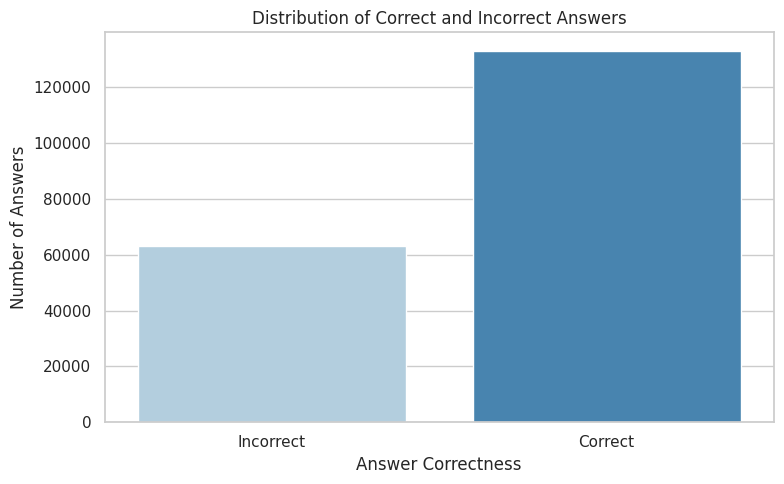

Answer Distribution:


,count
answered_correctly,
0,63233
1,133051


Overall Accuracy: 67.78 %


In [ ]:
answer_counts = df_clean["answered_correctly"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="answered_correctly",
    hue="answered_correctly",
    palette="Blues",
    legend=False
)

plt.title("Distribution of Correct and Incorrect Answers")
plt.xlabel("Answer Correctness")
plt.ylabel("Number of Answers")
plt.xticks([0, 1], ["Incorrect", "Correct"])
plt.tight_layout()
plt.show()

print("Answer Distribution:")
display(answer_counts)

print(
    "Overall Accuracy:",
    round(df_clean["answered_correctly"].mean() * 100, 2),
    "%"
)

## **4.2 Student Performance Across Educational Topics**

**Documentation:**

We analyzed student performance across the educational sections represented by the `part` variable.

Each question belongs to one of seven educational sections in the Riiid dataset.

We calculated the average answer correctness for each section to identify differences in performance.

This analysis is relevant to Rihla because the weakness-detection system will similarly examine user performance across historical categories, periods, and regions.

,part,Total_Attempts,Correct_Answers,Accuracy (%)
0,1,14935,11354,76.02
1,2,39032,27969,71.66
2,3,19087,14030,73.51
3,4,15087,9888,65.54
4,5,77679,48673,62.66
5,6,21525,15008,69.72
6,7,8939,6129,68.56


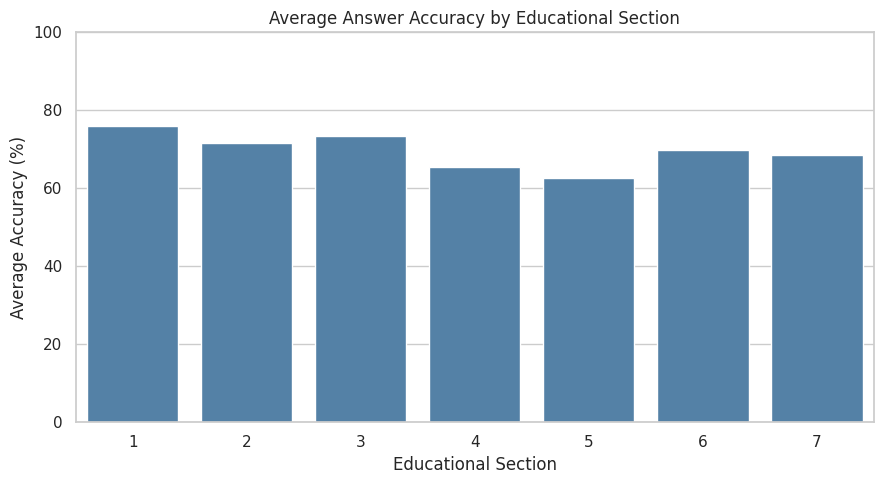

In [ ]:
topic_performance = (
    df_clean.groupby("part")
    .agg(
        Total_Attempts=("answered_correctly", "count"),
        Correct_Answers=("answered_correctly", "sum"),
        Accuracy=("answered_correctly", "mean")
    )
    .reset_index()
)

topic_performance["Accuracy (%)"] = (
    topic_performance["Accuracy"] * 100
)

display(
    topic_performance[
        ["part", "Total_Attempts", "Correct_Answers", "Accuracy (%)"]
    ].round(2)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=topic_performance,
    x="part",
    y="Accuracy (%)",
    color="steelblue"
)

plt.title("Average Answer Accuracy by Educational Section")
plt.xlabel("Educational Section")
plt.ylabel("Average Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## **4.3 Distribution of Student Question Attempts**

**Documentation:**

We examined the number of question attempts completed by each student.

The number of attempts provides information about the amount of learning history available for performance analysis.

Students with very few attempts may not provide sufficient information for reliable weakness detection.

We calculated the number of interactions per student and visualized the distribution.

Student Attempt Statistics:


,Total_Attempts
count,719.000000
mean,272.995828
std,752.390363
min,1.000000
25%,30.000000
50%,44.000000
75%,160.000000
max,7476.000000


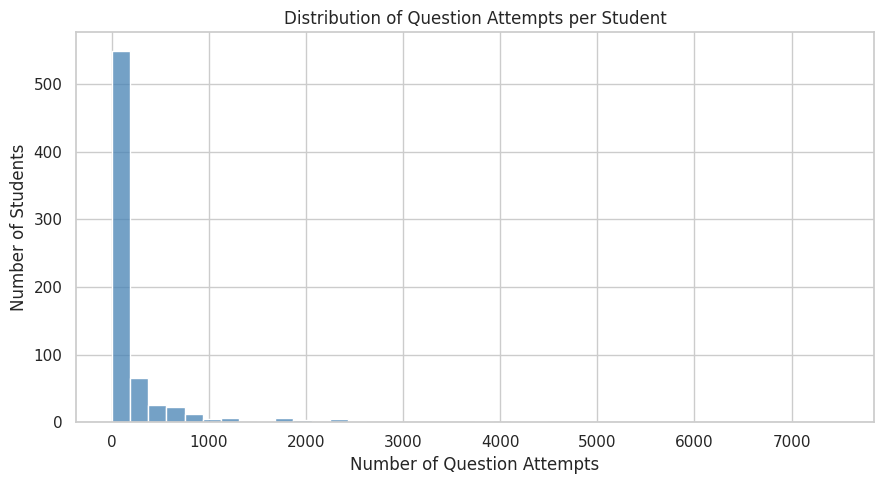

Total Unique Students: 719


In [ ]:
student_attempts = (
    df_clean.groupby("user_id")
    .size()
    .reset_index(name="Total_Attempts")
)

print("Student Attempt Statistics:")
display(student_attempts["Total_Attempts"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    student_attempts["Total_Attempts"],
    bins=40,
    color="steelblue"
)

plt.title("Distribution of Question Attempts per Student")
plt.xlabel("Number of Question Attempts")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

print("Total Unique Students:", df_clean["user_id"].nunique())

## **4.4 Question Difficulty Analysis**

**Documentation:**

We investigated question difficulty by calculating the average correctness rate for each question.

Questions with lower correctness rates were considered potentially more difficult, while questions with higher correctness rates were considered potentially easier.

This provides an exploratory estimate of question difficulty rather than an official difficulty label.

For the final ML pipeline, question difficulty must be calculated using training data only to prevent target leakage.

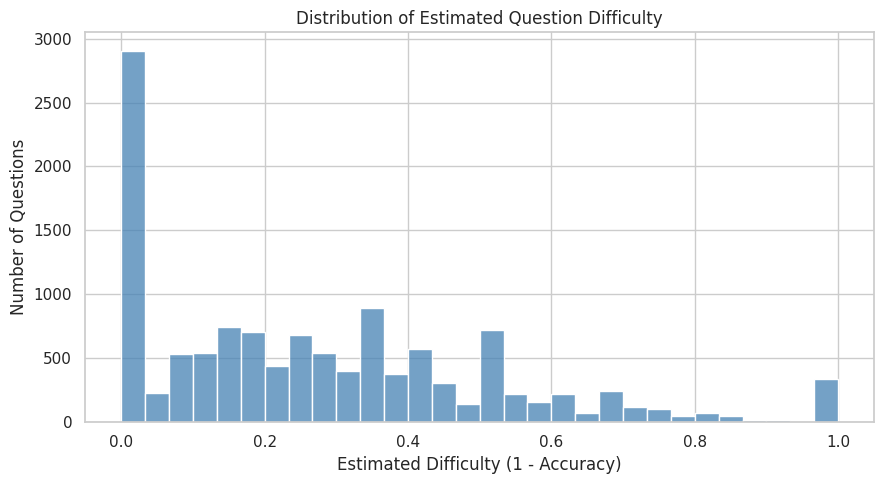

,content_id,Total_Attempts,Accuracy,Estimated_Difficulty
12407,13492,2,0.0,1.0
1633,1694,2,0.0,1.0
1464,1522,1,0.0,1.0
1463,1521,1,0.0,1.0
1462,1520,1,0.0,1.0
1429,1487,1,0.0,1.0
12432,13517,1,0.0,1.0
7785,8188,4,0.0,1.0
7478,7838,3,0.0,1.0
12256,13341,3,0.0,1.0


In [ ]:
question_performance = (
    df_clean.groupby("content_id")
    .agg(
        Total_Attempts=("answered_correctly", "count"),
        Accuracy=("answered_correctly", "mean")
    )
    .reset_index()
)

question_performance["Estimated_Difficulty"] = (
    1 - question_performance["Accuracy"]
)

plt.figure(figsize=(9, 5))

sns.histplot(
    question_performance["Estimated_Difficulty"],
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Estimated Question Difficulty")
plt.xlabel("Estimated Difficulty (1 - Accuracy)")
plt.ylabel("Number of Questions")
plt.tight_layout()
plt.show()

display(
    question_performance.sort_values(
        "Estimated_Difficulty",
        ascending=False
    ).head(10)
)

## **4.5 Relationship Between Practice and Accuracy**

**Documentation:**

We investigated the relationship between the number of recorded question attempts and student accuracy.

For each student, we calculated the total number of attempts and the proportion of correctly answered questions.

A scatter plot was used to visualize the relationship between these variables.

This analysis helps us understand whether interaction frequency is associated with performance.

However, correlation does not establish that additional practice causes better performance.

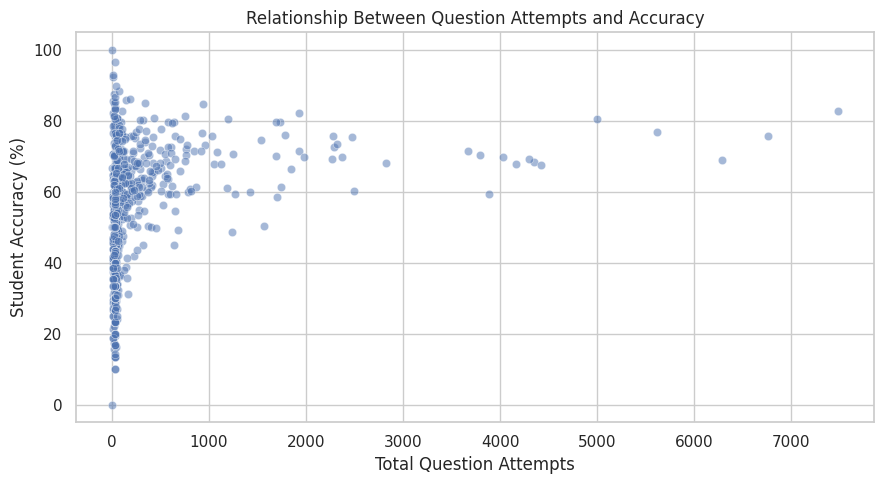

Correlation:
                Total_Attempts  Accuracy
Total_Attempts           1.000     0.268
Accuracy                 0.268     1.000


In [ ]:
student_performance = (
    df_clean.groupby("user_id")
    .agg(
        Total_Attempts=("answered_correctly", "count"),
        Accuracy=("answered_correctly", "mean")
    )
    .reset_index()
)

student_performance["Accuracy (%)"] = (
    student_performance["Accuracy"] * 100
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=student_performance,
    x="Total_Attempts",
    y="Accuracy (%)",
    alpha=0.5
)

plt.title("Relationship Between Question Attempts and Accuracy")
plt.xlabel("Total Question Attempts")
plt.ylabel("Student Accuracy (%)")
plt.tight_layout()
plt.show()

print("Correlation:")
print(
    student_performance[
        ["Total_Attempts", "Accuracy"]
    ].corr().round(3)
)

## **4.6 Correlation Analysis**

**Documentation:**

We calculated correlations between selected numerical variables to explore their relationships.

The analysis includes student interaction timing, previous question response time, and answer correctness.

A correlation heatmap was generated to visualize the strength and direction of the relationships.

Identifier columns were excluded because their numerical values do not represent meaningful continuous measurements.

Correlation analysis provides exploratory insights but does not establish causation or determine feature importance.

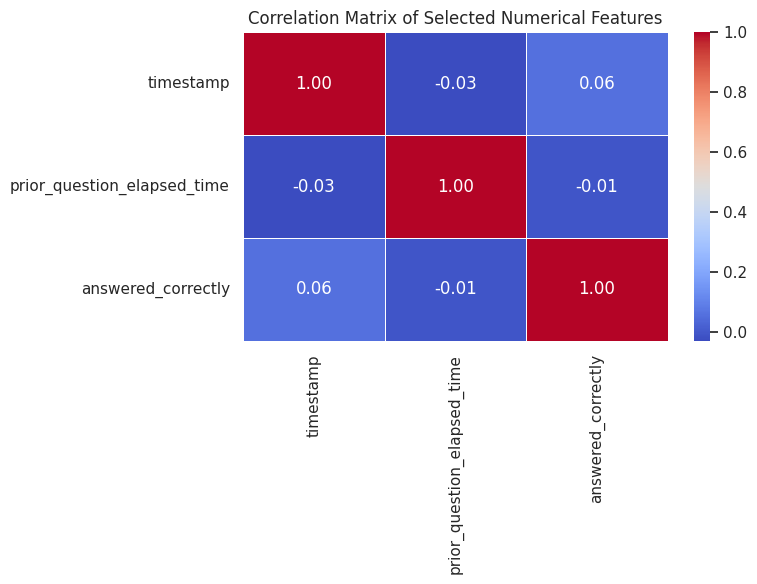

In [ ]:
correlation_columns = [
    "timestamp",
    "prior_question_elapsed_time",
    "answered_correctly"
]

correlation_matrix = df_clean[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Selected Numerical Features")
plt.tight_layout()
plt.show()

# **5. Feature Engineering and Preprocessing**

## **5.1 Feature Engineering**

**Documentation:**

We created performance-based features from students' previous interactions, including accuracy, attempts, mistakes, and topic-level performance.

These features help the model predict whether a student will answer the next question correctly.

In [ ]:
import numpy as np
import pandas as pd

df_ml = df_clean.copy()

df_ml = df_ml.sort_values(
    ["user_id", "timestamp", "task_container_id", "row_id"]
).reset_index(drop=True)

# Identify question groups with shared feedback timing
group_columns = [
    "user_id",
    "timestamp",
    "task_container_id"
]

# Aggregate results within each group
groups = (
    df_ml.groupby(group_columns, sort=False)
    .agg(
        group_attempts=("answered_correctly", "size"),
        group_correct=("answered_correctly", "sum")
    )
    .reset_index()
)

# Previous completed attempts
groups["previous_attempts"] = (
    groups.groupby("user_id")["group_attempts"]
    .transform(lambda x: x.cumsum() - x)
)

# Previous correct answers
groups["previous_correct"] = (
    groups.groupby("user_id")["group_correct"]
    .transform(lambda x: x.cumsum() - x)
)

# Previous accuracy
groups["previous_accuracy"] = (
    (groups["previous_correct"] + 5) /
    (groups["previous_attempts"] + 10)
)

# Previous mistakes
groups["previous_mistakes"] = (
    groups["previous_attempts"] -
    groups["previous_correct"]
)

# Merge previous performance back into individual answers
df_ml = df_ml.merge(
    groups[
        group_columns + [
            "previous_attempts",
            "previous_correct",
            "previous_accuracy",
            "previous_mistakes"
        ]
    ],
    on=group_columns,
    how="left",
    validate="many_to_one"
)

display(df_ml.head())

,row_id,timestamp,user_id,content_id,content_type_id,task_container_id,user_answer,answered_correctly,prior_question_elapsed_time,prior_question_had_explanation,question_id,bundle_id,correct_answer,part,tags,previous_attempts,previous_correct,previous_accuracy,previous_mistakes
0,0,0,115,5692,0,1,3,1,NaN,NaN,5692,5692,3,5,151,0,0,0.500000,0
1,1,56943,115,5716,0,2,2,1,37000.0,False,5716,5716,2,5,168,1,1,0.545455,0
2,2,118363,115,128,0,0,0,1,55000.0,False,128,128,0,1,131 149 92,2,2,0.583333,0
3,3,131167,115,7860,0,3,0,1,19000.0,False,7860,7860,0,1,131 104 81,3,3,0.615385,0
4,4,137965,115,7922,0,4,1,1,11000.0,False,7922,7922,1,1,131 149 92,4,4,0.642857,0


## **5.2 Handling Missing Values**

**Documentation:**

We handled missing values using median imputation for numerical features and a separate indicator for missing explanation information.

Imputation values are calculated from the training dataset to prevent data leakage.

In [ ]:
features = [
    "previous_attempts",
    "previous_correct",
    "previous_accuracy",
    "previous_mistakes"
]

X = df_ml[features].copy()

y = df_ml["answered_correctly"].copy()

print("Feature Matrix:", X.shape)
print("Target Vector:", y.shape)

display(X.head())

Feature Matrix: (196284, 4)
Target Vector: (196284,)


,previous_attempts,previous_correct,previous_accuracy,previous_mistakes
0,0,0,0.500000,0
1,1,1,0.545455,0
2,2,2,0.583333,0
3,3,3,0.615385,0
4,4,4,0.642857,0


## **5.3 Feature Selection**

**Documentation:**

We selected features related to previous student performance, question characteristics, and learning interactions.

The target variable is `answered_correctly`, which indicates whether the student's answer was correct.

## **5.4 Train, Validation, and Test Split**

**Documentation:**

We divided the dataset into training (70%), validation (15%), and testing (15%) sets.

The split follows each user's interaction history, ensuring that earlier interactions are used for training and later interactions for evaluation.

This helps reduce temporal data leakage.

In [ ]:
group_order = (
    df_ml[group_columns]
    .drop_duplicates()
    .sort_values(group_columns)
    .reset_index(drop=True)
)

group_order["group_position"] = (
    group_order.groupby("user_id").cumcount()
)

group_order["total_groups"] = (
    group_order.groupby("user_id")["user_id"]
    .transform("size")
)

group_order["relative_position"] = (
    group_order["group_position"] /
    group_order["total_groups"]
)

df_ml = df_ml.merge(
    group_order[
        group_columns + ["relative_position"]
    ],
    on=group_columns,
    how="left",
    validate="many_to_one"
)

train_mask = df_ml["relative_position"] < 0.70

val_mask = (
    (df_ml["relative_position"] >= 0.70) &
    (df_ml["relative_position"] < 0.85)
)

test_mask = df_ml["relative_position"] >= 0.85

X_train = X.loc[train_mask]
X_val = X.loc[val_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]
y_test = y.loc[test_mask]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (137224, 4)
Validation: (29746, 4)
Testing: (29314, 4)


## **5.5 Feature Scaling and Imputation**

**Documentation:**

We applied median imputation to missing numerical values and standardized numerical features using StandardScaler.

Both transformations were fitted on the training data only and then applied to validation and test data.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Preprocessing completed successfully!")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Preprocessing completed successfully!
Training: (137224, 4)
Validation: (29746, 4)
Testing: (29314, 4)


## **5.6 Data Verification**

**Documentation:**

We verified that the processed feature matrices contain no missing or infinite values.

This ensures the dataset is ready for machine learning model training.

In [ ]:
print("Missing Values:", np.isnan(X_train_scaled).sum())
print("Infinite Values:", np.isinf(X_train_scaled).sum())

print("\nTraining Target Distribution:")
display(y_train.value_counts())

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()
assert np.isfinite(X_test_scaled).all()

print("\nDataset ready for model training!")

Missing Values: 0
Infinite Values: 0

Training Target Distribution:


,count
answered_correctly,
1,92492
0,44732



Dataset ready for model training!


# **6. Model Training and Selection**

## **6.1 Importing Model Libraries**

**Documentation:**

We imported classification algorithms and evaluation metrics to train and compare multiple machine learning models.

The models will predict whether a student answers a question correctly based on previous learning performance.

In [ ]:
!pip -q install lightgbm

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss
)

from lightgbm import LGBMClassifier

print("Model libraries imported successfully!")

Model libraries imported successfully!


## **6.2 Training Machine Learning Models**

**Documentation:**

We trained four classification models: Logistic Regression with L1 and L2 regularization, Random Forest, and LightGBM.

Each model was trained using the same training dataset to ensure a consistent comparison.

The validation dataset was reserved for evaluating model performance and selecting the best algorithm.

In [ ]:
models = {
    "Logistic Regression (L1)": LogisticRegression(
        penalty="l1",
        solver="liblinear",
        max_iter=1000,
        random_state=42
    ),

    "Logistic Regression (L2)": LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=8,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train_scaled, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!\n")

Training Logistic Regression (L1)...
Logistic Regression (L1) trained successfully!

Training Logistic Regression (L2)...
Logistic Regression (L2) trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training LightGBM...
LightGBM trained successfully!



## **6.3 Model Performance Comparison**

**Documentation:**

We evaluated the trained models using the validation dataset.

Accuracy, precision, recall, F1-score, ROC-AUC, and log loss were calculated to compare classification performance.

Log loss was selected as the primary metric because the system requires reliable probability estimates for identifying learning weaknesses.

In [ ]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_val_scaled)

    y_prob = model.predict_proba(X_val_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "Log Loss": log_loss(y_val, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "Log Loss",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Log Loss
0,Logistic Regression (L2),0.6965,0.7002,0.9827,0.8177,0.6205,0.5963
1,Logistic Regression (L1),0.6965,0.7002,0.9827,0.8177,0.6205,0.5963
2,LightGBM,0.6966,0.7011,0.9798,0.8174,0.5837,0.6051
3,Random Forest,0.6680,0.6942,0.9310,0.7953,0.5623,0.6275


## **6.4 Model Performance Visualization**

**Documentation:**

We visualized model performance using bar charts.

The charts compare classification accuracy, ROC-AUC, and log loss across the four algorithms.

These visualizations help identify differences in predictive performance.

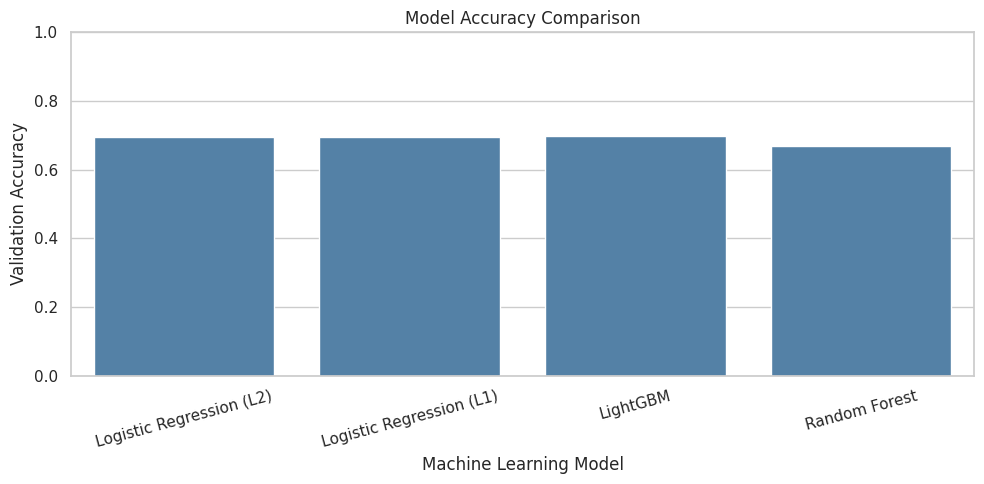

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    color="steelblue"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

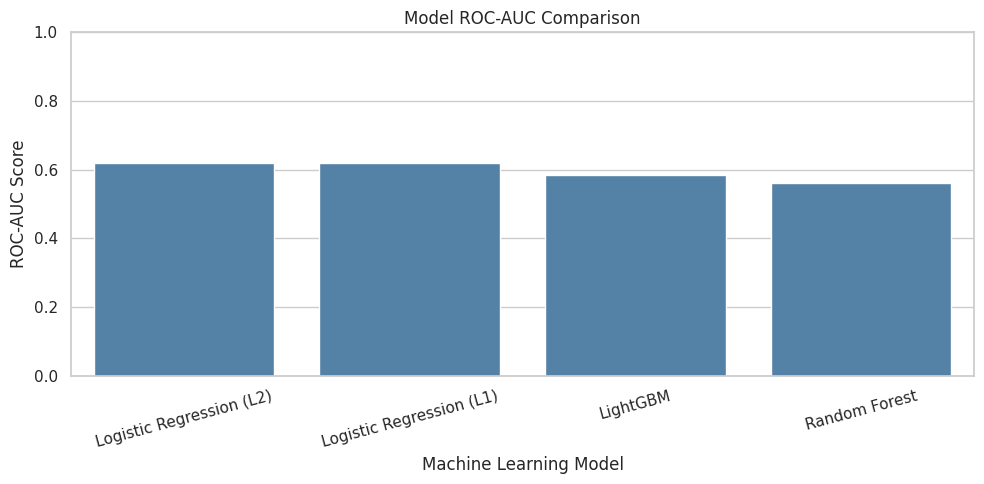

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC",
    color="steelblue"
)

plt.title("Model ROC-AUC Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

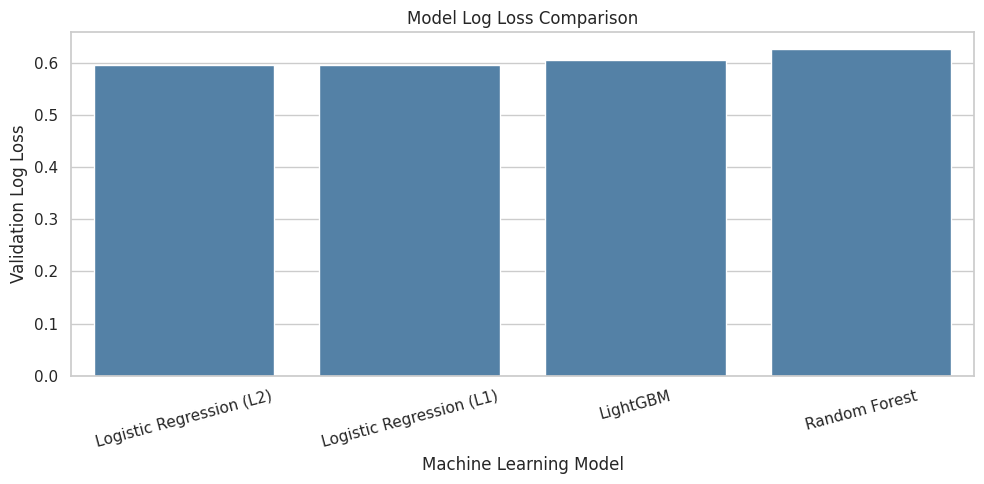

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Log Loss",
    color="steelblue"
)

plt.title("Model Log Loss Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Validation Log Loss")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## **6.5 Best Model Selection**

**Documentation:**

We selected the model with the lowest validation log loss.

This metric evaluates the quality of predicted probabilities, which are important for estimating student knowledge and identifying potential learning weaknesses.

The selected model will undergo further evaluation using the independent test dataset.

In [ ]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Validation Log Loss:",
    round(results_df.iloc[0]["Log Loss"], 4)
)

print(
    "Validation Accuracy:",
    round(results_df.iloc[0]["Accuracy"], 4)
)

print(
    "Validation ROC-AUC:",
    round(results_df.iloc[0]["ROC-AUC"], 4)
)

Best Model: Logistic Regression (L2)
Validation Log Loss: 0.5963
Validation Accuracy: 0.6965
Validation ROC-AUC: 0.6205


## **6.6 Baseline Comparison**

**Documentation:**

We compared the selected machine learning model against a simple baseline.

The baseline predicts the overall correct-answer probability observed in the training dataset.

This comparison helps determine whether the machine learning model provides meaningful improvements over a basic statistical approach.

In [ ]:
baseline_probability = y_train.mean()

baseline_predictions = np.full(
    len(y_val),
    baseline_probability
)

baseline_loss = log_loss(
    y_val,
    baseline_predictions
)

best_model_probability = best_model.predict_proba(
    X_val_scaled
)[:, 1]

model_loss = log_loss(
    y_val,
    best_model_probability
)

print("Baseline Log Loss:", round(baseline_loss, 4))
print("Best Model Log Loss:", round(model_loss, 4))

improvement = (
    (baseline_loss - model_loss) / baseline_loss
) * 100

print("Relative Improvement:", round(improvement, 2), "%")

Baseline Log Loss: 0.6176
Best Model Log Loss: 0.5963
Relative Improvement: 3.45 %


## **6.7 Saving the Selected Model**

**Documentation:**

We saved the selected machine learning model along with the preprocessing components.

The saved files will allow the model to be reused without repeating the training process.

These artifacts are preliminary and will be updated after final evaluation and validation.

In [ ]:
import joblib
import os

MODEL_DIR = f"{PROJECT_DIR}/models"

os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(
    best_model,
    f"{MODEL_DIR}/weakness_model_preliminary.pkl"
)

joblib.dump(
    imputer,
    f"{MODEL_DIR}/imputer.pkl"
)

joblib.dump(
    scaler,
    f"{MODEL_DIR}/scaler.pkl"
)

joblib.dump(
    features,
    f"{MODEL_DIR}/feature_columns.pkl"
)

results_df.to_csv(
    f"{MODEL_DIR}/model_comparison.csv",
    index=False
)

print("Preliminary model and preprocessing artifacts saved!")

Preliminary model and preprocessing artifacts saved!


# **7. Model Evaluation**

## **7.1 Final Model Evaluation**

**Documentation:**

We evaluated the selected model using the test dataset.

We calculated accuracy, precision, recall, F1-score, ROC-AUC, and log loss to assess classification performance and prediction reliability.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss
)

y_test_pred = best_model.predict(X_test_scaled)
y_test_prob = best_model.predict_proba(X_test_scaled)[:, 1]

test_results = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
    "Log Loss": log_loss(y_test, y_test_prob)
}

test_results_df = pd.DataFrame(
    test_results.items(),
    columns=["Metric", "Score"]
)

print("Selected Model:", best_model_name)
display(test_results_df.round(4))

Selected Model: Logistic Regression (L2)


,Metric,Score
0,Accuracy,0.6908
1,Precision,0.6935
2,Recall,0.9779
3,F1-Score,0.8115
4,ROC-AUC,0.6234
5,Log Loss,0.6036


## **7.2 Confusion Matrix**

**Documentation:**

We generated a confusion matrix to examine the model's classification errors.

The matrix shows true positives, true negatives, false positives, and false negatives, helping us understand which types of predictions are more difficult.

<Figure size 700x500 with 0 Axes>

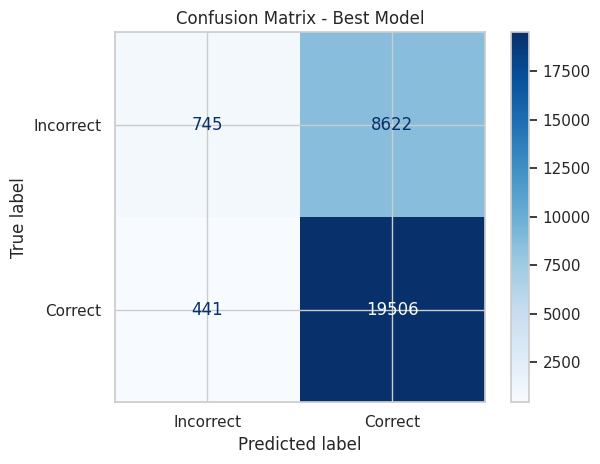

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Incorrect", "Correct"]
)

plt.figure(figsize=(7, 5))

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Best Model")
plt.tight_layout()
plt.show()

## **7.3 Classification Report**

**Documentation:**

We generated a classification report containing precision, recall, and F1-score for each target class.

This analysis helps determine whether the model predicts both correct and incorrect answers effectively.

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Incorrect", "Correct"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

,precision,recall,f1-score,support
Incorrect,0.6282,0.0795,0.1412,9367.0000
Correct,0.6935,0.9779,0.8115,19947.0000
accuracy,0.6908,0.6908,0.6908,0.6908
macro avg,0.6608,0.5287,0.4763,29314.0000
weighted avg,0.6726,0.6908,0.5973,29314.0000


## **7.4 Training vs. Testing Performance**

**Documentation:**

We compared training and test performance to investigate possible overfitting.

A large difference between training and testing performance may indicate that the model does not generalize effectively to unseen interactions.

In [ ]:
train_pred = best_model.predict(X_train_scaled)
train_prob = best_model.predict_proba(X_train_scaled)[:, 1]

comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "ROC-AUC", "Log Loss"],
    "Training": [
        accuracy_score(y_train, train_pred),
        roc_auc_score(y_train, train_prob),
        log_loss(y_train, train_prob)
    ],
    "Testing": [
        accuracy_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_prob),
        log_loss(y_test, y_test_prob)
    ]
})

display(comparison_df.round(4))

,Metric,Training,Testing
0,Accuracy,0.6795,0.6908
1,ROC-AUC,0.6152,0.6234
2,Log Loss,0.6123,0.6036


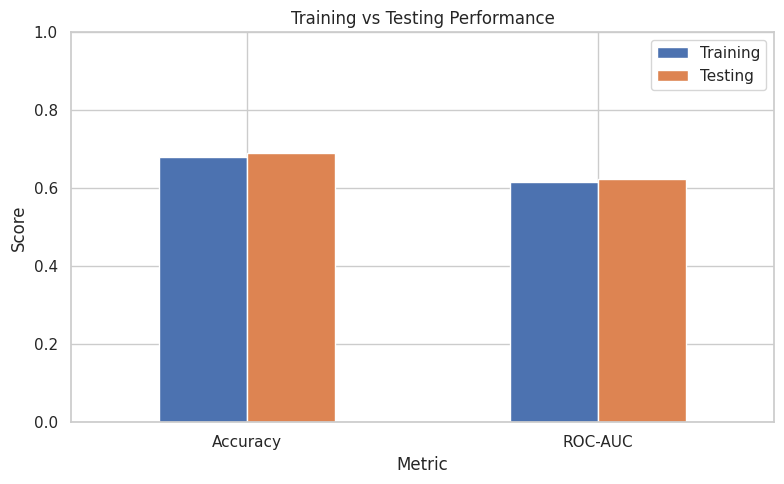

In [ ]:
plot_df = comparison_df[
    comparison_df["Metric"].isin(["Accuracy", "ROC-AUC"])
]

plot_df.set_index("Metric").plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Training vs Testing Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## **7.5 Learning Curves**

**Documentation:**

We generated learning curves by training the selected model on progressively larger portions of the training data.

We compared training and validation log loss to examine generalization and identify possible overfitting or underfitting.

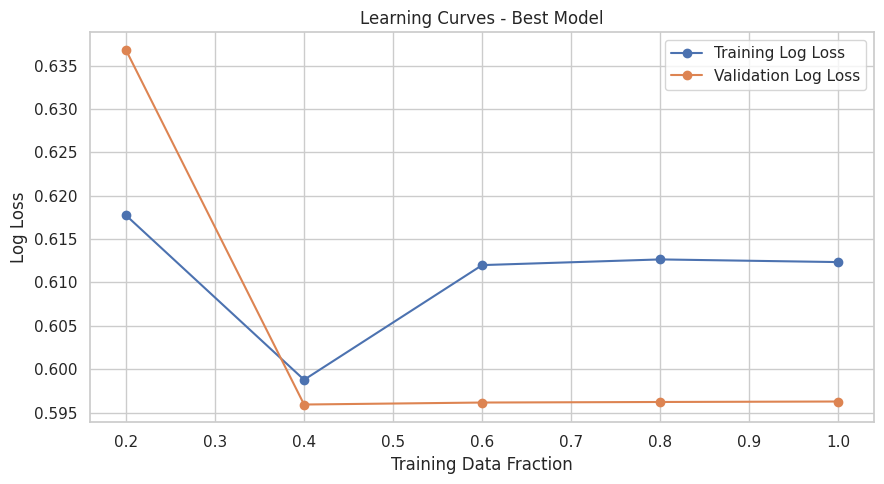

In [ ]:
from sklearn.base import clone

train_sizes = [0.2, 0.4, 0.6, 0.8, 1.0]

train_losses = []
val_losses = []

for fraction in train_sizes:

    size = max(1, int(len(X_train_scaled) * fraction))

    # Preserve the order of the training partition
    X_subset = X_train_scaled[:size]
    y_subset = y_train.iloc[:size]

    model = clone(best_model)
    model.fit(X_subset, y_subset)

    train_probabilities = model.predict_proba(X_subset)[:, 1]
    val_probabilities = model.predict_proba(X_val_scaled)[:, 1]

    train_losses.append(
        log_loss(y_subset, train_probabilities, labels=[0, 1])
    )

    val_losses.append(
        log_loss(y_val, val_probabilities, labels=[0, 1])
    )

plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_losses,
    marker="o",
    label="Training Log Loss"
)

plt.plot(
    train_sizes,
    val_losses,
    marker="o",
    label="Validation Log Loss"
)

plt.title("Learning Curves - Best Model")
plt.xlabel("Training Data Fraction")
plt.ylabel("Log Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## **7.6 Model Justification**

**Documentation:**

The selected model was chosen based on validation log loss, which measures the quality of predicted probabilities.

Its final performance was evaluated using an independent test partition.

The results will be compared against a statistical baseline to determine whether the model provides a meaningful improvement for educational performance prediction.

# **8. Discussion and Findings**

## **8.1 Model Performance Summary**

**Documentation:**

We compared four classification models: Logistic Regression (L1), Logistic Regression (L2), Random Forest, and LightGBM.

The models were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and log loss.

The best model was selected based on the lowest validation log loss, since reliable probability predictions are important for identifying potential learning weaknesses.

In [ ]:
print("Model Performance Comparison:")
display(results_df.round(4))

print("\nSelected Model:", best_model_name)

print("\nFinal Test Performance:")
display(test_results_df.round(4))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Log Loss
0,Logistic Regression (L2),0.6965,0.7002,0.9827,0.8177,0.6205,0.5963
1,Logistic Regression (L1),0.6965,0.7002,0.9827,0.8177,0.6205,0.5963
2,LightGBM,0.6966,0.7011,0.9798,0.8174,0.5837,0.6051
3,Random Forest,0.6680,0.6942,0.9310,0.7953,0.5623,0.6275



Selected Model: Logistic Regression (L2)

Final Test Performance:


,Metric,Score
0,Accuracy,0.6908
1,Precision,0.6935
2,Recall,0.9779
3,F1-Score,0.8115
4,ROC-AUC,0.6234
5,Log Loss,0.6036


## **8.2 Overfitting Analysis**

**Documentation:**

We compared training and testing performance to investigate possible overfitting.

A large difference between training and testing performance may indicate that the model has learned patterns specific to the training data rather than generalizable relationships.

In [ ]:
train_accuracy = accuracy_score(
    y_train,
    best_model.predict(X_train_scaled)
)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

accuracy_gap = train_accuracy - test_accuracy

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))
print("Accuracy Gap:", round(accuracy_gap, 4))

if accuracy_gap > 0.10:
    print("Noticeable training-test accuracy gap.")
else:
    print("No large training-test accuracy gap detected.")

Training Accuracy: 0.6795
Testing Accuracy: 0.6908
Accuracy Gap: -0.0114
No large training-test accuracy gap detected.


## **8.3 Feature Importance**

**Documentation:**

We examined feature importance to understand which variables influence the selected model's predictions.

This analysis provides insight into the contribution of previous accuracy, question attempts, topic performance, and other learning-related features.

In [ ]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_val_scaled,
    y_val,
    n_repeats=3,
    random_state=42,
    scoring="neg_log_loss",
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

,Feature,Importance
2,previous_accuracy,0.0333
1,previous_correct,0.0025
3,previous_mistakes,0.0024
0,previous_attempts,0.0005


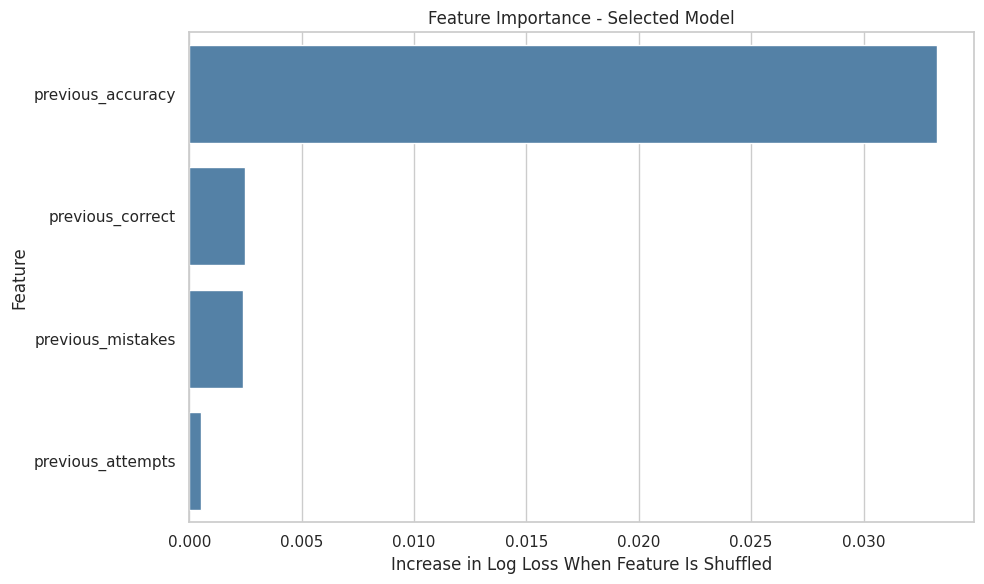

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Feature Importance - Selected Model")
plt.xlabel("Increase in Log Loss When Feature Is Shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## **8.4 Limitations**

**Documentation:**

Although the models were trained using real educational interactions, several limitations remain:

1. The Riiid dataset contains educational questions rather than historical trivia.
2. The initial experiment uses only 200,000 interaction records.
3. Some student histories may be incomplete.
4. The dataset does not directly contain Rihla's historical categories, periods, or regions.
5. The current feature engineering requires additional safeguards for bundled questions and feedback timing.

Therefore, the current results represent preliminary answer-correctness prediction performance rather than validated historical weakness detection.

## **8.5 Application to Rihla**

**Documentation:**

The developed machine learning model predicts the probability that a student will answer a question correctly based on previous performance.

In Rihla, a similar model can analyze historical trivia interactions to estimate user knowledge across different categories, periods, and regions.

After a user completes at least five trivia games, Rihla will use their performance to identify potential weak areas.

These weaknesses can then support personalized recommendations of historical events, characters, and relevant library resources.

The model must be adapted and validated using Rihla-specific data before deployment.

## **9.3 Preparing Rihla Trivia Data**

**Documentation:**

We prepared sample historical trivia records to test the integration process.

Each record contains a user identifier, game session, question category, difficulty, and answer correctness.

These records demonstrate the structure required by the weakness-detection component.

In [ ]:
import pandas as pd

rihla_data = pd.DataFrame({
    "user_id": [1] * 10,
    "session_id": [101] * 5 + [102] * 5,
    "question_id": range(1, 11),
    "category": [
        "Wars", "Politics", "Science", "Wars", "Science",
        "Politics", "Wars", "Science", "Wars", "Politics"
    ],
    "difficulty": [
        "Easy", "Medium", "Hard", "Medium", "Easy",
        "Hard", "Hard", "Medium", "Medium", "Easy"
    ],
    "answered_correctly": [0, 1, 1, 0, 1, 1, 0, 1, 0, 1]
})

display(rihla_data)

,user_id,session_id,question_id,category,difficulty,answered_correctly
0,1,101,1,Wars,Easy,0
1,1,101,2,Politics,Medium,1
2,1,101,3,Science,Hard,1
3,1,101,4,Wars,Medium,0
4,1,101,5,Science,Easy,1
5,1,102,6,Politics,Hard,1
6,1,102,7,Wars,Hard,0
7,1,102,8,Science,Medium,1
8,1,102,9,Wars,Medium,0
9,1,102,10,Politics,Easy,1


## **9.4 Calculating Weakness Scores**

**Documentation:**

We developed a baseline method for identifying weak historical categories using trivia performance.

The method calculates the number of attempts, correct answers, and accuracy for each category.

A smoothed accuracy estimate reduces the impact of categories with very few attempts.

This baseline will later be compared with the adapted machine learning model.

In [ ]:
def calculate_weakness(data):

    performance = (
        data.groupby("category")
        .agg(
            attempts=("answered_correctly", "count"),
            correct=("answered_correctly", "sum")
        )
        .reset_index()
    )

    performance["accuracy_percent"] = (
        performance["correct"] /
        performance["attempts"] * 100
    )

    # Smoothed accuracy using a neutral prior
    performance["smoothed_accuracy"] = (
        (performance["correct"] + 5) /
        (performance["attempts"] + 10)
    )

    performance["weakness_score"] = (
        1 - performance["smoothed_accuracy"]
    )

    performance = performance.sort_values(
        "weakness_score",
        ascending=False
    )

    return performance


weakness_results = calculate_weakness(rihla_data)

display(weakness_results.round(3))

,category,attempts,correct,accuracy_percent,smoothed_accuracy,weakness_score
2,Wars,4,0,0.0,0.357,0.643
0,Politics,3,3,100.0,0.615,0.385
1,Science,3,3,100.0,0.615,0.385


## **9.5 Weakness Detection Eligibility**

**Documentation:**

Rihla displays detected weaknesses only after a user completes at least five trivia games.

We implemented an eligibility check to prevent premature weakness reporting.

Only completed sessions should contribute to the eligibility count.

In [ ]:
def analyze_user_weakness(data, completed_games):

    if completed_games < 5:
        return {
            "eligible": False,
            "games_remaining": 5 - completed_games,
            "weak_areas": []
        }

    results = calculate_weakness(data)

    # Preliminary reporting criteria
    weak_areas = results[
        (results["attempts"] >= 5) &
        (results["smoothed_accuracy"] < 0.50)
    ]

    return {
        "eligible": True,
        "games_remaining": 0,
        "weak_areas": weak_areas.to_dict(
            orient="records"
        )
    }


result = analyze_user_weakness(
    rihla_data,
    completed_games=2
)

print(result)

{'eligible': False, 'games_remaining': 3, 'weak_areas': []}


# 10. Knowledge Tracing Data Preparation

**Documentation:** Sections 1–9 are preserved as earlier answer-correctness experiments. Their predicted correctness is not mastery. The saved L2 validation results are log loss 0.5963, accuracy 0.6965 and AUC 0.6205; these are not directly comparable with the stricter experiment below.

**Review:** Reuse the source files, binary correctness, metadata join and chronological approach. Section 5 currently uses only four overall-history features, despite broader prose about topic/difficulty features. The missing-value/explanation documentation is broader than the selected features. Imputation is redundant for those complete count features. Section 9's five-question sessions are synthetic and do not satisfy ten-question completion; its integer count and provisional thresholds are not production validation. Earlier artifact-save code overwrites fixed filenames: do not rerun it to save this extension.

We reload verified Drive files without mutating earlier variables. Use Riiid **part** as a coarse educational skill, retaining tags for future mapping; neither represents historical categories. Incomplete sampled histories mean initial knowledge is knowledge at first observed interaction, not at enrollment.

**Feedback assumption:** timestamp is relative to each student, not a global calendar. Order each user by row_id and verify nondecreasing timestamp. Merge overlapping task-container/timestamp ranges into conservative feedback blocks. All questions in a block are predicted before any block answers are observed; one learning transition occurs after feedback per skill-block. Exact feedback receipt is absent. Assume a block's feedback is available before the next block. Also evaluate with held-out feedback completely frozen as a conservative sensitivity check. This cannot prove actual feedback timing.

Split whole blocks within each student 70/15/15; exclude users with fewer than seven blocks from model evaluation (still report their counts). Fit parameters only to training prefixes. This evaluates returning-user continuation, not unseen-user or real-calendar generalization.

**Results and interpretation:** The next cell reports actual file checks, grouping diagnostics and partition sizes. No historical labels or difficulty values are invented.

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display
from google.colab import drive
import scipy, sklearn
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss

drive.mount('/content/drive')
BKT_ROOT = Path('/content/drive/MyDrive/Rihla_ML')
for filename in ['rihla_weakness_sample.csv', 'questions.csv']:
    path = BKT_ROOT / filename
    assert path.is_file(), f'Missing required dataset: {path}'
    print(filename, path.stat().st_size, 'bytes')
bkt_raw = pd.read_csv(BKT_ROOT / 'rihla_weakness_sample.csv')
bkt_questions = pd.read_csv(BKT_ROOT / 'questions.csv')
required = ['user_id','row_id','timestamp','task_container_id','content_id','content_type_id','answered_correctly']
assert set(required) <= set(bkt_raw.columns)
assert not bkt_raw.row_id.duplicated().any()
assert not bkt_questions.question_id.duplicated().any()
bkt_data = bkt_raw.loc[bkt_raw.content_type_id.eq(0), required].merge(
    bkt_questions[['question_id','part','tags','bundle_id']],
    left_on='content_id', right_on='question_id', how='left', validate='many_to_one')
assert bkt_data[required + ['part']].notna().all().all()
assert bkt_data.answered_correctly.isin([0,1]).all()
bkt_data = bkt_data.sort_values(['user_id','row_id']).reset_index(drop=True)
assert bkt_data.groupby('user_id').timestamp.diff().dropna().ge(0).all(), 'Chronology is ambiguous'
bkt_data['skill'] = 'riiid_part_' + bkt_data.part.astype(int).astype(str)
# Conservative interval closure: no shared timestamp or container may cross a block.
blocks = np.empty(len(bkt_data), dtype=int)
for uid, sub in bkt_data.groupby('user_id', sort=False):
    sub = sub.copy()
    sub['pos'] = np.arange(len(sub))
    ends = np.maximum(sub.groupby('task_container_id').pos.transform('max'),
                      sub.groupby('timestamp').pos.transform('max')).to_numpy()
    block, active_end = -1, -1
    for i, (idx, end) in enumerate(zip(sub.index, ends)):
        if i > active_end:
            block += 1
        active_end = max(active_end, end)
        blocks[idx] = block
bkt_data['block'] = blocks
bkt_data['n_blocks'] = bkt_data.groupby('user_id').block.transform('max') + 1
bkt_data['split'] = np.where(bkt_data.block < np.floor(.70*bkt_data.n_blocks), 'train',
                            np.where(bkt_data.block < np.floor(.85*bkt_data.n_blocks), 'validation', 'test'))
bkt_data['evaluation_eligible'] = bkt_data.n_blocks.ge(7)
print('Raw / question interactions:', len(bkt_raw), len(bkt_data))
print('Students excluded from fitting/evaluation (<7 blocks):', bkt_data.loc[~bkt_data.evaluation_eligible,'user_id'].nunique())
print(bkt_data.groupby(['evaluation_eligible','split']).size().rename('interactions').to_string())
print(bkt_data.groupby(['user_id','block']).size().describe().to_string())
assert bkt_data.groupby(['user_id','task_container_id']).block.nunique().eq(1).all()
assert bkt_data.groupby(['user_id','timestamp']).block.nunique().eq(1).all()
bkt_experiment = bkt_data[bkt_data.evaluation_eligible].copy()
print('Verified imports:', 'scipy', scipy.__version__, 'sklearn', sklearn.__version__)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
rihla_weakness_sample.csv 10541456 bytes
questions.csv 296161 bytes
Raw / question interactions: 200000 196284
Students excluded from fitting/evaluation (<7 blocks): 3
evaluation_eligible  split     
False                test               3
                     train              3
True                 test           30105
                     train         136483
                     validation     29690
count    150520.000000
mean          1.304039
std           0.832747
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           5.000000
Verified imports: scipy 1.16.3 sklearn 1.6.1


# 11. Bayesian Knowledge Tracing Model

**Documentation:** Fit a two-state, no-forgetting hidden Markov model per educational skill by maximum likelihood, using training prefixes only. Parameters are initial knowledge L0, learning T, guessing G and slip S. A feedback block has a fixed latent state, conditionally independent answer emissions, and one transition after feedback. This is a bundle-aware BKT variant; within-bundle dependence may still violate its assumptions.

For c correct and w incorrect answers, mastered likelihood is (1-S)^c S^w and unmastered likelihood is G^c (1-G)^w. Bayes' rule gives posterior mastery; next-block mastery is posterior + (1-posterior)T. Next-answer correctness is L(1-S)+(1-L)G, a separate quantity.

We use bounded optimization (L0,T in [0.00001,0.99999], G,S in [0.00001,0.49999]) to constrain the mastered state to higher correctness and reduce label ambiguity. These are modeling assumptions, not weakness thresholds. Three initializations are optimized; their starting values are never reported as fitted estimates. Optimization success, boundaries and objective are printed. Numerical unit checks compare the forward likelihood with exact latent-state enumeration and verify Bayes updates. Estimates remain assumption-dependent; no-forgetting can overestimate persistent mastery.

**Results and interpretation:** The next cell prints fitted parameters and diagnostics. A converged optimizer does not establish psychological validity or parameter identifiability.

In [ ]:
from numba import njit
import itertools

@njit
def bkt_nll(theta, users, correct, wrong):
    l0, learn, guess, slip = theta
    total, prior, last = 0.0, l0, -1
    for i in range(len(users)):
        if users[i] != last:
            prior = l0
            last = users[i]
        lm = np.log(prior) + correct[i]*np.log(1-slip) + wrong[i]*np.log(slip)
        lu = np.log1p(-prior) + correct[i]*np.log(guess) + wrong[i]*np.log1p(-guess)
        norm = np.logaddexp(lm, lu)
        total -= norm
        posterior = np.exp(lm-norm)
        prior = posterior + (1-posterior)*learn
    return total

def feedback_update(prior, c, w, theta):
    _, learn, guess, slip = theta
    lm = np.log(prior) + c*np.log1p(-slip) + w*np.log(slip)
    lu = np.log1p(-prior) + c*np.log(guess) + w*np.log1p(-guess)
    posterior = float(np.exp(lm-np.logaddexp(lm,lu)))
    return posterior, posterior+(1-posterior)*learn

# Exact independent likelihood check for a tiny two-block sequence.
test_theta = np.array([.3,.12,.2,.1])
exact = 0.0
for a,b in itertools.product([0,1], repeat=2):
    initial = .3 if a else .7
    transition = (1.0 if b else 0.0) if a else (.12 if b else .88)
    emit1 = .9 if a else .2
    emit2 = .1 if b else .8
    exact += initial*transition*emit1*emit2
assert np.isclose(np.exp(-bkt_nll(test_theta,np.array([1,1]),np.array([1,0]),np.array([0,1]))),exact)
p, nxt = feedback_update(.3,1,0,test_theta)
assert np.isclose(p, .27/(.27+.14))
assert np.isclose(nxt,p+(1-p)*.12)
assert feedback_update(.3,0,1,test_theta)[0] < .3
assert np.isclose(bkt_nll(test_theta,np.array([1,2]),np.array([1,0]),np.array([0,1])), -np.log(.41)-np.log(.59))

bkt_train = bkt_experiment[bkt_experiment.split.eq('train')]
bkt_params, bkt_fit_records = {}, []
bkt_bounds = [(1e-5,1-1e-5),(1e-5,1-1e-5),(1e-5,.49999),(1e-5,.49999)]
for skill, sub in bkt_train.groupby('skill'):
    agg = sub.groupby(['user_id','block'],sort=True).answered_correctly.agg(['sum','size']).reset_index()
    args = (agg.user_id.to_numpy(np.int64),agg['sum'].to_numpy(np.int64),(agg['size']-agg['sum']).to_numpy(np.int64))
    runs = [minimize(bkt_nll,np.array(start),args=args,method='L-BFGS-B',bounds=bkt_bounds,
                     options={'maxiter':250,'ftol':1e-10})
            for start in [(.2,.05,.2,.1),(.5,.01,.3,.2),(.7,.15,.1,.3)]]
    valid = [r for r in runs if r.success and np.isfinite(r.fun)]
    assert valid, f'No converged fit: {skill}'
    best = min(valid,key=lambda r:r.fun)
    bkt_params[skill] = best.x.tolist()
    boundary = any(min(abs(v-lo),abs(v-hi)) < 1e-4 for v,(lo,hi) in zip(best.x,bkt_bounds))
    bkt_fit_records.append(dict(skill=skill,L0=best.x[0],T=best.x[1],G=best.x[2],S=best.x[3],
        train_answers=len(sub),train_students=sub.user_id.nunique(),nll=best.fun,
        converged_starts=len(valid),boundary=boundary))
bkt_fit_table = pd.DataFrame(bkt_fit_records)
print(bkt_fit_table.round(6).to_string(index=False))
print('Numerical BKT tests passed. Parameters fitted exclusively to training data.')


       skill       L0        T        G        S  train_answers  train_students          nll  converged_starts  boundary
riiid_part_1 0.390326 0.042661 0.499990 0.201119          10997             507  6054.631916                 3      True
riiid_part_2 0.665774 0.007616 0.499990 0.242637          27262             627 15958.741945                 3      True
riiid_part_3 0.260236 0.040351 0.499990 0.219408          13658             330  7853.869401                 3      True
riiid_part_4 0.119678 0.188049 0.295706 0.267710          10639             328  6457.424651                 3     False
riiid_part_5 0.094817 0.020215 0.448817 0.323489          53710             693 34812.014024                 3     False
riiid_part_6 0.549606 0.022522 0.490092 0.266688          14710             231  8863.102324                 3     False
riiid_part_7 0.311868 0.157832 0.407007 0.225161           5507             206  3232.821732                 3     False
Numerical BKT tests passed. Para

# 12. Knowledge Estimation and Accuracy Comparison

**Documentation:** Replay each student-skill history. Predict every answer in a feedback block from the same prior state, then update mastery once after observing the entire block. The example table reports pre-feedback mastery, predicted correctness, posterior mastery and next-block mastery separately. Accuracy is always observed correct / attempted. BKT weights the sequence through fitted emissions and learning; accuracy weights all observed answers equally. Neither agreement nor disagreement proves true knowledge.

# 13. Held-Out Evaluation

**Documentation:** Compare A: prior raw student-skill accuracy (training topic mean for cold start), B: smoothed accuracy (training topic mean with ten pseudo-observations), and C: fitted BKT. Smoothing strength is a declared baseline choice, not an approved reporting rule. All three use exactly the same histories and feedback schedule. Log loss clips probabilities at 1e-6 for numerical stability, including raw 0/1 accuracy. Parameters and topic priors never use held-out labels. Online validation/test updates only filter the user's state after block feedback; they never refit parameters. Frozen evaluation uses only training feedback throughout both held-out partitions.

Report log loss, AUC, Brier score and ten-bin calibration tables; no ROC or PR curves. Future-answer prediction validates an observable implication of BKT, not mastery ground truth. Differences from earlier classifier results include partitions and features, so do not compare their numbers as a controlled experiment.

**Results and interpretation:** The next cell prints actual metrics, calibration, and a sequence example; it states whether BKT improves over the accuracy baselines without assuming superiority. Numerical results are descriptive; user-cluster uncertainty and external validation remain future work.

## 13.1 Guessing-Parameter Boundary Investigation

**Documentation:** Parts 1–3 reached G=0.49999. Fit training-only fixed-G likelihood profiles and a relaxed model with G up to 0.95, parameterizing S=(1-G)q to retain higher correctness in the mastered state. Three starting points are optimized for each relaxed fit. Compare original and relaxed fits on the same online/frozen validation and test interactions. The primary model and its results remain unchanged; this investigation does not select models using test outcomes.

**Interpretation:** A fitted guess parameter is an effective probability of a correct response conditional on the unmastered state; it need not equal random multiple-choice guessing. Large values can reflect partial knowledge or overly broad skills. Lower training likelihood loss after relaxation indicates constraint pressure, not psychological validation. Profile fits are local optimization diagnostics, not confidence intervals. The output and final verification record report the observed sensitivity.


In [ ]:
bkt_topic_prior = bkt_train.groupby('skill').answered_correctly.mean().to_dict()

def replay_bkt(data, params, topic_prior, frozen=False):
    keys = ['user_id','skill','block','split']
    grouped = data.groupby(keys,sort=True).answered_correctly.agg(['sum','size']).reset_index()
    records = []
    last_key, prior, seen, correct = None, 0.0, 0, 0
    for uid,skill,block,split,c,n in grouped.itertuples(index=False,name=None):
        theta = params[skill]
        if (uid,skill) != last_key:
            prior, seen, correct = theta[0], 0, 0
            last_key = (uid,skill)
        p_correct = prior*(1-theta[3])+(1-prior)*theta[2]
        raw = correct/seen if seen else topic_prior[skill]
        smooth = (correct+10*topic_prior[skill])/(seen+10)
        posterior, following = feedback_update(prior,c,n-c,theta)
        records.append(dict(user_id=uid,skill=skill,block=block,split=split,
            raw=raw,smoothed=smooth,bkt=p_correct,mastery_before=prior,
            mastery_after_feedback=posterior,next_mastery=following))
        if not frozen or split == 'train':
            prior, seen, correct = following, seen+n, correct+c
    result = data[['row_id','user_id','skill','block','split','answered_correctly']].merge(
        pd.DataFrame(records),on=keys,how='left',validate='many_to_one')
    return result.rename(columns={'answered_correctly':'y'}).sort_values(['user_id','skill','block','row_id']).reset_index(drop=True)

bkt_replay = replay_bkt(bkt_experiment,bkt_params,bkt_topic_prior)
bkt_frozen = replay_bkt(bkt_experiment,bkt_params,bkt_topic_prior,True)
# Causal invariance: changing future labels cannot change earlier predictions.
small_user = bkt_experiment[bkt_experiment.user_id.eq(bkt_experiment.user_id.iloc[0])].copy()
cut = small_user.block.median()
changed = small_user.copy()
changed.loc[changed.block.ge(cut),'answered_correctly'] = 1-changed.loc[changed.block.ge(cut),'answered_correctly']
a = replay_bkt(small_user,bkt_params,bkt_topic_prior).set_index('row_id')
b = replay_bkt(changed,bkt_params,bkt_topic_prior).set_index('row_id')
assert np.allclose(a.loc[a.block.le(cut),['raw','smoothed','bkt']],b.loc[a.block.le(cut),['raw','smoothed','bkt']])
assert bkt_replay.groupby(['user_id','skill','block']).bkt.nunique().eq(1).all()

bkt_metric_rows, bkt_calibration_rows = [], []
for mode, frame in [('online',bkt_replay),('frozen',bkt_frozen)]:
    for split in ['validation','test']:
        held = frame[frame.split.eq(split)]
        assert len(held) > 0
        for model in ['raw','smoothed','bkt']:
            probabilities = np.clip(held[model].to_numpy(),1e-6,1-1e-6)
            y = held.y.to_numpy()
            bkt_metric_rows.append(dict(mode=mode,split=split,model=model,n=len(y),
                log_loss=log_loss(y,probabilities,labels=[0,1]),
                auc=roc_auc_score(y,probabilities) if len(np.unique(y))==2 else np.nan,
                brier=brier_score_loss(y,probabilities)))
            temp = pd.DataFrame(dict(y=y,p=probabilities,bin=np.minimum((probabilities*10).astype(int),9)))
            for bin_id, group in temp.groupby('bin'):
                bkt_calibration_rows.append(dict(mode=mode,split=split,model=model,bin=int(bin_id),n=len(group),
                    mean_prediction=group.p.mean(),observed_accuracy=group.y.mean()))
bkt_metrics = pd.DataFrame(bkt_metric_rows)
bkt_calibration = pd.DataFrame(bkt_calibration_rows)
print('HELD-OUT METRICS')
print(bkt_metrics.round(6).to_string(index=False))
print('ONLINE TEST CALIBRATION (equal-width probability bins)')
print(bkt_calibration.query("mode == 'online' and split == 'test'").round(4).to_string(index=False))
for mode in ['online','frozen']:
    test = bkt_metrics[(bkt_metrics['mode']==mode)&(bkt_metrics.split=='test')].set_index('model')
    delta = test.loc[['raw','smoothed'],'log_loss'].min()-test.loc['bkt','log_loss']
    print(mode,'BKT log-loss improvement over best accuracy baseline:',round(float(delta),6),
          '(positive = BKT better; negative = BKT worse)')
example_key = bkt_replay.groupby(['user_id','skill']).size().idxmax()
example = bkt_replay[(bkt_replay.user_id==example_key[0])&(bkt_replay.skill==example_key[1])].head(12).copy()
example['actual_accuracy_so_far'] = example.y.expanding().mean()
print('SEQUENCE EXAMPLE: actual observed rows, first 12 answers for',example_key)
print(example[['block','y','actual_accuracy_so_far','mastery_before','bkt','mastery_after_feedback','next_mastery']].round(5).to_string(index=False))
summary = bkt_replay.groupby(['user_id','skill']).agg(total_attempts=('y','size'),correct_answers=('y','sum'),estimated_mastery=('next_mastery','last')).reset_index()
summary['accuracy_percent'] = 100*summary.correct_answers/summary.total_attempts
print('ACCURACY VS ESTIMATED MASTERY: first 8 observed student-skills')
print(summary.head(8).round(5).to_string(index=False))
print('Feedback-block invariance and future-label invariance checks passed.')

# 13.1 Boundary investigation: training-only profile fits and relaxed sensitivity.
import copy
bkt_relaxed_params = copy.deepcopy(bkt_params)
bkt_boundary_rows, bkt_profile_rows = [], []

def unpack_relaxed(z):
    return np.array([z[0],z[1],z[2],(1-z[2])*z[3]])

def relaxed_objective(z,users,c,w):
    return bkt_nll(unpack_relaxed(z),users,c,w)

for skill in ['riiid_part_1','riiid_part_2','riiid_part_3']:
    sub = bkt_train[bkt_train.skill.eq(skill)]
    agg = sub.groupby(['user_id','block'],sort=True).answered_correctly.agg(['sum','size']).reset_index()
    args = (agg.user_id.to_numpy(np.int64),agg['sum'].to_numpy(np.int64),(agg['size']-agg['sum']).to_numpy(np.int64))
    original = np.array(bkt_params[skill])
    starts = [[original[0],original[1],original[2],original[3]/(1-original[2])],
              [.3,.02,.6,.5],[.7,.1,.7,.5]]
    relaxed_runs = [minimize(relaxed_objective,start,args=args,method='L-BFGS-B',
        bounds=[(1e-5,1-1e-5),(1e-5,1-1e-5),(1e-5,.95),(1e-5,1-1e-5)],
        options={'maxiter':400,'ftol':1e-11}) for start in starts]
    converged = [r for r in relaxed_runs if r.success and np.isfinite(r.fun)]
    assert converged, 'Relaxed fit failed: '+skill
    fit = min(converged,key=lambda r:r.fun)
    theta = unpack_relaxed(fit.x)
    assert theta[2]+theta[3] < 1
    bkt_relaxed_params[skill] = theta.tolist()
    bkt_boundary_rows.append(dict(skill=skill,L0=theta[0],T=theta[1],G=theta[2],S=theta[3],
        original_train_nll=bkt_nll(original,*args),relaxed_train_nll=fit.fun,
        converged_starts=len(converged),start_nll_range=max(r.fun for r in converged)-min(r.fun for r in converged)))
    for fixed_guess in [.35,.45,.49999,.55,.65,.75,.85]:
        # Retain mastered correctness > unmastered correctness for each profile point.
        def profile_objective(z):
            return bkt_nll(np.array([z[0],z[1],fixed_guess,z[2]]),*args)
        slip_upper = min(.49999,1-fixed_guess-1e-5)
        profile = minimize(profile_objective,[theta[0],theta[1],min(theta[3],.9*slip_upper)],
            method='L-BFGS-B',bounds=[(1e-5,1-1e-5),(1e-5,1-1e-5),(1e-5,slip_upper)],
            options={'maxiter':300,'ftol':1e-10})
        bkt_profile_rows.append(dict(skill=skill,fixed_guess=fixed_guess,train_nll=profile.fun,
            converged=bool(profile.success),L0=profile.x[0],T=profile.x[1],S=profile.x[2]))
# Refine from good profile solutions: profile points can reveal missed local optima.
for row in bkt_boundary_rows:
    skill = row['skill']
    sub = bkt_train[bkt_train.skill.eq(skill)]
    agg = sub.groupby(['user_id','block'],sort=True).answered_correctly.agg(['sum','size']).reset_index()
    args = (agg.user_id.to_numpy(np.int64),agg['sum'].to_numpy(np.int64),(agg['size']-agg['sum']).to_numpy(np.int64))
    previous_nll = row['relaxed_train_nll']
    seeds = sorted([r for r in bkt_profile_rows if r['skill']==skill and r['converged']],key=lambda r:r['train_nll'])[:3]
    for seed in seeds:
        start = [seed['L0'],seed['T'],seed['fixed_guess'],seed['S']/(1-seed['fixed_guess'])]
        candidate = minimize(relaxed_objective,start,args=args,method='L-BFGS-B',
            bounds=[(1e-5,1-1e-5),(1e-5,1-1e-5),(1e-5,.95),(1e-5,1-1e-5)],
            options={'maxiter':400,'ftol':1e-11})
        if candidate.success and np.isfinite(candidate.fun) and candidate.fun < row['relaxed_train_nll']:
            theta = unpack_relaxed(candidate.x)
            bkt_relaxed_params[skill] = theta.tolist()
            row.update(L0=theta[0],T=theta[1],G=theta[2],S=theta[3],relaxed_train_nll=candidate.fun)
    row['profile_refinement_nll_gain'] = previous_nll-row['relaxed_train_nll']
bkt_boundary_fits = pd.DataFrame(bkt_boundary_rows)
bkt_guess_profiles = pd.DataFrame(bkt_profile_rows)
print('BOUNDARY RELAXATION: original cap .49999; relaxed G cap .95 with G+S<1')
print(bkt_boundary_fits.round(6).to_string(index=False))
print('FIXED-G TRAINING LIKELIHOOD PROFILES (diagnostic local optima, not confidence intervals)')
print(bkt_guess_profiles.round(6).to_string(index=False))
bkt_boundary_metric_rows = []
for mode in ['online','frozen']:
    sensitivity = replay_bkt(bkt_experiment,bkt_relaxed_params,bkt_topic_prior,frozen=(mode=='frozen'))
    for split in ['validation','test']:
        for skill, held in sensitivity[sensitivity.split.eq(split)].groupby('skill'):
            if skill not in ['riiid_part_1','riiid_part_2','riiid_part_3']:
                continue
            original_frame = (bkt_replay if mode=='online' else bkt_frozen)
            original_held = original_frame[(original_frame.skill==skill)&(original_frame.split==split)]
            bkt_boundary_metric_rows.append(dict(mode=mode,split=split,skill=skill,n=len(held),
                original_log_loss=log_loss(original_held.y,np.clip(original_held.bkt,1e-6,1-1e-6),labels=[0,1]),
                relaxed_log_loss=log_loss(held.y,np.clip(held.bkt,1e-6,1-1e-6),labels=[0,1])))
bkt_boundary_metrics = pd.DataFrame(bkt_boundary_metric_rows)
print('BOUNDARY SENSITIVITY HELD-OUT RESULTS (primary fitted model unchanged)')
print(bkt_boundary_metrics.round(6).to_string(index=False))
print('Relaxation is a diagnostic only. Test results were not used to select or refit parameters.')


HELD-OUT METRICS
  mode      split    model     n  log_loss      auc    brier
online validation      raw 29690  0.623301 0.633003 0.203332
online validation smoothed 29690  0.590107 0.635183 0.201714
online validation      bkt 29690  0.596677 0.618011 0.203965
online       test      raw 30105  0.629303 0.626648 0.210045
online       test smoothed 30105  0.604829 0.628182 0.208396
online       test      bkt 30105  0.609086 0.622106 0.209719
frozen validation      raw 29690  0.646410 0.623292 0.205968
frozen validation smoothed 29690  0.593886 0.625894 0.203305
frozen validation      bkt 29690  0.599629 0.612410 0.205359
frozen       test      raw 30105  0.696621 0.607495 0.216530
frozen       test smoothed 30105  0.611387 0.611728 0.211191
frozen       test      bkt 30105  0.612045 0.616779 0.211149
ONLINE TEST CALIBRATION (equal-width probability bins)
  mode split    model  bin     n  mean_prediction  observed_accuracy
online  test      raw    0    65           0.0028             0.38

# 14. Rihla Historical Knowledge Assessment

**Documentation:** The new interface consumes already-corrected answers and a list of game records, not a caller-supplied integer count. It verifies ownership, completed status, ten distinct question answers, unique attempt IDs and completion timestamps. Incomplete/abandoned games are excluded. At least five verified games are required before any assessment is returned. Backend transaction integrity remains authoritative.

Accuracy, error count, consecutive incorrect feedback games, games represented, difficulty-stratified accuracy and topic evidence are calculated separately. Proposed evidence minima and classification thresholds are configurable and **unvalidated**; categorical reporting is disabled by default. Sparse topics return INSUFFICIENT_EVIDENCE. Sufficient evidence without a valid Rihla-trained category mapping returns MODEL_UNAVAILABLE with null mastery. Riiid parameters cannot legitimately be mapped to Wars/Politics/etc.

A future Rihla artifact must declare domain=rihla, fitted=true, valid ordered parameters and an explicit category-to-skill mapping learned/validated for that domain. Mastery is next-game readiness after the last game's feedback (the same state convention as next-block BKT); game feedback is applied together. It is not an objectively measured knowledge percentage. Historical periods and regions are reserved metadata only; their analysis is **not implemented**.

Difficulty-aware BKT is **not implemented**. Existing supplied difficulty metadata is summarized separately without inventing labels. A later extension can condition guess/slip on item difficulty or use an item-response knowledge-tracing model, fit only on training data, and compare by difficulty and calibration. Repeated errors and cross-game evidence are diagnostic outputs; no unvalidated weighted combined score is introduced.

**Results and interpretation:** The following clearly synthetic five-game example calculates actual accuracy and evidence. Mastery remains null because no Rihla-trained artifact exists. Tests cover four/five games, abandoned and short games, sparse histories, user filtering, accuracy, missing mappings and invalid answers. The earlier Section 9 prototype remains for comparison; use this stricter interface for integration.

In [ ]:
import json

ASSESSMENT_CONFIG = dict(min_attempts=10,min_topic_games=3,weak_below=.4,strong_at=.8,
                         enable_classification=False,thresholds_validated=False)

def analyze_historical_knowledge(user_id, completed_games, answers, *, model=None, config=None):
    cfg = {**ASSESSMENT_CONFIG, **(config or {})}
    if not (0 <= cfg['weak_below'] < cfg['strong_at'] <= 1):
        raise ValueError('Invalid classification thresholds')
    if cfg['min_attempts'] < 1 or cfg['min_topic_games'] < 1:
        raise ValueError('Evidence minima must be positive')
    if isinstance(completed_games,(int,float)):
        raise ValueError('Supply game records; an integer cannot verify completed ten-question games')
    games = pd.DataFrame(completed_games)
    data = pd.DataFrame(answers)
    output = dict(user_id=user_id,eligible=False,completed_games=0,games_remaining=5,knowledge_assessment=[])
    if games.empty or data.empty:
        return output
    game_cols = {'user_id','game_id','status','completed_at'}
    answer_cols = {'user_id','game_id','attempt_id','question_id','category_id','category_name','answered_correctly'}
    if not game_cols <= set(games) or not answer_cols <= set(data):
        raise ValueError('Missing required game/answer fields')
    games = games[games.user_id.eq(user_id)].copy()
    data = data[data.user_id.eq(user_id)].copy()
    if games.game_id.duplicated().any() or data.attempt_id.duplicated().any():
        raise ValueError('Duplicate game or attempt identifiers')
    if data[list(answer_cols)].isna().any().any() or not data.answered_correctly.isin([0,1]).all():
        raise ValueError('Answers must have non-null identifiers and binary corrected outcomes')
    if data.groupby('category_id').category_name.nunique().gt(1).any():
        raise ValueError('Inconsistent category names')
    games['completed_at'] = pd.to_datetime(games.completed_at,utc=True,errors='coerce')
    counts = data.groupby('game_id').agg(n=('attempt_id','size'),q=('question_id','nunique'))
    valid = games.merge(counts,left_on='game_id',right_index=True,how='left')
    valid = valid[valid.status.eq('COMPLETED') & valid.completed_at.notna() & valid.n.eq(10) & valid.q.eq(10)]
    output['completed_games'] = len(valid)
    output['games_remaining'] = max(0,5-len(valid))
    if len(valid) < 5:
        return output
    output['eligible'] = True
    data = data.merge(valid[['game_id','completed_at']],on='game_id',how='inner',validate='many_to_one')
    # Same-time completions share a feedback block; no arbitrary answer ordering.
    for category, sub in data.groupby('category_id',sort=True):
        sub = sub.sort_values(['completed_at','game_id','attempt_id'])
        n, c = len(sub), int(sub.answered_correctly.sum())
        topic_games = sub.game_id.nunique()
        sufficient = n >= cfg['min_attempts'] and topic_games >= cfg['min_topic_games']
        skill = (model or {}).get('category_to_skill',{}).get(str(category))
        theta = (model or {}).get('parameters',{}).get(skill)
        valid_model = bool(model and model.get('domain')=='rihla' and model.get('fitted') is True and skill and theta is not None)
        if valid_model:
            theta = np.asarray(theta,dtype=float)
            valid_model = theta.shape==(4,) and np.isfinite(theta).all() and ((theta>0)&(theta<1)).all() and theta[2]+theta[3]<1
        mastery = None
        status = 'INSUFFICIENT_EVIDENCE' if not sufficient else 'MODEL_UNAVAILABLE'
        if sufficient and valid_model:
            mastery = float(theta[0])
            for _, group in sub.groupby('completed_at',sort=True):
                gc, gn = int(group.answered_correctly.sum()),len(group)
                _, mastery = feedback_update(mastery,gc,gn-gc,theta)
            status = 'THRESHOLDS_UNVALIDATED'
            if cfg['enable_classification'] and cfg['thresholds_validated']:
                accuracy = c/n
                status = ('WEAK' if mastery < cfg['weak_below'] and accuracy < cfg['weak_below'] else
                          'STRONG' if mastery >= cfg['strong_at'] and accuracy >= cfg['strong_at'] else 'MIXED_OR_INTERMEDIATE')
        recent_mistake_games = 0
        for _, group in list(sub.groupby('completed_at',sort=True))[::-1]:
            if group.answered_correctly.eq(0).any():
                recent_mistake_games += 1
            else:
                break
        difficulty_stats = []
        if 'difficulty' in sub:
            for label, group in sub.groupby('difficulty',dropna=False):
                difficulty_stats.append(dict(difficulty=None if pd.isna(label) else str(label),
                    attempts=len(group),accuracy_percent=float(100*group.answered_correctly.mean())))
        output['knowledge_assessment'].append(dict(category_id=int(category),category_name=str(sub.category_name.iloc[0]),
            total_attempts=n,correct_answers=c,accuracy_percent=100*c/n,estimated_mastery=mastery,
            assessment=status,evidence_sufficiency='SUFFICIENT_FOR_CONFIG' if sufficient else 'INSUFFICIENT_EVIDENCE',
            games_represented=int(topic_games),incorrect_answers=n-c,
            consecutive_feedback_blocks_with_mistakes=recent_mistake_games,difficulty_accuracy=difficulty_stats))
    return output

# SYNTHETIC Rihla input; these are not observed users or trained historical estimates.
synthetic_games = [dict(user_id=1,game_id=i,status='COMPLETED',completed_at=f'2026-01-{i:02d}T12:00:00Z') for i in range(1,6)]
synthetic_answers = [dict(user_id=1,game_id=i,attempt_id=10*i+j,question_id=10*i+j,
    category_id=2 if j<6 else 3,category_name='Wars' if j<6 else 'Politics',
    answered_correctly=int(j%3!=0),difficulty=None) for i in range(1,6) for j in range(10)]
synthetic_result = analyze_historical_knowledge(1,synthetic_games,synthetic_answers)
assert synthetic_result['eligible'] and synthetic_result['completed_games']==5
wars = synthetic_result['knowledge_assessment'][0]
assert wars['total_attempts']==30 and wars['correct_answers']==20 and np.isclose(wars['accuracy_percent'],100*20/30)
assert wars['estimated_mastery'] is None and wars['assessment']=='MODEL_UNAVAILABLE'
assert not analyze_historical_knowledge(1,synthetic_games[:4],synthetic_answers)['eligible']
abandoned = [dict(g, status='ABANDONED') if g['game_id']==5 else g for g in synthetic_games]
assert not analyze_historical_knowledge(1,abandoned,synthetic_answers)['eligible']
assert not analyze_historical_knowledge(1,synthetic_games,synthetic_answers[:-1])['eligible']
assert not analyze_historical_knowledge(2,synthetic_games,synthetic_answers)['eligible']
sparse = [dict(a,category_id=99,category_name='Sparse') if a['attempt_id']==10 else a for a in synthetic_answers]
sparse_result = analyze_historical_knowledge(1,synthetic_games,sparse)
assert next(r for r in sparse_result['knowledge_assessment'] if r['category_id']==99)['assessment']=='INSUFFICIENT_EVIDENCE'
wrong_domain = dict(domain='riiid',fitted=True,category_to_skill={'2':'riiid_part_1'},parameters=bkt_params)
assert analyze_historical_knowledge(1,synthetic_games,synthetic_answers,model=wrong_domain)['knowledge_assessment'][0]['estimated_mastery'] is None
try:
    analyze_historical_knowledge(1,5,synthetic_answers)
    raise AssertionError('Integer count accepted')
except ValueError:
    pass
try:
    analyze_historical_knowledge(1,synthetic_games,[dict(synthetic_answers[0],answered_correctly=2)]+synthetic_answers[1:])
    raise AssertionError('Invalid outcome accepted')
except ValueError:
    pass
print('SYNTHETIC RI HLA EXAMPLE — no historical model fitted')
print(json.dumps(synthetic_result,indent=2))
print('Eligibility, accuracy, sparse-history, domain-mapping and invalid-input tests passed.')


SYNTHETIC RI HLA EXAMPLE — no historical model fitted
{
  "user_id": 1,
  "eligible": true,
  "completed_games": 5,
  "games_remaining": 0,
  "knowledge_assessment": [
    {
      "category_id": 2,
      "category_name": "Wars",
      "total_attempts": 30,
      "correct_answers": 20,
      "accuracy_percent": 66.66666666666667,
      "estimated_mastery": null,
      "assessment": "MODEL_UNAVAILABLE",
      "evidence_sufficiency": "SUFFICIENT_FOR_CONFIG",
      "games_represented": 5,
      "incorrect_answers": 10,
      "consecutive_feedback_blocks_with_mistakes": 5,
      "difficulty_accuracy": [
        {
          "difficulty": null,
          "attempts": 30,
          "accuracy_percent": 66.66666666666666
        }
      ]
    },
    {
      "category_id": 3,
      "category_name": "Politics",
      "total_attempts": 20,
      "correct_answers": 10,
      "accuracy_percent": 50.0,
      "estimated_mastery": null,
      "assessment": "MODEL_UNAVAILABLE",
      "evidence_sufficiency

# 15. Versioned Artifacts and Spring Boot Integration

**Documentation:** Save only to a new timestamp-and-UUID run directory under /content/drive/MyDrive/Rihla_ML/models/. Existing classifier/model artifacts are never overwritten. JSON parameters identify their Riiid educational domain; the historical mapping remains empty. Save fit diagnostics, validation/test metrics, calibration, assessment configuration, input hashes, schema notes, and reusable Python inference functions. Reload artifacts and smoke-test the saved module before reporting success.

**Integration next steps:** Spring Boot remains responsible for correcting answers and verifying completed game transactions. Persist user/game/question/category IDs, corrected outcome, immutable attempt ID, answer order, feedback_available_at, game completion status and difficulty metadata in PostgreSQL; retain period and region IDs for later separately validated models. Send histories plus verified completion records to a versioned Python service, or port the small Bayesian update to Java and verify parity against the exported implementation. Deduplicate by attempt ID and update game feedback atomically. Return accuracy, evidence and mastery as separate fields; React must honor eligible=false. Do not enable categorical thresholds until approved and validated on Rihla data.

**Limitations:** No historical-domain training or approved thresholds exist here. BKT's no-forgetting, coarse skills, conditional independence and boundary-constrained parameters limit interpretation. The sample may omit earlier/later answers and whole bundles; no ordering rule can recover absent feedback timestamps. Online and frozen metrics assess sensitivity, not exact replay validity. Period/region inference and difficulty-aware tracing are future extensions.

**Results and interpretation:** The next cell prints the saved run path and verified file list. Execution failures must be resolved before treating artifacts as available. Outputs use plain-text tables because Colab rich-output resources intermittently fail in this browser; this does not justify claiming unverified execution.

In [ ]:
import inspect, hashlib, uuid, importlib.util
from datetime import datetime, timezone

assert len(bkt_params)==7 and len(bkt_metrics)==12
assert synthetic_result['eligible']
BKT_RUN_DIR = BKT_ROOT / 'models' / ('bkt_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8])
BKT_RUN_DIR.mkdir(parents=True,exist_ok=False)

def write_new_json(name,value):
    with (BKT_RUN_DIR/name).open('x',encoding='utf-8') as handle:
        json.dump(value,handle,indent=2,allow_nan=False)

write_new_json('bkt_parameters.json',dict(domain='riiid_educational',fitted=True,
    parameter_order=['initial_knowledge','learning','guess','slip'],parameters=bkt_params,
    state_convention='learning transition after each skill feedback block',forgetting=0,
    fitting='training prefixes only; multi-start bounded maximum likelihood',bounds=bkt_bounds))
write_new_json('skill_mapping.json',dict(source_field='part',
    skills={s:int(s.rsplit('_',1)[1]) for s in bkt_params},category_to_skill={},
    historical_mapping_available=False))
write_new_json('assessment_config.json',ASSESSMENT_CONFIG)
write_new_json('synthetic_assessment.json',synthetic_result)
bkt_metrics.to_csv(BKT_RUN_DIR/'evaluation_metrics.csv',index=False,mode='x')
bkt_calibration.to_csv(BKT_RUN_DIR/'calibration.csv',index=False,mode='x')
bkt_fit_table.to_csv(BKT_RUN_DIR/'fit_diagnostics.csv',index=False,mode='x')
bkt_boundary_fits.to_csv(BKT_RUN_DIR/'boundary_relaxed_fits.csv',index=False,mode='x')
bkt_guess_profiles.to_csv(BKT_RUN_DIR/'guess_likelihood_profiles.csv',index=False,mode='x')
bkt_boundary_metrics.to_csv(BKT_RUN_DIR/'boundary_evaluation.csv',index=False,mode='x')
write_new_json('boundary_relaxed_parameters.json',dict(domain='riiid_educational',fitted=True,
    diagnostic_only=True,parameters=bkt_relaxed_params,guess_cap=.95,restriction='G+S<1'))
module_source = ('import numpy as np\nimport pandas as pd\nASSESSMENT_CONFIG = ' + repr(ASSESSMENT_CONFIG) + '\n\n' +
                 inspect.getsource(feedback_update) + '\n' + inspect.getsource(analyze_historical_knowledge))
with (BKT_RUN_DIR/'rihla_knowledge.py').open('x',encoding='utf-8') as handle:
    handle.write(module_source)
source_hashes = {name:hashlib.sha256((BKT_ROOT/name).read_bytes()).hexdigest()
                 for name in ['rihla_weakness_sample.csv','questions.csv']}
write_new_json('run_manifest.json',dict(created_utc=datetime.now(timezone.utc).isoformat(),
    source_sha256=source_hashes,question_interactions=len(bkt_data),
    partitions=bkt_experiment.groupby('split').size().astype(int).to_dict(),
    versions=dict(numpy=np.__version__,pandas=pd.__version__,scipy=scipy.__version__,sklearn=sklearn.__version__),
    feedback_assumption='block feedback available before next block; held-out-frozen sensitivity also evaluated',
    validation_scope='returning students; incomplete sampled histories; no historical mastery ground truth',
    historical_difficulty_model=False,period_region_analysis=False))
loaded = json.loads((BKT_RUN_DIR/'bkt_parameters.json').read_text())
assert loaded['parameters']==bkt_params and loaded['fitted']
spec = importlib.util.spec_from_file_location('saved_rihla_knowledge',BKT_RUN_DIR/'rihla_knowledge.py')
saved_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(saved_module)
assert saved_module.analyze_historical_knowledge(1,synthetic_games,synthetic_answers)==synthetic_result
assert np.allclose(saved_module.feedback_update(.3,1,0,test_theta),feedback_update(.3,1,0,test_theta))
assert all(path.stat().st_size>0 for path in BKT_RUN_DIR.iterdir())
print('SAVED AND RELOADED:',BKT_RUN_DIR)
print(chr(10).join(sorted(path.name for path in BKT_RUN_DIR.iterdir() if path.is_file())))
print('Artifact reload and inference parity checks passed; existing artifacts preserved.')

for filename, expected in [('evaluation_metrics.csv',bkt_metrics),('calibration.csv',bkt_calibration),
    ('fit_diagnostics.csv',bkt_fit_table),('boundary_relaxed_fits.csv',bkt_boundary_fits),
    ('guess_likelihood_profiles.csv',bkt_guess_profiles),('boundary_evaluation.csv',bkt_boundary_metrics)]:
    restored = pd.read_csv(BKT_RUN_DIR/filename)
    pd.testing.assert_frame_equal(restored,expected,check_dtype=False,rtol=1e-10,atol=1e-12)
assert json.loads((BKT_RUN_DIR/'assessment_config.json').read_text())==ASSESSMENT_CONFIG
assert json.loads((BKT_RUN_DIR/'skill_mapping.json').read_text())['category_to_skill']=={}
assert json.loads((BKT_RUN_DIR/'boundary_relaxed_parameters.json').read_text())['parameters']==bkt_relaxed_params
assert not saved_module.analyze_historical_knowledge(1,synthetic_games[:4],synthetic_answers)['eligible']
assert not saved_module.analyze_historical_knowledge(1,abandoned,synthetic_answers)['eligible']
assert not saved_module.analyze_historical_knowledge(1,synthetic_games,synthetic_answers[:-1])['eligible']
verification_files = {p.name:dict(bytes=p.stat().st_size,sha256=hashlib.sha256(p.read_bytes()).hexdigest())
                      for p in BKT_RUN_DIR.iterdir() if p.is_file()}
write_new_json('artifact_verification.json',dict(all_reload_checks_passed=True,files=verification_files))
print('ALL SAVED CSV/JSON RELOAD CHECKS PASSED; saved-module eligibility checks passed.')
print('Verified artifact count:',len(verification_files)+1)


SAVED AND RELOADED: /content/drive/MyDrive/Rihla_ML/models/bkt_20261101T181518Z_57345e49
assessment_config.json
bkt_parameters.json
boundary_evaluation.csv
boundary_relaxed_fits.csv
boundary_relaxed_parameters.json
calibration.csv
evaluation_metrics.csv
fit_diagnostics.csv
guess_likelihood_profiles.csv
rihla_knowledge.py
run_manifest.json
skill_mapping.json
synthetic_assessment.json
Artifact reload and inference parity checks passed; existing artifacts preserved.
ALL SAVED CSV/JSON RELOAD CHECKS PASSED; saved-module eligibility checks passed.
Verified artifact count: 14


# 16. Execution Verification Record

**Status: VERIFIED IN GOOGLE COLAB.** The existing notebook was reconnected and Sections 10–15 executed in order. The original ML experiments remain unchanged. This record supersedes the earlier connection-blocked status. No local fallback or Spring Boot implementation was required.

## 16.1 Data and Numerical Checks

Both required Drive files exist (10,541,456 and 296,161 bytes). There are 200,000 raw records and 196,284 question interactions. Row-ID/timestamp chronology and conservative feedback-block assertions passed. Training/validation/test contain 136,483 / 29,690 / 30,105 answers from eligible students. Three students (six interactions) have fewer than seven blocks and are excluded from fitting/evaluation. Imports and seven training-only multi-start BKT fits completed. Exact forward-likelihood, Bayes-update, feedback-block prediction invariance and future-label invariance tests passed.

## 16.2 Held-Out Results

These are calculated results for the original bounded BKT model. Log loss and Brier score are better when lower; AUC is better when higher.

| Feedback mode | Partition | Model | Log loss | AUC | Brier |
|---|---|---|---:|---:|---:|
| Online | Validation | Raw accuracy | 0.623301 | 0.633003 | 0.203332 |
| Online | Validation | Smoothed accuracy | 0.590107 | 0.635183 | 0.201714 |
| Online | Validation | BKT | 0.596677 | 0.618011 | 0.203965 |
| Online | Test | Raw accuracy | 0.629303 | 0.626648 | 0.210045 |
| Online | Test | Smoothed accuracy | 0.604829 | 0.628182 | 0.208396 |
| Online | Test | BKT | 0.609086 | 0.622106 | 0.209719 |
| Frozen | Validation | Raw accuracy | 0.646410 | 0.623292 | 0.205968 |
| Frozen | Validation | Smoothed accuracy | 0.593886 | 0.625894 | 0.203305 |
| Frozen | Validation | BKT | 0.599629 | 0.612410 | 0.205359 |
| Frozen | Test | Raw accuracy | 0.696621 | 0.607495 | 0.216530 |
| Frozen | Test | Smoothed accuracy | 0.611387 | 0.611728 | 0.211191 |
| Frozen | Test | BKT | 0.612045 | 0.616779 | 0.211149 |

**Interpretation:** BKT beats raw accuracy in log loss but does not beat smoothed accuracy in validation or test log loss under either feedback schedule. In frozen test evaluation BKT has marginally lower Brier score and higher AUC than smoothing; that does not reverse the primary log-loss conclusion. Differences are descriptive, without user-cluster confidence intervals. Ten-bin calibration tables are calculated and saved; no ROC/PR curves were added. For example, the online BKT bin with mean prediction 0.4775 has observed accuracy 0.4117 (1,212 answers), indicating overprediction in that range.

## 16.3 Boundary Investigation

All three original fits hit the G=0.49999 upper bound. Training-only profiles, relaxed multi-start fits with G up to 0.95 and G+S<1, and profile-seeded refinement produced:

| Skill | Original G | Relaxed G | Original training NLL | Relaxed training NLL |
|---|---:|---:|---:|---:|
| Riiid part 1 | 0.499990 | 0.682498 | 6054.631916 | 6020.680636 |
| Riiid part 2 | 0.499990 | 0.644877 | 15958.741945 | 15846.900932 |
| Riiid part 3 | 0.499990 | 0.631802 | 7853.869401 | 7830.024810 |

Profile seeds exposed a lower local optimum for part 1, improving its relaxed NLL by a further 6.995718. Part 3's initial starts differed by 4.462744 NLL, also demonstrating optimizer sensitivity. None of these searches proves a global optimum or parameter identifiability.

Relaxed online validation log loss improves for all three skills: 0.488054→0.469281, 0.593951→0.586666, and 0.524671→0.520551. Online test losses improve to 0.516790, 0.582525 and 0.528974. Frozen test behavior is mixed: part 2 worsens from 0.587479 to 0.591702, while parts 1 and 3 improve. The primary parameters remain unchanged; relaxed parameters are saved separately as diagnostics. No test-based parameter selection was performed.

The boundary is therefore substantive constraint pressure, not simply a failed optimizer. Effective guessing above random-choice probability may reflect partial knowledge or coarse educational skills; this is a hypothesis, not an identified cause. Initial knowledge also changes sharply (part 1: 0.390326→0.057043), limiting confidence in literal mastery interpretation. Finer skills, forgetting models, constraint sensitivity and external validation are needed before deployment.

## 16.4 Historical Assessment Tests

Tests passed for four versus five completed games; abandoned games; games with fewer than ten distinct answered questions; user filtering; sparse topic evidence; binary outcomes; integer-count rejection; and invalid Riiid-to-historical mapping. The synthetic five-game user has Wars 20/30 correct (66.6667%) and Politics 10/20 (50%). Both mastery estimates remain null with MODEL_UNAVAILABLE because no fitted Rihla-domain model/mapping exists. Reporting thresholds remain unvalidated and classification disabled. Accuracy is not renamed mastery.

## 16.5 Verified Drive Artifacts

Saved run directory:

/content/drive/MyDrive/Rihla_ML/models/bkt_20261101T181518Z_57345e49/

Fourteen files: bkt_parameters.json, skill_mapping.json, assessment_config.json, evaluation_metrics.csv, calibration.csv, fit_diagnostics.csv, boundary_relaxed_fits.csv, guess_likelihood_profiles.csv, boundary_evaluation.csv, boundary_relaxed_parameters.json, synthetic_assessment.json, rihla_knowledge.py, run_manifest.json, and artifact_verification.json.

All files exist and are nonempty. Primary/diagnostic parameters, mapping and configuration JSON reload checks passed; all six CSV tables reload and match the in-memory results. The exported Python module imports successfully, reproduces the calculated synthetic assessment and Bayesian update, and rejects four-game, abandoned-game and short-game eligibility cases. Artifact verification records file sizes and SHA-256 hashes. Existing artifacts were preserved through a fresh run directory.

## 16.6 Remaining Limitations

This verifies the educational BKT experiment, not historical-domain validity or production readiness. Sampled histories may be incomplete; exact feedback timestamps are absent and block availability remains an assumption. BKT uses coarse parts, conditional independence and no forgetting. Mastery has no ground-truth validation. Period/region inference and difficulty-aware BKT are not implemented. Rihla-specific training, validated mapping, approved evidence/assessment thresholds and uncertainty analysis remain necessary. Spring Boot integration was not performed.


# 17. Introduction to Item Response Theory

**Documentation:** Extend the preserved accuracy/BKT experiments with regularized one-parameter logistic IRT (Rasch). A response probability is

$$P(Y_{ui}=1)=\sigma(\theta_u-b_i)=\frac{1}{1+\exp[-(\theta_u-b_i)]}.$$

Theta is a user ability on a logit scale, b is calibrated question difficulty, and discrimination is fixed at one. Neither ability nor difficulty is a knowledge percentage. Predicted correctness is an observable implication used to evaluate the latent model; the backend still corrects answers.

Primary experiment: one global ability per user. Exploratory extension: independent abilities per user and Riiid part, with each item mapped to exactly one part. Global and part-specific abilities are different constructs; part scales have independent prior anchors and are not automatically comparable. Neither is trained on historical categories.

We use a transparent SciPy MAP implementation. Zero-centered Gaussian priors anchor the additive location and regularize sparse/extreme histories; discrimination=1 fixes the logit scale. The priors are declared modeling choices, not empirically established knowledge scales. See the [Stan User’s Guide: item-response models](https://mc-stan.org/docs/stan-users-guide/regression.html) for the Rasch form and identification discussion.

# 18. IRT Dataset Preparation

**Documentation:** Reuse Section 10's verified cleaned question records and whole-feedback-block 70/15/15 split. No original cells or BKT artifacts are overwritten. Verify source-file hashes against the saved BKT manifest, unique joins, IDs, binary labels, metadata, chronology and partition boundaries. Explicitly fail if required preparation is absent; run Section 10 only in a fresh runtime. Reuse existing BKT/baseline predictions when present; otherwise replay saved training-only BKT parameters under the identical protocol, without refitting BKT.

The primary comparison uses exactly the existing eligible-user held-out rows. Short histories excluded by the earlier protocol are described separately; unseen users/items receive prior fallbacks. This is returning-user continuation on sampled Riiid histories, not calendar-time or historical-domain validation. Feedback-block timing assumptions from Section 10 remain applicable.

**Results and interpretation:** The next cell prints dataset, skill coverage and missing-label diagnostics and verifies consistency with the saved BKT data split.

In [ ]:
import numpy as np
import pandas as pd
import scipy, sklearn, json, hashlib, copy, time
from pathlib import Path
from scipy.special import expit
from scipy.optimize import minimize, check_grad
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss, accuracy_score

IRT_ROOT = Path('/content/drive/MyDrive/Rihla_ML')
IRT_BKT_DIR = IRT_ROOT/'models/bkt_20261101T181518Z_57345e49'
assert 'bkt_experiment' in globals(), 'Run Section 10 preparation first; do not rerun all original experiments.'
irt_source_manifest = json.loads((IRT_BKT_DIR/'run_manifest.json').read_text())
for filename in ['rihla_weakness_sample.csv','questions.csv']:
    source = IRT_ROOT/filename
    assert source.is_file(), 'Missing dataset: '+str(source)
    assert hashlib.sha256(source.read_bytes()).hexdigest()==irt_source_manifest['source_sha256'][filename]
irt_data = bkt_experiment.copy().sort_values(['user_id','row_id']).reset_index(drop=True)
assert irt_data.row_id.is_unique
assert irt_data[['user_id','content_id','skill','block','timestamp']].notna().all().all()
invalid_labels = int((~irt_data.answered_correctly.isin([0,1])).sum())
irt_data = irt_data[irt_data.answered_correctly.isin([0,1])].copy()
assert invalid_labels==0, 'Unexpected changed sample; invalid labels removed, comparison needs a new row-set audit.'
assert irt_data.content_type_id.eq(0).all()
assert irt_data.groupby('user_id').timestamp.diff().dropna().ge(0).all()
assert irt_data.groupby('user_id').row_id.diff().dropna().gt(0).all()
assert irt_data.groupby(['user_id','block']).split.nunique().eq(1).all()
assert irt_data.groupby('content_id').skill.nunique().eq(1).all()
assert irt_data.groupby(['user_id','task_container_id']).block.nunique().eq(1).all()
assert irt_data.groupby(['user_id','timestamp']).block.nunique().eq(1).all()
irt_split_rank = irt_data.split.map({'train':0,'validation':1,'test':2})
assert irt_split_rank.notna().all()
assert irt_split_rank.groupby(irt_data.user_id).diff().dropna().ge(0).all()
irt_train = irt_data[irt_data.split.eq('train')].copy()
assert irt_data.groupby('split').size().to_dict()==irt_source_manifest['partitions']
irt_saved_bkt = json.loads((IRT_BKT_DIR/'bkt_parameters.json').read_text())['parameters']
assert 'replay_bkt' in globals(), 'Load Section 13 replay function before this extension in a fresh runtime.'
irt_topic_prior = irt_train.groupby('skill').answered_correctly.mean().to_dict()
irt_reference = {}
for mode, existing_name in [('online','bkt_replay'),('frozen','bkt_frozen')]:
    frame = globals().get(existing_name)
    if frame is None:
        frame = replay_bkt(irt_data,irt_saved_bkt,irt_topic_prior,frozen=(mode=='frozen'))
    audit = irt_data[['row_id','answered_correctly']].merge(frame[['row_id','y']],on='row_id',validate='one_to_one')
    assert len(audit)==len(irt_data) and np.array_equal(audit.answered_correctly,audit.y)
    irt_reference[mode] = frame.copy()
print('Source hashes and fixed BKT partitions verified. Invalid labels excluded:',invalid_labels)
print('All / training users:',irt_data.user_id.nunique(),irt_train.user_id.nunique())
print('All / training items:',irt_data.content_id.nunique(),irt_train.content_id.nunique())
print('All / training interactions:',len(irt_data),len(irt_train))
print(irt_data.groupby('split').size().to_string())
irt_skill_coverage = irt_train.groupby('skill').agg(users=('user_id','nunique'),items=('content_id','nunique'),responses=('row_id','size'))
print('TRAINING EDUCATIONAL-SKILL COVERAGE (not historical categories)')
print(irt_skill_coverage.to_string())
print('Existing BKT and accuracy predictions reused; no BKT fitting repeated.')


Source hashes and fixed BKT partitions verified. Invalid labels excluded: 0
All / training users: 716 716
All / training items: 12438 11882
All / training interactions: 196278 136483
split
test           30105
train         136483
validation     29690
TRAINING EDUCATIONAL-SKILL COVERAGE (not historical categories)
              users  items  responses
skill                                
riiid_part_1    507    698      10997
riiid_part_2    627   1508      27262
riiid_part_3    330   1268      13658
riiid_part_4    328   1073      10639
riiid_part_5    693   5155      53710
riiid_part_6    231   1203      14710
riiid_part_7    206    977       5507
Existing BKT and accuracy predictions reused; no BKT fitting repeated.


# 19. IRT Model Implementation

**Documentation:** Minimize the negative Bernoulli log likelihood plus Gaussian penalties using deterministic L-BFGS-B and analytic gradients. Training initializes all abilities/difficulties to zero. Priors are theta~N(0,1) and b~N(0,2²), fixed before evaluation; they are not tuned on test labels. The strictly positive quadratic penalties remove the location ridge and give a strictly convex MAP objective, though numerical tolerances still require checking. Items with little evidence shrink toward b=0; users shrink toward theta=0. Each distinct question has one item parameter; repeat attempts remain distinct response observations, an independence assumption.

Train two declared variants: global Rasch (primary) and independent part-specific Rasch (exploratory). No cross-part historical mapping is implied. Analytic gradients are checked against finite differences. Record objective trajectory, termination, gradient norm and numerical checks. User precision uses conditional curvature with fixed fitted item difficulties; its reciprocal is a Laplace approximation, not full joint uncertainty.

**Online inference:** Freeze item difficulties after training. Start held-out users at their training MAP and conditional precision; unseen users start at mean 0, variance 1. After a whole feedback block is predicted, update ability via a one-dimensional Gaussian/Laplace assumed-density approximation. No ability update is allowed between questions sharing feedback. Frozen mode retains training ability and precision across validation and test. This is approximate inference for a static ability model, not an explicit learning-transition model. Plug-in correctness probabilities do not integrate item or ability uncertainty.

Unseen item: use prior mean b=0 and mark uncalibrated. Do not learn that item's difficulty from held-out labels. Online ability can still update after its feedback under this declared fallback. Sparse histories remain heavily prior-dependent. Priors provide an anchor even for disconnected user-item components; they do not create evidence linking such components.

**Results and interpretation:** Training diagnostics below must report successful convergence and finite parameters before evaluation is accepted.

In [ ]:
IRT_CONFIG = dict(theta_sd=1.0,item_sd=2.0,maxiter=800,gtol=1e-5,ftol=1e-12,
                  decision_threshold=.5,online_update='Gaussian/Laplace assumed density per feedback block',
                  item_fallback=0.0,user_fallback=0.0,primary='global',domain='riiid_educational')

def rasch_probability(theta,difficulty):
    return expit(np.asarray(theta)-np.asarray(difficulty))

def rasch_loss_gradient(x,u,i,y,n_users,theta_sd,item_sd):
    theta,b = x[:n_users],x[n_users:]
    z = theta[u]-b[i]
    residual = expit(z)-y
    loss = np.logaddexp(0,z).sum()-np.dot(y,z)+.5*np.dot(theta,theta)/theta_sd**2+.5*np.dot(b,b)/item_sd**2
    gradient = np.concatenate([np.bincount(u,weights=residual,minlength=n_users)+theta/theta_sd**2,
        -np.bincount(i,weights=residual,minlength=len(b))+b/item_sd**2])
    return float(loss),gradient

def fit_rasch(train,variant='global',theta_sd=1.0,item_sd=2.0):
    assert train.split.eq('train').all(), 'Held-out rows cannot calibrate items or abilities'
    user_keys = [str(int(u)) if variant=='global' else str(int(u))+'|'+str(s)
                 for u,s in zip(train.user_id,train.skill)]
    users = sorted(set(user_keys))
    items = sorted(int(q) for q in train.content_id.unique())
    user_map,item_map = {k:j for j,k in enumerate(users)},{q:j for j,q in enumerate(items)}
    u = np.array([user_map[k] for k in user_keys],dtype=np.int64)
    i = train.content_id.map(item_map).to_numpy(np.int64)
    y = train.answered_correctly.to_numpy(float)
    assert len(set(user_map.values()))==len(users) and len(set(item_map.values()))==len(items)
    assert [items[j] for j in i]==train.content_id.astype(int).tolist()
    args = (u,i,y,len(users),theta_sd,item_sd)
    x0 = np.zeros(len(users)+len(items))
    initial = rasch_loss_gradient(x0,*args)[0]
    trajectory = []
    start = time.perf_counter()
    fit = minimize(rasch_loss_gradient,x0,args=args,jac=True,method='L-BFGS-B',
        callback=lambda x:trajectory.append(rasch_loss_gradient(x,*args)[0]),
        options={'maxiter':IRT_CONFIG['maxiter'],'gtol':IRT_CONFIG['gtol'],'ftol':IRT_CONFIG['ftol'],'maxls':50})
    loss,gradient = rasch_loss_gradient(fit.x,*args)
    assert fit.success, str(fit.message)
    assert np.isfinite(fit.x).all() and np.isfinite(loss) and loss < initial
    assert np.max(np.abs(gradient)) < .01, 'MAP score residual exceeds declared tolerance'
    theta,b = fit.x[:len(users)],fit.x[len(users):]
    p = expit(theta[u]-b[i])
    precision = 1/theta_sd**2+np.bincount(u,weights=p*(1-p),minlength=len(users))
    model = dict(variant=variant,domain='riiid_educational',fitted=True,
        theta_sd=theta_sd,item_sd=item_sd,user_ability={k:float(theta[j]) for j,k in enumerate(users)},
        user_precision={k:float(precision[j]) for j,k in enumerate(users)},
        item_difficulty={str(q):float(b[j]) for j,q in enumerate(items)},
        item_skill={str(int(q)):str(s) for q,s in train[['content_id','skill']].drop_duplicates().itertuples(index=False,name=None)},
        item_train_counts={str(int(k)):int(v) for k,v in train.content_id.value_counts().items()},
        user_train_counts={k:int(v) for k,v in pd.Series(user_keys).value_counts().items()},
        calibration_rows_sha256=hashlib.sha256(train.row_id.to_numpy(np.int64).tobytes()).hexdigest())
    diagnostics = dict(variant=variant,converged=bool(fit.success),message=str(fit.message),iterations=int(fit.nit),
        initial_objective=initial,final_objective=loss,gradient_inf_norm=float(np.max(np.abs(gradient))),
        train_log_loss=float(log_loss(y,p,labels=[0,1])),users=len(users),items=len(items),responses=len(train),
        elapsed_seconds=time.perf_counter()-start)
    return model,diagnostics,trajectory

def rasch_update(mean,precision,difficulties,outcomes):
    b = np.asarray(difficulties,dtype=float)
    y = np.asarray(outcomes,dtype=float)
    if b.shape!=y.shape or not np.isfinite(b).all() or not np.isin(y,[0,1]).all() or precision<=0:
        raise ValueError('Invalid Rasch update inputs')
    theta = float(mean)
    for _ in range(30):
        p = expit(theta-b)
        gradient = precision*(theta-mean)+np.sum(p-y)
        curvature = precision+np.sum(p*(1-p))
        step = gradient/curvature
        theta -= step
        if abs(step)<1e-10:
            break
    p = expit(theta-b)
    new_precision = float(precision+np.sum(p*(1-p)))
    assert np.isfinite(theta) and np.isfinite(new_precision)
    assert abs(precision*(theta-mean)+np.sum(p-y)) < 1e-7
    return float(theta),new_precision

# Independent numerical checks on a tiny problem.
tiny_args = (np.array([0,0,1,1]),np.array([0,1,0,1]),np.array([0.,1.,1.,0.]),2,1.,2.)
point = np.array([.2,-.3,.4,-.1])
assert check_grad(lambda x:rasch_loss_gradient(x,*tiny_args)[0],lambda x:rasch_loss_gradient(x,*tiny_args)[1],point)<1e-5
assert rasch_probability(0,0)==.5
assert np.isclose(rasch_probability(1,0),1/(1+np.exp(-1)))
assert np.isfinite(rasch_probability(np.array([-1000,1000]),0)).all()
assert rasch_update(0,1,[0],[1])[0]>0 and rasch_update(0,1,[0],[0])[0]<0
assert np.isclose(rasch_update(0,1,[0,0],[0,1])[0],0)
irt_models,irt_training_rows,irt_trajectories = {},[],{}
for variant in ['global','part']:
    model,diagnostics,trajectory = fit_rasch(irt_train,variant)
    irt_models[variant] = model
    irt_training_rows.append(diagnostics)
    irt_trajectories[variant] = trajectory
irt_training_diagnostics = pd.DataFrame(irt_training_rows)
print(irt_training_diagnostics.round(7).to_string(index=False))
print('Finite-difference gradient, sigmoid, posterior-update and MAP convergence checks passed.')


variant  converged                                              message  iterations  initial_objective  final_objective  gradient_inf_norm  train_log_loss  users  items  responses  elapsed_seconds
 global       True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH         319       94602.806644     69562.989600           0.000823        0.494557    716  11882     136483        34.414558
   part       True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH         210       94602.806644     69038.872572           0.002432        0.486754   2922  11882     136483        18.991565
Finite-difference gradient, sigmoid, posterior-update and MAP convergence checks passed.


# 20. Ability and Difficulty Analysis

**Documentation:** Summarize trained ability and difficulty on their logit scales, training evidence counts and user–item graph connectivity. Positive b indicates lower correctness probability at a fixed theta; positive theta indicates higher probability at a fixed b. These are prior-anchored relative scales, not absolute knowledge levels. Separate part models have no linking items across parts, so cross-part ability comparisons need additional calibration.

Compare empirical training error rate with difficulty for reasonably observed items (at least 20 training responses, a diagnostic display filter only). Population composition affects raw item accuracy; agreement is a plausibility check, not validation of the latent difficulty. Unseen items have no calibrated difficulty. Conditional curvature understates uncertainty by ignoring item-parameter uncertainty and repeated-response dependence.

**Results and interpretation:** The next cell reports quantiles, sparse-parameter counts, connected components and representative calibrated items. All descriptive label-based item statistics use training rows only.

In [ ]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
irt_parameter_rows,irt_graph_rows = [],[]
for variant, model in irt_models.items():
    for parameter, field in [('ability','user_ability'),('difficulty','item_difficulty')]:
        values = pd.Series(model[field],dtype=float)
        for quantile in [0,.05,.25,.5,.75,.95,1]:
            irt_parameter_rows.append(dict(variant=variant,parameter=parameter,quantile=quantile,value=values.quantile(quantile)))
    keys = sorted(model['user_ability'])
    questions = sorted(model['item_difficulty'])
    umap,qmap = {u:i for i,u in enumerate(keys)},{q:i+len(keys) for i,q in enumerate(questions)}
    user_keys = [str(int(u)) if variant=='global' else str(int(u))+'|'+str(s) for u,s in zip(irt_train.user_id,irt_train.skill)]
    u = np.array([umap[k] for k in user_keys])
    q = np.array([qmap[str(int(i))] for i in irt_train.content_id])
    rows,cols = np.concatenate([u,q]),np.concatenate([q,u])
    graph = coo_matrix((np.ones(len(rows)),(rows,cols)),shape=(len(keys)+len(questions),)*2).tocsr()
    n_components, labels = connected_components(graph,directed=False)
    irt_graph_rows.append(dict(variant=variant,connected_components=n_components,
        largest_component_nodes=int(np.bincount(labels).max()),total_nodes=len(labels),
        user_parameters_under_10_responses=sum(v<10 for v in model['user_train_counts'].values()),
        items_under_5_responses=sum(v<5 for v in model['item_train_counts'].values())))
irt_parameter_summary = pd.DataFrame(irt_parameter_rows)
irt_graph_summary = pd.DataFrame(irt_graph_rows)
print('PARAMETER QUANTILES (logits, not percentages)')
print(irt_parameter_summary.round(5).to_string(index=False))
print('CONNECTIVITY / SPARSITY')
print(irt_graph_summary.to_string(index=False))
irt_item_analysis = irt_train.groupby('content_id').agg(train_responses=('row_id','size'),train_accuracy=('answered_correctly','mean'),skill=('skill','first')).reset_index()
irt_item_analysis['global_difficulty'] = irt_item_analysis.content_id.map(lambda q:irt_models['global']['item_difficulty'][str(int(q))])
irt_item_analysis['part_difficulty'] = irt_item_analysis.content_id.map(lambda q:irt_models['part']['item_difficulty'][str(int(q))])
well_observed = irt_item_analysis[irt_item_analysis.train_responses.ge(20)]
print('Items with >=20 training responses:',len(well_observed))
print('Spearman(global difficulty, empirical training error):',well_observed.global_difficulty.corr(1-well_observed.train_accuracy,method='spearman'))
print('Easier / harder examples, training-only statistics:')
print(pd.concat([well_observed.nsmallest(4,'global_difficulty'),well_observed.nlargest(4,'global_difficulty')]).round(5).to_string(index=False))
print('No historical category interpretation is assigned to these educational items.')


PARAMETER QUANTILES (logits, not percentages)
variant  parameter  quantile    value
 global    ability      0.00 -1.55753
 global    ability      0.05 -0.68025
 global    ability      0.25 -0.01067
 global    ability      0.50  0.47055
 global    ability      0.75  0.93837
 global    ability      0.95  1.67274
 global    ability      1.00  2.58602
 global difficulty      0.00 -3.28253
 global difficulty      0.05 -1.79677
 global difficulty      0.25 -0.90538
 global difficulty      0.50 -0.22685
 global difficulty      0.75  0.66086
 global difficulty      0.95  1.74490
 global difficulty      1.00  3.50189
   part    ability      0.00 -2.11617
   part    ability      0.05 -0.83929
   part    ability      0.25 -0.26187
   part    ability      0.50  0.31222
   part    ability      0.75  0.69420
   part    ability      0.95  1.43221
   part    ability      1.00  2.52482
   part difficulty      0.00 -3.43658
   part difficulty      0.05 -1.92158
   part difficulty      0.25 -1.02834
   p

# 21. IRT Evaluation

**Documentation:** Evaluate exactly the same validation/test row IDs as Section 13. Each item's b and each user's initial theta are trained only on training prefixes. Online mode predicts all answers in a feedback block before observing that block, then updates ability using its outcomes; validation feedback can inform later test state. Frozen mode uses training state throughout both held-out partitions. Item parameters never change in either mode.

Report log loss (primary), AUC, Brier, accuracy at p>=0.5 and ten equal-width calibration bins with expected calibration error (ECE). Probabilities are clipped to [1e-6,1-1e-6] for metrics, matching Section 13. Preserve original results and assert the reused smoothed/BKT test numbers match saved metrics. Current/future-label flips, within-block state invariance, training-row guards, calibration-ID hashes, and cold-start simulations are automated checks. Sparse/cold-start subgroup counts and losses are reported; do not claim real new-user validation if that subgroup has zero rows.

# 22. Comparison: Smoothed Accuracy vs. BKT vs. IRT

**Documentation:** Global IRT is the predeclared primary IRT experiment. Part IRT is an exploratory extension, shown separately. No test-based hyperparameter selection or model replacement occurs. Additional predictive information differs: IRT uses item IDs, while existing accuracy/BKT models use educational skills; the operational comparison is fair in chronology and held-out rows, but does not isolate algorithm choice from feature differences. Knowledge estimation has no ground-truth mastery labels here.

**Results and interpretation:** The next cell prints verified tables, calibration and sparse/cold-start diagnostics. Any recommendation must follow validation log loss and practical evidence needs, with test results used for final assessment rather than tuning.

In [ ]:
def replay_rasch(data,model,frozen=False):
    held = data[data.split.isin(['validation','test'])].copy()
    held['ability_key'] = [str(int(u)) if model['variant']=='global' else str(int(u))+'|'+str(s)
                           for u,s in zip(held.user_id,held.skill)]
    held = held.sort_values(['ability_key','block','row_id']).reset_index(drop=True)
    n = len(held)
    theta_out,precision_out,predictions = np.zeros(n),np.zeros(n),np.zeros(n)
    seen_out = np.zeros(n,dtype=int)
    qkeys = held.content_id.map(lambda q:str(int(q)))
    difficulties = qkeys.map(model['item_difficulty']).fillna(0.0).to_numpy()
    held['unseen_item'] = ~qkeys.isin(model['item_difficulty'])
    held['item_training_responses'] = qkeys.map(model['item_train_counts']).fillna(0).astype(int)
    held['unseen_initial_ability'] = ~held.ability_key.isin(model['user_ability'])
    held['ability_training_responses'] = held.ability_key.map(model['user_train_counts']).fillna(0).astype(int)
    for key, indices in held.groupby('ability_key',sort=False).indices.items():
        indices = np.asarray(indices)
        blocks = held.block.to_numpy()[indices]
        starts = np.r_[0,np.flatnonzero(np.diff(blocks)!=0)+1,len(indices)]
        mean = model['user_ability'].get(key,0.0)
        precision = model['user_precision'].get(key,1/model['theta_sd']**2)
        seen = model['user_train_counts'].get(key,0)
        for left,right in zip(starts[:-1],starts[1:]):
            idx = indices[left:right]
            theta_out[idx],precision_out[idx],seen_out[idx] = mean,precision,seen
            predictions[idx] = rasch_probability(mean,difficulties[idx])
            if not frozen:
                mean,precision = rasch_update(mean,precision,difficulties[idx],held.answered_correctly.to_numpy()[idx])
                seen += len(idx)
    held['theta_before'],held['precision_before'],held['p'],held['past_responses'] = theta_out,precision_out,predictions,seen_out
    assert np.isfinite(held[['theta_before','precision_before','p']]).all().all()
    return held

irt_predictions = {}
irt_model_fingerprints = {v:hashlib.sha256(json.dumps(m,sort_keys=True).encode()).hexdigest() for v,m in irt_models.items()}
for variant,model in irt_models.items():
    for mode in ['online','frozen']:
        frame = replay_rasch(irt_data,model,frozen=(mode=='frozen'))
        assert frame.groupby(['ability_key','block']).theta_before.nunique().eq(1).all()
        assert set(frame.row_id)==set(irt_data.loc[~irt_data.split.eq('train'),'row_id'])
        assert hashlib.sha256(json.dumps(model,sort_keys=True).encode()).hexdigest()==irt_model_fingerprints[variant]
        irt_predictions[(variant,mode)] = frame
    assert set(model['item_difficulty'])==set(str(int(q)) for q in irt_train.content_id.unique())
    expected_hash = hashlib.sha256(irt_train.row_id.to_numpy(np.int64).tobytes()).hexdigest()
    assert model['calibration_rows_sha256']==expected_hash

# Current and future labels cannot alter earlier predictions, including their shared block.
probe_user = irt_data.user_id.iloc[0]
probe = irt_data[irt_data.user_id.eq(probe_user)].copy()
probe_held = probe[~probe.split.eq('train')]
cut = int(probe_held.block.iloc[len(probe_held)//2])
altered = probe.copy()
altered.loc[altered.block.ge(cut),'answered_correctly'] = 1-altered.loc[altered.block.ge(cut),'answered_correctly']
for variant,model in irt_models.items():
    a = replay_rasch(probe,model).set_index('row_id')
    b = replay_rasch(altered,model).set_index('row_id')
    assert np.allclose(a.loc[a.block.le(cut),'p'],b.loc[a.block.le(cut),'p'])
    cold = probe_held.head(2).copy()
    cold['user_id'],cold['content_id'],cold['block'],cold['split'] = -999999,2147483646,0,'test'
    cold['row_id'] = [-2,-1]
    cold_result = replay_rasch(cold,model)
    assert cold_result.unseen_item.all() and cold_result.unseen_initial_ability.all()
    assert np.allclose(cold_result.p,.5) and np.allclose(cold_result.theta_before,0)
    assert np.allclose(cold_result.precision_before,1/model['theta_sd']**2)
    extreme = rasch_update(0,1,[0]*10,[1]*10)
    assert np.isfinite(extreme).all()
try:
    fit_rasch(irt_data.head(1).assign(split='test'))
    raise AssertionError('Held-out calibration accepted')
except AssertionError as error:
    assert 'Held-out rows' in str(error)

irt_metric_rows,irt_calibration_rows = [],[]
def metric_values(y,p):
    y,p = np.asarray(y),np.clip(np.asarray(p),1e-6,1-1e-6)
    return dict(n=len(y),log_loss=float(log_loss(y,p,labels=[0,1])),
        auc=float(roc_auc_score(y,p)) if len(np.unique(y))==2 else np.nan,
        brier=float(brier_score_loss(y,p)),accuracy=float(accuracy_score(y,p>=.5)))

for mode in ['online','frozen']:
    reference = irt_reference[mode]
    for split in ['validation','test']:
        ref = reference[reference.split.eq(split)].sort_values('row_id')
        entries = [('Raw accuracy',ref.y,ref.raw),('Smoothed accuracy',ref.y,ref.smoothed),('BKT',ref.y,ref.bkt)]
        for variant in ['global','part']:
            pred = irt_predictions[(variant,mode)]
            pred = pred[pred.split.eq(split)].sort_values('row_id')
            assert np.array_equal(pred.row_id,ref.row_id) and np.array_equal(pred.answered_correctly,ref.y)
            entries.append(('IRT '+variant,pred.answered_correctly,pred.p))
        for name,y,p in entries:
            bins = np.minimum((np.clip(np.asarray(p),1e-6,1-1e-6)*10).astype(int),9)
            temp = pd.DataFrame(dict(y=np.asarray(y),p=np.asarray(p),bin=bins))
            ece = 0.0
            for bin_id,g in temp.groupby('bin'):
                ece += len(g)/len(temp)*abs(g.p.mean()-g.y.mean())
                irt_calibration_rows.append(dict(mode=mode,split=split,model=name,bin=int(bin_id),n=len(g),
                    mean_prediction=g.p.mean(),observed_accuracy=g.y.mean()))
            irt_metric_rows.append(dict(mode=mode,split=split,model=name,**metric_values(y,p),ece=ece))
irt_comparison = pd.DataFrame(irt_metric_rows)
irt_calibration = pd.DataFrame(irt_calibration_rows)
irt_previous_metrics = pd.read_csv(IRT_BKT_DIR/'evaluation_metrics.csv')
for old_name,new_name in [('raw','Raw accuracy'),('smoothed','Smoothed accuracy'),('bkt','BKT')]:
    old = irt_previous_metrics[irt_previous_metrics.model.eq(old_name)].sort_values(['mode','split'])
    new = irt_comparison[irt_comparison.model.eq(new_name)].sort_values(['mode','split'])
    assert np.array_equal(old.n,new.n)
    assert np.allclose(old[['log_loss','auc','brier']],new[['log_loss','auc','brier']],rtol=1e-10,atol=1e-12)
print('FAIR COMPARISON; accuracy threshold p>=0.5; original BKT metrics reproduced')
print(irt_comparison.round(6).to_string(index=False))
print('ONLINE TEST CALIBRATION: IRT variants')
print(irt_calibration[(irt_calibration['mode']=='online')&(irt_calibration.split=='test')&irt_calibration.model.str.startswith('IRT')].round(5).to_string(index=False))
irt_subgroup_rows = []
for (variant,mode),frame in irt_predictions.items():
    test = frame[frame.split.eq('test')]
    groups = {'all':np.ones(len(test),dtype=bool),'training_history_under_10':test.ability_training_responses.lt(10),
              'training_history_at_least_10':test.ability_training_responses.ge(10),
              'unseen_item':test.unseen_item,'calibrated_item':~test.unseen_item,
              'item_training_under_5':test.item_training_responses.lt(5),
              'unseen_initial_ability':test.unseen_initial_ability}
    for group,mask in groups.items():
        part = test.loc[np.asarray(mask)]
        result = metric_values(part.answered_correctly,part.p) if len(part) else dict(n=0,log_loss=np.nan,auc=np.nan,brier=np.nan,accuracy=np.nan)
        irt_subgroup_rows.append(dict(variant=variant,mode=mode,subgroup=group,**result))
irt_subgroups = pd.DataFrame(irt_subgroup_rows)
print('TEST SPARSE / COLD-START DIAGNOSTICS (n=0 means not empirically evaluated)')
print(irt_subgroups.round(6).to_string(index=False))
print('All leakage, chronology, current-label independence, ID mapping and cold-start checks passed.')


FAIR COMPARISON; accuracy threshold p>=0.5; original BKT metrics reproduced
  mode      split             model     n  log_loss      auc    brier  accuracy      ece
online validation      Raw accuracy 29690  0.623301 0.633003 0.203332  0.700034 0.016667
online validation Smoothed accuracy 29690  0.590107 0.635183 0.201714  0.700236 0.008053
online validation               BKT 29690  0.596677 0.618011 0.203965  0.702391 0.014831
online validation        IRT global 29690  0.555619 0.720132 0.187178  0.718323 0.041540
online validation          IRT part 29690  0.556124 0.722649 0.187551  0.716672 0.045589
online       test      Raw accuracy 30105  0.629303 0.626648 0.210045  0.682578 0.013909
online       test Smoothed accuracy 30105  0.604829 0.628182 0.208396  0.681847 0.007318
online       test               BKT 30105  0.609086 0.622106 0.209719  0.684604 0.015610
online       test        IRT global 30105  0.564706 0.723989 0.190452  0.714998 0.034816
online       test          IRT par

# 23. Rihla Knowledge Assessment

**Interpretation of Sections 20–22:** Global IRT improves online validation/test log loss to 0.555619/0.564706 and frozen validation/test to 0.556933/0.566979. It outperforms the reused BKT/smoothed baselines on primary log loss in this sample. Exploratory part IRT does not beat global IRT on log loss. Global online test ECE is worse than smoothing (0.034816 vs 0.007318), so better discrimination and log loss do not imply uniformly better calibration. There are 539 unseen-item test responses, but no entirely unseen global users in this protocol. Small sparse-user subgroups are not strong evidence of generalization. No historical mastery labels exist.

**Documentation:** Reuse the exported, verified ten-question completed-game rules from Section 14. The new interface takes user ID, game records and already-corrected answer records containing category/question IDs, answered_at, game ID and optional difficulty metadata. Game records contain status and completed_at. Validate timestamps, ownership, unique attempts, category names, binary labels, and five genuinely completed ten-question games. Preserve existing evidence minima; introduce no strength/weakness thresholds.

Return observed accuracy, smoothed accuracy (the Section 9 neutral Beta(5,5) reporting choice), completed-game counts, evidence counts, calibrated-item coverage and IRT ability/conditional standard error where supported. Smoothed accuracy is a fraction with separately labeled units, not mastery. The historical reporting prior differs from the Riiid train-topic prediction prior because no historical population prior is calibrated.

Only a fitted part-specific artifact explicitly marked rihla or rihla_synthetic with a valid category-to-skill and question-to-skill mapping may produce category ability. Require every question in the reported category to be calibrated; otherwise return null with UNCALIBRATED_ITEMS. Generic Easy/Medium/Hard metadata is never silently converted to a Rasch b parameter. Riiid artifacts always return MODEL_UNAVAILABLE for historical categories. Retrospective category inference replays the supplied completed-game history from the Gaussian prior, using fixed item parameters, avoiding double-counting saved training abilities. Prior-to-completed-game feedback is applied together.

The demonstration fits a separate tiny **synthetic Rihla** calibration dataset with a fixed seed and independent calibration users. It exercises the complete inference path but cannot validate real historical measurement. The approximate conditional SE omits item uncertainty, response dependence and selection bias; no confidence-based classification is implied.

**Results and interpretation:** The next cell tests available/unavailable model paths, five-game restrictions, missing mappings/items, sparse evidence and invalid inputs. Synthetic fitted values are calculated rather than invented.

In [ ]:
import importlib.util
irt_rules_spec = importlib.util.spec_from_file_location('irt_verified_game_rules',IRT_BKT_DIR/'rihla_knowledge.py')
irt_game_rules = importlib.util.module_from_spec(irt_rules_spec)
irt_rules_spec.loader.exec_module(irt_game_rules)
validated_game_assessment = irt_game_rules.analyze_historical_knowledge
IRT_ASSESSMENT_CONFIG = dict(irt_game_rules.ASSESSMENT_CONFIG)

def analyze_irt_historical_knowledge(user_id,completed_games,answers,*,model=None,config=None):
    cfg = {**IRT_ASSESSMENT_CONFIG,**(config or {})}
    # Existing verified rules perform the common ownership/identifier/game validation.
    base = validated_game_assessment(user_id,completed_games,answers,model=None,config=cfg)
    result = dict(user_id=user_id,eligible=base['eligible'],completed_games=base['completed_games'],
        games_remaining=base['games_remaining'],model_domain=(model or {}).get('domain'),knowledge_assessment=[])
    data,games = pd.DataFrame(answers),pd.DataFrame(completed_games)
    if data.empty or games.empty:
        return result
    data = data[data.user_id.eq(user_id)].copy()
    games = games[games.user_id.eq(user_id)].copy()
    if 'answered_at' not in data:
        raise ValueError('answered_at timestamps are required')
    data['answered_at'] = pd.to_datetime(data.answered_at,utc=True,errors='coerce')
    games['completed_at'] = pd.to_datetime(games.completed_at,utc=True,errors='coerce')
    if data.answered_at.isna().any():
        raise ValueError('Invalid answer timestamp')
    candidate = data.merge(games[['game_id','status','completed_at']],on='game_id',how='left',validate='many_to_one')
    if (candidate.status.eq('COMPLETED') & candidate.completed_at.notna() & candidate.answered_at.gt(candidate.completed_at)).any():
        raise ValueError('Answer occurs after game completion')
    if not base['eligible']:
        return result
    counts = data.groupby('game_id').agg(n=('attempt_id','size'),q=('question_id','nunique'))
    valid = games.merge(counts,left_on='game_id',right_index=True,how='left')
    valid = valid[valid.status.eq('COMPLETED') & valid.completed_at.notna() & valid.n.eq(10) & valid.q.eq(10)]
    data = data.merge(valid[['game_id','completed_at']],on='game_id',validate='many_to_one')
    for prior_result in base['knowledge_assessment']:
        category = prior_result['category_id']
        sub = data[data.category_id.eq(category)].sort_values(['completed_at','answered_at','attempt_id'])
        n,c = len(sub),int(sub.answered_correctly.sum())
        sufficient = prior_result['evidence_sufficiency']=='SUFFICIENT_FOR_CONFIG'
        skill = (model or {}).get('category_to_skill',{}).get(str(category))
        model_valid = bool(model and model.get('fitted') is True and model.get('domain') in ['rihla','rihla_synthetic']
                           and model.get('variant')=='part' and skill)
        if model_valid:
            sd = float(model.get('theta_sd',0))
            if not np.isfinite(sd) or sd<=0:
                raise ValueError('Invalid model ability prior')
        qkeys = sub.question_id.map(lambda q:str(int(q)))
        difficulties = qkeys.map((model or {}).get('item_difficulty',{}))
        mapped = qkeys.map((model or {}).get('item_skill',{})).eq(skill) if skill else pd.Series(False,index=sub.index)
        coverage = difficulties.notna() & mapped
        if difficulties.notna().any() and not np.isfinite(difficulties.dropna().to_numpy(float)).all():
            raise ValueError('Nonfinite calibrated item difficulty')
        theta,se = None,None
        status = 'INSUFFICIENT_EVIDENCE' if not sufficient else 'MODEL_UNAVAILABLE'
        if sufficient and model_valid:
            status = 'UNCALIBRATED_ITEMS'
            if coverage.all():
                theta,precision = 0.0,1/sd**2
                for _,group in sub.groupby('completed_at',sort=True):
                    b = group.question_id.map(lambda q:model['item_difficulty'][str(int(q))]).to_numpy()
                    theta,precision = rasch_update(theta,precision,b,group.answered_correctly.to_numpy())
                se = float(1/np.sqrt(precision))
                status = 'SYNTHETIC_ESTIMATE' if model['domain']=='rihla_synthetic' else 'ESTIMATED_ABILITY'
        result['knowledge_assessment'].append(dict(category_id=category,category_name=prior_result['category_name'],
            total_attempts=n,correct_answers=c,accuracy_percent=100*c/n,smoothed_accuracy=(c+5)/(n+10),
            smoothed_accuracy_prior='Beta(5,5); reporting choice, not mastery',estimated_irt_ability=theta,
            ability_units='prior-anchored logits',conditional_ability_se=se,
            completed_games=result['completed_games'],category_games=int(sub.game_id.nunique()),
            calibrated_attempts=int(coverage.sum()) if model_valid else 0,
            evidence_sufficiency=prior_result['evidence_sufficiency'],assessment=status))
    return result

# Independent synthetic calibration users; not real historical measurements.
irt_synthetic_rng = np.random.default_rng(20261101)
synthetic_calibration_rows = []
synthetic_true_b = {q:float(-1.5+.75*((q-1)%5)) for q in range(1,11)}
for uid in range(1000,1100):
    abilities = {2:irt_synthetic_rng.normal(0,.8),3:irt_synthetic_rng.normal(0,.8)}
    for q in range(1,11):
        category = 2 if q<=5 else 3
        y = int(irt_synthetic_rng.random()<expit(abilities[category]-synthetic_true_b[q]))
        synthetic_calibration_rows.append(dict(row_id=len(synthetic_calibration_rows),user_id=uid,content_id=q,
            skill='synthetic_cat_'+str(category),answered_correctly=y,split='train'))
irt_synthetic_calibration = pd.DataFrame(synthetic_calibration_rows)
irt_synthetic_model,irt_synthetic_diagnostics,_ = fit_rasch(irt_synthetic_calibration,variant='part')
irt_synthetic_model['domain'] = 'rihla_synthetic'
irt_synthetic_model['category_to_skill'] = {'2':'synthetic_cat_2','3':'synthetic_cat_3'}
irt_synthetic_games = [dict(user_id=1,game_id=g,status='COMPLETED',completed_at=f'2026-01-{g:02d}T12:00:00Z') for g in range(1,6)]
irt_synthetic_answers = []
for g in range(1,6):
    for q in range(1,11):
        category = 2 if q<=5 else 3
        ability = -.5 if category==2 else .6
        irt_synthetic_answers.append(dict(user_id=1,game_id=g,attempt_id=g*100+q,question_id=q,
            category_id=category,category_name='Wars' if category==2 else 'Politics',
            answered_correctly=int(irt_synthetic_rng.random()<expit(ability-synthetic_true_b[q])),
            answered_at=(pd.Timestamp(f'2026-01-{g:02d}T11:40:00Z')+pd.Timedelta(minutes=q)).isoformat(),
            difficulty=synthetic_true_b[q]))
irt_synthetic_output = analyze_irt_historical_knowledge(1,irt_synthetic_games,irt_synthetic_answers,model=irt_synthetic_model)
assert irt_synthetic_output['eligible'] and irt_synthetic_output['completed_games']==5
for category in irt_synthetic_output['knowledge_assessment']:
    matching = [r for r in irt_synthetic_answers if r['category_id']==category['category_id']]
    assert category['total_attempts']==25 and category['correct_answers']==sum(a['answered_correctly'] for a in matching)
    assert np.isclose(category['accuracy_percent'],100*category['correct_answers']/25)
    assert np.isclose(category['smoothed_accuracy'],(category['correct_answers']+5)/35)
    assert category['assessment']=='SYNTHETIC_ESTIMATE' and np.isfinite(category['estimated_irt_ability'])
    assert 0<category['conditional_ability_se']<=1 and category['calibrated_attempts']==25
assert not analyze_irt_historical_knowledge(1,irt_synthetic_games[:4],irt_synthetic_answers)['eligible']
irt_abandoned = [dict(g,status='ABANDONED') if g['game_id']==5 else g for g in irt_synthetic_games]
assert not analyze_irt_historical_knowledge(1,irt_abandoned,irt_synthetic_answers)['eligible']
assert not analyze_irt_historical_knowledge(1,irt_synthetic_games,irt_synthetic_answers[:-1])['eligible']
assert not analyze_irt_historical_knowledge(2,irt_synthetic_games,irt_synthetic_answers)['eligible']
for invalid_model in [None,irt_models['global'],irt_models['part'],dict(irt_synthetic_model,category_to_skill={})]:
    output = analyze_irt_historical_knowledge(1,irt_synthetic_games,irt_synthetic_answers,model=invalid_model)
    assert all(c['estimated_irt_ability'] is None for c in output['knowledge_assessment'])
unseen_model = copy.deepcopy(irt_synthetic_model)
unseen_model['item_difficulty'].pop('1')
assert analyze_irt_historical_knowledge(1,irt_synthetic_games,irt_synthetic_answers,model=unseen_model)['knowledge_assessment'][0]['assessment']=='UNCALIBRATED_ITEMS'
irt_sparse_answers = [dict(a,category_id=99,category_name='Sparse') if a['attempt_id']==101 else a for a in irt_synthetic_answers]
assert next(c for c in analyze_irt_historical_knowledge(1,irt_synthetic_games,irt_sparse_answers)['knowledge_assessment'] if c['category_id']==99)['assessment']=='INSUFFICIENT_EVIDENCE'
for faulty in [[dict(irt_synthetic_answers[0],answered_correctly=2)]+irt_synthetic_answers[1:],
               [dict(irt_synthetic_answers[0],answered_at='invalid')]+irt_synthetic_answers[1:],
               [dict(irt_synthetic_answers[0],answered_at='2027-01-01')]+irt_synthetic_answers[1:],
               [dict(irt_synthetic_answers[0],attempt_id=102)]+irt_synthetic_answers[1:]]:
    try:
        analyze_irt_historical_knowledge(1,irt_synthetic_games,faulty)
        raise AssertionError('Invalid historical input accepted')
    except ValueError:
        pass
print('SYNTHETIC CALIBRATION DIAGNOSTICS (not real historical training)')
print(json.dumps(irt_synthetic_diagnostics,indent=2))
print('SYNTHETIC FIVE-GAME INFERENCE OUTPUT')
print(json.dumps(irt_synthetic_output,indent=2))
print('Historical interface: availability, mappings, timestamps, evidence, game eligibility and invalid-input checks passed.')


SYNTHETIC CALIBRATION DIAGNOSTICS (not real historical training)
{
  "variant": "part",
  "converged": true,
  "message": "CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL",
  "iterations": 25,
  "initial_objective": 693.1471805599454,
  "final_objective": 516.8660362661302,
  "gradient_inf_norm": 3.0866748015889733e-06,
  "train_log_loss": 0.47723962778721074,
  "users": 200,
  "items": 10,
  "responses": 1000,
  "elapsed_seconds": 0.016860692001500865
}
SYNTHETIC FIVE-GAME INFERENCE OUTPUT
{
  "user_id": 1,
  "eligible": true,
  "completed_games": 5,
  "games_remaining": 0,
  "model_domain": "rihla_synthetic",
  "knowledge_assessment": [
    {
      "category_id": 2,
      "category_name": "Wars",
      "total_attempts": 25,
      "correct_answers": 8,
      "accuracy_percent": 32.0,
      "smoothed_accuracy": 0.37142857142857144,
      "smoothed_accuracy_prior": "Beta(5,5); reporting choice, not mastery",
      "estimated_irt_ability": -0.5772170763236367,
      "ability_units": "pr

# 24. Model Export and Verification

**Documentation:** Save a fresh timestamp-and-UUID IRT directory under models/. Existing BKT and IRT runs are never overwritten. Export global and per-part educational models, user abilities/conditional precisions, calibrated item difficulties, question/skill mappings, configuration, training trajectories, diagnostics, held-out predictions, metrics/calibration/subgroups, model comparison, standalone inference and training modules, and a model card. The synthetic historical calibration artifact is explicitly separate from educational models.

The inference module exposes load_rasch_model, predict_rasch_response, rasch_update, replay_rasch and analyze_irt_historical_knowledge. Training is exported in a separate module and never runs during inference import. User ability is returned in logits with conditional uncertainty; cold-start predictions are flagged. Validate saved parameters, compare loaded online replay and synthetic assessments, reload CSV tables and compute file hashes. Saved prediction row IDs make future model comparisons auditable.

**Future architecture contract (documentation only):** PostgreSQL supplies immutable user/question/category IDs, corrected outcomes, answer timestamps, feedback-availability timestamps, game IDs/status, completion times, and optional editorial difficulty metadata. Spring Boot would validate completed games and call a versioned internal Python inference API with a model version and historical category mapping. Persist per-user/category posterior state and process feedback once per completed game, deduplicated by attempt ID. Calibrate item parameters offline on a training-only snapshot; version anchors and re-estimate user state when scales change. New users start from the prior; new questions need calibrated anchors or an explicitly flagged prior fallback. Editorial difficulty labels are not interchangeable with Rasch difficulty. No Spring Boot endpoints, database migrations or React changes are implemented.

**Results and interpretation:** The next cell must confirm file existence, module imports, parameter and prediction parity, and completed-game checks before the export is considered verified.

In [ ]:
import inspect,uuid
from datetime import datetime,timezone

def load_rasch_model(path):
    with open(path,encoding='utf-8') as handle:
        model = json.load(handle)
    if model.get('fitted') is not True or model.get('variant') not in ['global','part']:
        raise ValueError('Unsupported Rasch artifact')
    if not np.isfinite(model.get('theta_sd',np.nan)) or model['theta_sd']<=0:
        raise ValueError('Invalid ability prior')
    for field in ['user_ability','user_precision','item_difficulty']:
        values = np.array(list(model[field].values()),dtype=float)
        if not np.isfinite(values).all() or (field=='user_precision' and (values<=0).any()):
            raise ValueError('Invalid parameter field: '+field)
    return model

def predict_rasch_response(model,user_id,question_id,*,skill=None,state=None):
    if model['variant']=='part' and skill is None:
        raise ValueError('Part-specific ability requires an explicit skill identifier')
    key = str(int(user_id)) if model['variant']=='global' else str(int(user_id))+'|'+str(skill)
    qkey = str(int(question_id))
    known_skill = model.get('item_skill',{}).get(qkey)
    if model['variant']=='part' and known_skill is not None and known_skill!=skill:
        raise ValueError('Question/skill mapping mismatch')
    theta = model['user_ability'].get(key,0.0) if state is None else float(state['theta'])
    precision = model['user_precision'].get(key,1/model['theta_sd']**2) if state is None else float(state['precision'])
    b = model['item_difficulty'].get(qkey,0.0)
    if not np.isfinite([theta,precision,b]).all() or precision<=0:
        raise ValueError('Invalid inference state')
    return dict(predicted_correctness=float(rasch_probability(theta,b)),ability=float(theta),difficulty=float(b),
        conditional_ability_se=float(1/np.sqrt(precision)),unseen_item=qkey not in model['item_difficulty'],
        unseen_initial_ability=key not in model['user_ability'])

IRT_RUN_DIR = IRT_ROOT/'models'/('irt_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8])
IRT_RUN_DIR.mkdir(parents=True,exist_ok=False)
def irt_write_json(filename,value):
    with (IRT_RUN_DIR/filename).open('x',encoding='utf-8') as handle:
        json.dump(value,handle,indent=2,allow_nan=False)
irt_write_json('model_config.json',IRT_CONFIG)
irt_write_json('assessment_config.json',IRT_ASSESSMENT_CONFIG)
for variant,model in irt_models.items():
    irt_write_json('rasch_'+variant+'.json',model)
irt_write_json('synthetic_rihla_model.json',irt_synthetic_model)
irt_write_json('synthetic_assessment.json',irt_synthetic_output)
irt_write_json('synthetic_training_diagnostics.json',irt_synthetic_diagnostics)

irt_user_rows,irt_difficulty_rows = [],[]
for variant,model in irt_models.items():
    irt_user_rows.extend(dict(variant=variant,user_key=key,ability=value,precision=model['user_precision'][key],
        train_responses=model['user_train_counts'][key]) for key,value in model['user_ability'].items())
    irt_difficulty_rows.extend(dict(variant=variant,question_id=int(key),skill=model['item_skill'][key],difficulty=value,
        train_responses=model['item_train_counts'][key]) for key,value in model['item_difficulty'].items())
irt_abilities = pd.DataFrame(irt_user_rows)
irt_difficulties = pd.DataFrame(irt_difficulty_rows)
irt_question_mapping = bkt_questions[['question_id','part','tags','bundle_id']].copy()
irt_question_mapping['skill'] = 'riiid_part_'+irt_question_mapping.part.astype(str)
irt_question_mapping['calibrated_in_training'] = irt_question_mapping.question_id.isin(irt_train.content_id)
irt_trajectory_table = pd.DataFrame([dict(variant=variant,iteration=j+1,objective=value)
    for variant,values in irt_trajectories.items() for j,value in enumerate(values)])
irt_csv_tables = {'training_diagnostics.csv':irt_training_diagnostics,'training_trajectory.csv':irt_trajectory_table,
    'user_abilities.csv':irt_abilities,'question_difficulties.csv':irt_difficulties,'question_skill_mapping.csv':irt_question_mapping,
    'model_comparison.csv':irt_comparison,'evaluation_metrics.csv':irt_comparison[irt_comparison.model.str.startswith('IRT')].reset_index(drop=True),
    'calibration.csv':irt_calibration,'subgroup_metrics.csv':irt_subgroups,'parameter_quantiles.csv':irt_parameter_summary,
    'connectivity_sparsity.csv':irt_graph_summary,'training_item_analysis.csv':irt_item_analysis}
for filename,frame in irt_csv_tables.items():
    frame.to_csv(IRT_RUN_DIR/filename,index=False,mode='x')
irt_prediction_table = pd.concat([frame.assign(variant=variant,mode=mode) for (variant,mode),frame in irt_predictions.items()],ignore_index=True)
irt_prediction_table.to_csv(IRT_RUN_DIR/'heldout_irt_predictions.csv',index=False,mode='x')
irt_reference_table = pd.concat([frame[~frame.split.eq('train')].assign(mode=mode) for mode,frame in irt_reference.items()],ignore_index=True)
irt_reference_table.to_csv(IRT_RUN_DIR/'heldout_reference_predictions.csv',index=False,mode='x')

nl = chr(10)
# Reuse the exact exported verified game rules; no training code in the inference module.
irt_inference_source = (IRT_BKT_DIR/'rihla_knowledge.py').read_text(encoding='utf-8')+nl
irt_inference_source += 'import json'+nl+'from scipy.special import expit'+nl
irt_inference_source += 'validated_game_assessment = analyze_historical_knowledge'+nl
irt_inference_source += 'IRT_ASSESSMENT_CONFIG = '+repr(IRT_ASSESSMENT_CONFIG)+nl
for function in [rasch_probability,rasch_update,replay_rasch,load_rasch_model,predict_rasch_response,analyze_irt_historical_knowledge]:
    irt_inference_source += nl+inspect.getsource(function)+nl
with (IRT_RUN_DIR/'rihla_irt_inference.py').open('x',encoding='utf-8') as handle:
    handle.write(irt_inference_source)
irt_training_source = nl.join(['import numpy as np','import pandas as pd','import hashlib, time',
    'from scipy.special import expit','from scipy.optimize import minimize','from sklearn.metrics import log_loss',
    'IRT_CONFIG = '+repr(IRT_CONFIG),inspect.getsource(rasch_loss_gradient),inspect.getsource(fit_rasch)])
with (IRT_RUN_DIR/'rihla_irt_training.py').open('x',encoding='utf-8') as handle:
    handle.write(irt_training_source)
irt_card = nl.join(['# Rihla Rasch experiment model card','',
    'Domain: Riiid educational questions; no trained historical estimator is provided.',
    'Primary model: global regularized 1PL MAP. Per-part model: exploratory, separately anchored skill scales.',
    'Priors: ability N(0,1), item difficulty N(0,4); unit discrimination.',
    'Online inference: fixed items, feedback-block Gaussian/Laplace ability updates. Frozen inference: training state only.',
    'Accuracy threshold: 0.5. Log loss is primary. Hyperparameters fixed before evaluation.',
    'Global IRT improves validation/test log loss versus smoothing/BKT, but has worse ten-bin ECE.',
    'Item-ID information differs from baseline/BKT features; this is not an algorithm-only ablation.',
    'Full joint uncertainty, item uncertainty, prior sensitivity, DIF and true mastery validation remain untested.',
    'No real entirely unseen-user test cohort; unseen educational user-skill states and unseen items are reported separately.',
    'Synthetic historical artifacts exercise interfaces only; no production strength/weakness thresholds added.',
    'User IDs are pseudonymous dataset identifiers. No credentials or access tokens are included.',
    '', '## Comparable metrics',irt_comparison.round(6).to_string(index=False),
    '', '## Inference contract',
    'load_rasch_model(path); predict_rasch_response(model,user_id,question_id,skill=...,state=...).',
    'rasch_update(theta,precision,item_difficulties,corrected_outcomes) only after block feedback.',
    'analyze_irt_historical_knowledge(user_id,game_records,answers,model=...) requires historical category calibration.',
    'Answers: user_id, game_id, attempt_id, question_id, category_id, category_name, answered_correctly, answered_at.',
    'Games: user_id, game_id, status, completed_at. Difficulty metadata optional; no automatic label-to-logit conversion.',
    'Retrospective historical inference replays completed history from prior, not from saved training user abilities.',
    '', '## Reproduction','In the existing notebook execute Sections 17–24 after verified Section 10/13 data and replay definitions.',
    'Existing predictions are reused. This export contains held-out row IDs, labels, predictions, source hashes and calibration IDs.'])
with (IRT_RUN_DIR/'MODEL_CARD.md').open('x',encoding='utf-8') as handle:
    handle.write(irt_card)
irt_write_json('run_manifest.json',dict(created_utc=datetime.now(timezone.utc).isoformat(),
    source_sha256=irt_source_manifest['source_sha256'],bkt_artifact_directory=str(IRT_BKT_DIR),
    calibration_row_sha256=irt_models['global']['calibration_rows_sha256'],
    heldout_row_sha256=hashlib.sha256(irt_data.loc[~irt_data.split.eq('train'),'row_id'].to_numpy(np.int64).tobytes()).hexdigest(),
    partitions=irt_data.groupby('split').size().to_dict(),
    versions=dict(numpy=np.__version__,pandas=pd.__version__,scipy=scipy.__version__,sklearn=sklearn.__version__),
    seed_synthetic=20261101,primary_model='global',test_used_for_tuning=False,
    classification_thresholds_added=False,historical_model_available=False))

# Reload every saved model and metric table, and import both portable modules.
irt_export_spec = importlib.util.spec_from_file_location('exported_rihla_irt',IRT_RUN_DIR/'rihla_irt_inference.py')
irt_exported = importlib.util.module_from_spec(irt_export_spec)
irt_export_spec.loader.exec_module(irt_exported)
for variant,original in irt_models.items():
    loaded = irt_exported.load_rasch_model(IRT_RUN_DIR/('rasch_'+variant+'.json'))
    assert loaded==original
    user_probe = irt_data[irt_data.user_id.eq(irt_data.user_id.iloc[0])]
    for frozen in [False,True]:
        a = replay_rasch(user_probe,original,frozen).sort_values('row_id')
        b = irt_exported.replay_rasch(user_probe,loaded,frozen).sort_values('row_id')
        assert np.array_equal(a.row_id,b.row_id) and np.allclose(a.p,b.p,rtol=1e-12,atol=1e-12)
    sample = irt_data.iloc[0]
    a = predict_rasch_response(original,int(sample.user_id),int(sample.content_id),skill=sample.skill)
    b = irt_exported.predict_rasch_response(loaded,int(sample.user_id),int(sample.content_id),skill=sample.skill)
    assert a==b
loaded_synthetic = irt_exported.load_rasch_model(IRT_RUN_DIR/'synthetic_rihla_model.json')
assert irt_exported.analyze_irt_historical_knowledge(1,irt_synthetic_games,irt_synthetic_answers,model=loaded_synthetic)==irt_synthetic_output
assert not irt_exported.analyze_irt_historical_knowledge(1,irt_synthetic_games[:4],irt_synthetic_answers)['eligible']
assert not irt_exported.analyze_irt_historical_knowledge(1,irt_abandoned,irt_synthetic_answers)['eligible']
assert not irt_exported.analyze_irt_historical_knowledge(1,irt_synthetic_games,irt_synthetic_answers[:-1])['eligible']
for filename,expected in irt_csv_tables.items():
    restored = pd.read_csv(IRT_RUN_DIR/filename)
    # Tags are metadata strings, even if a small future metadata file contains numeric-only tags.
    if 'tags' in restored:
        restored['tags'] = restored.tags.astype('object')
    pd.testing.assert_frame_equal(restored,expected.reset_index(drop=True),check_dtype=False,rtol=1e-9,atol=1e-10)
assert len(pd.read_csv(IRT_RUN_DIR/'heldout_irt_predictions.csv'))==4*(29690+30105)
assert len(pd.read_csv(IRT_RUN_DIR/'heldout_reference_predictions.csv'))==2*(29690+30105)
irt_train_spec = importlib.util.spec_from_file_location('exported_rihla_irt_training',IRT_RUN_DIR/'rihla_irt_training.py')
irt_training_exported = importlib.util.module_from_spec(irt_train_spec)
irt_train_spec.loader.exec_module(irt_training_exported)
assert np.allclose(irt_training_exported.rasch_loss_gradient(point,*tiny_args)[1],rasch_loss_gradient(point,*tiny_args)[1])
irt_file_manifest = {p.name:dict(bytes=p.stat().st_size,sha256=hashlib.sha256(p.read_bytes()).hexdigest())
                     for p in IRT_RUN_DIR.iterdir() if p.is_file()}
assert all(entry['bytes']>0 for entry in irt_file_manifest.values())
irt_write_json('verification.json',dict(all_checks_passed=True,checks=[
    'data hashes and chronological split','training-only calibration guard','ID mappings','MAP convergence and finite differences',
    'current/future label invariance','within-feedback-block invariance','unchanged item parameters',
    'cold users/items and sparse histories','five completed games','abandoned/short games and invalid inputs',
    'synthetic calibrated/unavailable historical inference','model and CSV reload','online/frozen replay parity',
    'portable training/inference imports'],files=irt_file_manifest))
print('IRT EXPORT VERIFIED:',IRT_RUN_DIR)
print('Files:',len(irt_file_manifest)+1)
print(nl.join(sorted(p.name for p in IRT_RUN_DIR.iterdir() if p.is_file())))
print('All parameter, CSV, module, inference and eligibility reload checks passed.')


IRT EXPORT VERIFIED: /content/drive/MyDrive/Rihla_ML/models/irt_20261101T183709Z_8d995902
Files: 26
MODEL_CARD.md
assessment_config.json
calibration.csv
connectivity_sparsity.csv
evaluation_metrics.csv
heldout_irt_predictions.csv
heldout_reference_predictions.csv
model_comparison.csv
model_config.json
parameter_quantiles.csv
question_difficulties.csv
question_skill_mapping.csv
rasch_global.json
rasch_part.json
rihla_irt_inference.py
rihla_irt_training.py
run_manifest.json
subgroup_metrics.csv
synthetic_assessment.json
synthetic_rihla_model.json
synthetic_training_diagnostics.json
training_diagnostics.csv
training_item_analysis.csv
training_trajectory.csv
user_abilities.csv
verification.json
All parameter, CSV, module, inference and eligibility reload checks passed.


# 25. Findings, Limitations, and Recommendation

## 25.1 Verified Comparable Results

**Results:** All models below use the same 30,105 test responses and labels. Online models receive feedback only after the complete block; frozen models use training state only. Accuracy uses p>=0.5. Global Rasch was declared the primary IRT model before evaluation; per-part Rasch is exploratory. Existing Section 16 results are preserved and reproduced to numerical precision.

| Mode | Model | Log loss ↓ | AUC ↑ | Brier ↓ | Accuracy ↑ | ECE ↓ |
|---|---|---:|---:|---:|---:|---:|
| Online | Smoothed accuracy | 0.604829 | 0.628182 | 0.208396 | 0.681847 | 0.007318 |
| Online | BKT | 0.609086 | 0.622106 | 0.209719 | 0.684604 | 0.015610 |
| Online | IRT global | **0.564706** | **0.723989** | **0.190452** | **0.714998** | 0.034816 |
| Online | IRT per part | 0.566921 | 0.723575 | 0.191691 | 0.710347 | 0.041545 |
| Frozen | Smoothed accuracy | 0.611387 | 0.611728 | 0.211191 | 0.676831 | 0.008724 |
| Frozen | BKT | 0.612045 | 0.616779 | 0.211149 | 0.680153 | 0.013453 |
| Frozen | IRT global | **0.566979** | **0.721569** | **0.191512** | **0.712440** | 0.040903 |
| Frozen | IRT per part | 0.573627 | 0.718170 | 0.194588 | 0.705597 | 0.052296 |

**Interpretation:** IRT improves predictive log loss, AUC and Brier compared with both existing approaches, in online and frozen evaluation. Global IRT also has lower online validation loss (0.555619) than smoothing (0.590107), BKT (0.596677) and exploratory part IRT (0.556124). This supports global IRT for this educational prediction benchmark; no test-based hyperparameter tuning was performed. However, IRT's ten-bin ECE is higher. Global IRT predicts 0.07456 on average in its lowest test bin while observed accuracy is 0.22857 (140 responses), and predicts 0.93763 in its highest bin while observed accuracy is 0.89816 (3,967 responses). It is too extreme in these ranges. Probability calibration should be validated on future development data before deployment; no test-fitted calibrator was added.

## 25.2 Ability, Difficulty, and Topic Interpretation

Both real-data MAP fits converged with finite parameters and verified analytic gradients: global 319 iterations, maximum absolute score residual 0.000823; per-part 210 iterations, residual 0.002432. Median global theta is 0.47055; median global difficulty is -0.22685. These values depend on priors and the sampled population and are not percentages.

The global calibration graph is connected. Per-part calibration has seven disconnected components matching the seven educational parts. The mapping is usable for coarse educational experiments, but part-specific scales have independent prior anchors and no linking items. There are 4,075 items with fewer than five training responses and 1,673 user-part abilities with fewer than ten. A global score must not be relabeled as a category score.

Global online test loss is 0.647168 for users with fewer than ten training answers (116 responses), versus 0.564387 for the remaining responses. There are 539 unseen-item test responses; prior fallback is implemented and flagged. Their loss (0.508366) reflects that subgroup's observed composition, not evidence that unseen items are easier to model. There are no entirely unseen global users in this split: that case passed synthetic fallback tests but was not empirically validated on new users. The per-part model encounters 1,503 responses from user-skill states absent in training.

## 25.3 Rihla Interface and Executed Tests

**Executed and verified:** source hashes, preprocessing, ID mappings, binary labels, chronological/block partitions, training-only calibration guard and calibration-row hashes; finite-difference gradients, convergence and numerical stability; current/future-label invariance and same-block ability-state invariance; unchanged item parameters during held-out inference; cold-user/item prior behavior; sparse-history diagnostics; five completed ten-question games; abandoned/short games, user filtering, invalid outcomes, timestamps and duplicate attempts; missing model/mapping/item availability; export/reload and online/frozen prediction parity. No model verification checks failed in this run. Full new-user real-data evaluation remains outside the current split, not a silently skipped test.

The separate synthetic historical model used 1,000 simulated calibration responses, 100 calibration users and ten items; the per-part model has 200 user-category abilities. Assessment user 1 is disjoint from calibration users. Five simulated completed games yield Wars 8/25 correct (32%), smoothed accuracy 0.371429, calculated ability -0.577217 with conditional SE 0.427160; Politics 16/25 correct (64%), smoothed accuracy 0.6, ability 0.654225 with SE 0.410419. Outputs are explicitly SYNTHETIC_ESTIMATE. These tests exercise code paths only; they do not validate real historical knowledge. A Riiid model or absent historical mapping returns null historical ability. No strength/weakness thresholds were invented or enabled.

## 25.4 Verified Artifacts

Run directory:

/content/drive/MyDrive/Rihla_ML/models/irt_20261101T183709Z_8d995902/

Twenty-six nonempty files were saved and verified, including rasch_global.json, rasch_part.json, user_abilities.csv, question_difficulties.csv, question_skill_mapping.csv, model_config.json, training_diagnostics.csv, training_trajectory.csv, model_comparison.csv, evaluation_metrics.csv, calibration.csv, subgroup_metrics.csv, held-out prediction files, MODEL_CARD.md, run_manifest.json and verification.json. Synthetic artifacts are separately named. rihla_irt_inference.py and rihla_irt_training.py import independently; loading inference performs no training. Model/CSV reload, online/frozen replay parity and exported eligibility tests passed. The verification manifest records file sizes and SHA-256 hashes. Previous BKT artifacts were not overwritten.

## 25.5 Recommendation and Remaining Work

1. **Did IRT outperform smoothed accuracy?** Yes, for the primary log-loss metric on both validation and test under this protocol. Calibration ECE is worse.
2. **Did IRT outperform BKT?** Yes, on primary log loss and the reported secondary predictive metrics in this sample. This is not evidence that IRT measures true mastery better.
3. **Does it offer useful difficulty-aware estimation?** It provides regularized item difficulty and relative ability with improved held-out prediction. Benefits include item-ID information absent from the existing baselines; an item-aware baseline/ablation is needed before attributing the entire gain to the Rasch algorithm.
4. **Can it support historical categories?** The implemented independent category calibration/inference path is feasible, but requires real Rihla response data and a validated question-category mapping. The Riiid mapping cannot be transferred as history.
5. **What should Rihla use initially?** Show observed category accuracy and a clearly labeled smoothed statistic with the existing completed-game/evidence rules. Keep unavailable historical IRT ability null. Develop global/within-category IRT offline as a promising candidate once historical items are calibrated; do not deploy Riiid or synthetic ability estimates to real users. BKT is not preferred solely on this experiment's results.
6. **What data and validation are needed?** Corrected real-user answers, stable question/category IDs, enough diverse respondents per item/category, reliable answer and feedback timestamps, verified completed games, new-user cohorts, item overlap/linking across scales, editorial difficulty metadata and immutable model versions. Assess prior sensitivity, item uncertainty, repeated-question dependence, differential item functioning, calibration, temporal shifts and user-cluster uncertainty. Validate evidence sufficiency and assessment policy before enabling labels. Period/region models and a possible 2PL extension require separate data and evaluation.

**Limitations:** The sample may omit earlier histories and parts of bundles. Feedback availability is assumed at block boundaries, not reconstructed from actual receipt timestamps. Per-user splits are not a real-calendar deployment test. IRT assumes static abilities and unit item discrimination; online Gaussian/Laplace updates and conditional SE are approximations. MAP hyperparameters were fixed, not sensitivity-tested. Neither latent ability nor BKT mastery has observed ground truth here. No user-cluster confidence intervals or significance claims are supplied. No Spring Boot, PostgreSQL or React integration was implemented.


# 26. Training-Data Scaling: Source and Resource Audit

**Documentation:** Investigate 500,000 / 1,000,000 / 2,000,000 valid training question responses without changing Sections 1–25, the previous BKT/IRT artifacts or the 30,105 test answers. First establish actual source availability, sample provenance and resource limits. Do not infer that a large filename contains the complete Riiid source or fabricate records to reach a target.

The previous file contains 200,000 raw rows, of which 196,284 are questions; the comparable fitted global IRT actually uses **136,483 training responses**, after chronological holdout and eligibility exclusions. Distinguish total sample size from fitted training size. Existing notebook loading code reads rihla_weakness_sample.csv and questions.csv; it does not record the extraction command or original source provenance.

Inspect only dataset/archive metadata and schema, never credential contents. Inventory the project directory, candidate Riiid sources in Drive and local runtime storage, and CPU/RAM/disk capacity. Mounted Drive disk statistics do not reliably establish account quota. Any prefix-sample claim must be checked against an accessible source. Scaling is conditional on real eligible data and sufficient resources.

**Results and interpretation:** The next cell prints the verified available files, sample row-ID properties, candidate schemas and resource capacity. Larger-data experiments must remain unavailable if no real source is found.

In [ ]:
import os,shutil,zipfile,json,hashlib,time,platform
from pathlib import Path
import numpy as np
import pandas as pd
import psutil

SCALE_ROOT = Path('/content/drive/MyDrive/Rihla_ML')
SCALE_PREVIOUS = SCALE_ROOT/'models/irt_20261101T183709Z_8d995902'
assert SCALE_ROOT.is_dir() and SCALE_PREVIOUS.is_dir(), 'Required Drive project/artifacts unavailable'
scale_required_columns = {'row_id','timestamp','user_id','content_id','content_type_id','task_container_id','answered_correctly'}
scale_sample = pd.read_csv(SCALE_ROOT/'rihla_weakness_sample.csv')
scale_questions = pd.read_csv(SCALE_ROOT/'questions.csv')
scale_old_manifest = json.loads((SCALE_PREVIOUS/'run_manifest.json').read_text())
assert hashlib.sha256((SCALE_ROOT/'rihla_weakness_sample.csv').read_bytes()).hexdigest()==scale_old_manifest['source_sha256']['rihla_weakness_sample.csv']
assert scale_required_columns<=set(scale_sample)
print('CURRENT SAMPLE SCHEMA:',scale_sample.dtypes.astype(str).to_dict())
print('Raw/question rows:',len(scale_sample),int(scale_sample.content_type_id.eq(0).sum()))
print('row_id min/max/unique:',int(scale_sample.row_id.min()),int(scale_sample.row_id.max()),scale_sample.row_id.is_unique)
print('Exactly consecutive row IDs from zero:',np.array_equal(np.sort(scale_sample.row_id.to_numpy()),np.arange(len(scale_sample))))
print('This is a sample property; original extraction provenance is not yet established.')
print('PROJECT DATASET INVENTORY:')
for p in sorted(SCALE_ROOT.iterdir()):
    if p.is_file() and p.suffix.lower() in ['.csv','.parquet','.zip','.gz']:
        print(p.name,p.stat().st_size,'bytes')

scale_candidate_paths = []
scale_scan_truncated = False
for search_root,max_depth in [(Path('/content/drive/MyDrive'),3),(Path('/content'),2)]:
    scanned = 0
    for folder,dirs,files in os.walk(search_root):
        relative = Path(folder).relative_to(search_root)
        depth = len(relative.parts)
        dirs[:] = [d for d in dirs if d.lower() not in ['models','.git','.cache','drive','sample_data','outputs'] and not d.startswith('.')]
        if depth>=max_depth:
            dirs[:] = []
        for filename in files:
            scanned += 1
            lower = filename.lower()
            if any(t in lower for t in ['credential','token','secret','kaggle.json']):
                continue
            if lower.endswith(('.csv','.csv.gz','.parquet','.zip')) and any(t in lower for t in ['riiid','rihla_weakness','train']):
                path = Path(folder)/filename
                if path not in scale_candidate_paths:
                    scale_candidate_paths.append(path)
        if scanned>40000:
            scale_scan_truncated = True
            break
scale_source_inventory = []
for path in sorted(scale_candidate_paths):
    entry = dict(path=str(path),bytes=path.stat().st_size,valid_schema=False,kind=path.suffix.lower())
    try:
        if path.suffix.lower()=='.zip':
            with zipfile.ZipFile(path) as archive:
                members = [m for m in archive.infolist() if Path(m.filename).name.lower()=='train.csv']
                entry['train_csv_members'] = [dict(name=m.filename,bytes=m.file_size) for m in members]
                if len(members)==1:
                    with archive.open(members[0]) as handle:
                        schema = pd.read_csv(handle,nrows=3)
                    entry.update(columns=schema.columns.tolist(),valid_schema=scale_required_columns<=set(schema),archive_member=members[0].filename)
        elif path.suffix.lower()=='.parquet':
            import pyarrow.parquet as pq
            parquet = pq.ParquetFile(path)
            entry.update(columns=parquet.schema.names,rows=parquet.metadata.num_rows,
                         valid_schema=scale_required_columns<=set(parquet.schema.names))
        else:
            schema = pd.read_csv(path,nrows=3)
            entry.update(columns=schema.columns.tolist(),valid_schema=scale_required_columns<=set(schema))
    except Exception as error:
        entry['inspection_error'] = type(error).__name__
    scale_source_inventory.append(entry)
print('CANDIDATE SOURCE INSPECTION:')
print(json.dumps(scale_source_inventory,indent=2))
print('Scan depth limited to three under MyDrive and two under /content; file-count truncation:',scale_scan_truncated)
scale_resources = dict(cpu_count=os.cpu_count(),ram_total_bytes=psutil.virtual_memory().total,
    ram_available_bytes=psutil.virtual_memory().available,process_rss_bytes=psutil.Process().memory_info().rss,
    local_disk_free_bytes=shutil.disk_usage('/content').free,local_disk_total_bytes=shutil.disk_usage('/content').total,
    drive_account_quota_verified=False)
print('RESOURCE SNAPSHOT:',json.dumps(scale_resources,indent=2))
scale_sources = [r for r in scale_source_inventory if r['valid_schema'] and Path(r['path'])!=SCALE_ROOT/'rihla_weakness_sample.csv']
print('Schema-valid alternative sources:',len(scale_sources))


CURRENT SAMPLE SCHEMA: {'row_id': 'int64', 'timestamp': 'int64', 'user_id': 'int64', 'content_id': 'int64', 'content_type_id': 'int64', 'task_container_id': 'int64', 'user_answer': 'int64', 'answered_correctly': 'int64', 'prior_question_elapsed_time': 'float64', 'prior_question_had_explanation': 'object'}
Raw/question rows: 200000 196284
row_id min/max/unique: 0 199999 True
Exactly consecutive row IDs from zero: True
This is a sample property; original extraction provenance is not yet established.
PROJECT DATASET INVENTORY:
questions.csv 296161 bytes
rihla_weakness_sample.csv 10541456 bytes
CANDIDATE SOURCE INSPECTION:
[
  {
    "path": "/content/drive/MyDrive/Rihla_ML/rihla_weakness_sample.csv",
    "bytes": 10541456,
    "valid_schema": true,
    "kind": ".csv",
    "columns": [
      "row_id",
      "timestamp",
      "user_id",
      "content_id",
      "content_type_id",
      "task_container_id",
      "user_answer",
      "answered_correctly",
      "prior_question_elapsed_time"

# 27. Availability Gate and Leakage-Safe Scaling Protocol

**Documentation:** Source discovery so far found only the existing sample. Extend the metadata search below the first audit's depth limit and check whether this runtime already has a configured Kaggle client. Never print or save credential contents. No new login, competition-rule acceptance or credential installation is performed. A configured client alone does not prove competition-file access.

Freeze the existing validation and test row IDs, labels, timestamps, skills, feedback blocks and ordering. Preserve the original 136,483 training rows as the smallest anchor. For evaluated users, additions must occur strictly before their earliest held-out feedback block, and must not share its container/timestamp. Merely removing test IDs from a larger file is unsafe: later answers from evaluated users would still contaminate initial ability and item calibration.

When real source data is available, construct nested training prefixes from eligible source records. Add earlier permitted records from evaluated users only if they exist, plus chronological calibration histories from users outside the fixed evaluation cohort. Avoid duplicates and finish or drop cutoff feedback blocks. This increases the calibration population as well as response count; report both rather than interpreting the result as an isolated sample-size effect. Riiid timestamps are user-relative, so this remains the earlier returning-user continuation protocol, not a real-calendar deployment simulation.

If the current sample proves to be a complete source prefix, later records for its evaluated users are future data and cannot be added. More training data would then mainly come from additional calibration users. If chronology or provenance cannot support that fixed evaluation design, define one new common split and rerun the old-size anchor before comparing; do not mix old and new test metrics.

For a future executable scaling run, retain global 1PL, N(0,1) ability and N(0,4) item priors, unit discrimination, the same L-BFGS-B convergence checks, plug-in probabilities, p>=0.5 and feedback-block inference. Read source data in bounded chunks, fit models sequentially, release unused arrays, and monitor process RSS/runtime. Target counts are approximate whole-block sizes; no row replication or synthetic padding is permitted. Select by validation log loss; reserve the fixed test for reporting, and do not tune to it.

**Results and interpretation:** The next cell verifies the saved baseline against its prediction artifacts, freezes evaluation identifiers and reports feasible training counts. Requested larger models remain untrained if the source gate fails.

In [ ]:
import importlib.util,contextlib,io
from sklearn.metrics import log_loss,roc_auc_score,brier_score_loss,accuracy_score

print('Starting bounded source-access audit')
scale_deep_matches = []
scale_deep_files_scanned = 0
scale_deep_scan_complete = True
for folder,dirs,files in os.walk('/content/drive/MyDrive'):
    dirs[:] = [d for d in dirs if d.lower() not in ['models','.git','.cache'] and not d.startswith('.')]
    for filename in files:
        scale_deep_files_scanned += 1
        lower = filename.lower()
        if any(t in lower for t in ['credential','token','secret','kaggle.json']):
            continue
        if lower in ['train.csv','train.csv.zip','train.csv.gz'] or ('riiid' in lower and lower.endswith(('.csv','.zip','.parquet'))):
            path = Path(folder)/filename
            scale_deep_matches.append(dict(path=str(path),bytes=path.stat().st_size))
    if scale_deep_files_scanned>100000:
        scale_deep_scan_complete=False
        break
print('Drive metadata scan finished; files examined:',scale_deep_files_scanned)
scale_kaggle_status = dict(client_installed=importlib.util.find_spec('kaggle') is not None,
    existing_auth_configured=bool((Path.home()/'.kaggle/kaggle.json').is_file() or
        os.environ.get('KAGGLE_API_TOKEN') or (os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'))),
    remote_access_verified=False)
if scale_kaggle_status['client_installed'] and scale_kaggle_status['existing_auth_configured']:
    try:
        with contextlib.redirect_stdout(io.StringIO()),contextlib.redirect_stderr(io.StringIO()):
            from kaggle.api.kaggle_api_extended import KaggleApi
            scale_kaggle_api = KaggleApi()
            scale_kaggle_api.authenticate()
            response = scale_kaggle_api.competition_list_files('riiid-test-answer-prediction')
        files = getattr(response,'files',response if isinstance(response,list) else [])
        scale_kaggle_status['remote_access_verified']=any(getattr(f,'name','')=='train.csv' for f in files)
        scale_kaggle_status['training_file_names']=[getattr(f,'name','') for f in files if getattr(f,'name','')=='train.csv']
    except Exception as error:
        scale_kaggle_status['access_error_type']=type(error).__name__
print('DEEP DRIVE DATASET METADATA SEARCH:',json.dumps(dict(complete=scale_deep_scan_complete,
    files_scanned=scale_deep_files_scanned,matches=scale_deep_matches),indent=2))
print('EXISTING KAGGLE ACCESS STATUS (no credentials printed):',json.dumps(scale_kaggle_status,indent=2))

assert 'irt_data' in globals(), 'Restore Section 18 data before freezing the previous evaluation.'
scale_anchor = irt_data[irt_data.split.eq('train')].copy()
scale_frozen_evaluation = irt_data[~irt_data.split.eq('train')][['row_id','user_id','content_id','answered_correctly','timestamp','task_container_id','skill','block','split']].copy()
assert len(scale_anchor)==136483 and scale_anchor.row_id.is_unique
assert len(scale_frozen_evaluation.query("split == 'test'"))==30105
assert set(scale_anchor.row_id).isdisjoint(scale_frozen_evaluation.row_id)
scale_first_holdout = scale_frozen_evaluation.groupby('user_id').row_id.min()
assert scale_anchor.row_id.lt(scale_anchor.user_id.map(scale_first_holdout)).all()
scale_train_keys = set(map(tuple,scale_anchor[['user_id','block']].drop_duplicates().to_numpy()))
scale_eval_keys = set(map(tuple,scale_frozen_evaluation[['user_id','block']].drop_duplicates().to_numpy()))
assert scale_train_keys.isdisjoint(scale_eval_keys)
scale_eval_hash = hashlib.sha256(scale_frozen_evaluation.sort_values('row_id').to_csv(index=False).encode()).hexdigest()
scale_saved_metrics = pd.read_csv(SCALE_PREVIOUS/'model_comparison.csv')
scale_saved_training = pd.read_csv(SCALE_PREVIOUS/'training_diagnostics.csv')
scale_saved_predictions = pd.read_csv(SCALE_PREVIOUS/'heldout_irt_predictions.csv',
    usecols=['variant','mode','split','row_id','answered_correctly','p','user_id','content_id'],float_precision='round_trip')
scale_baseline_rows = []
for mode in ['online','frozen']:
    test = scale_saved_predictions[(scale_saved_predictions.variant=='global')&(scale_saved_predictions['mode']==mode)&(scale_saved_predictions.split=='test')].sort_values('row_id')
    expected = scale_frozen_evaluation[scale_frozen_evaluation.split.eq('test')].sort_values('row_id')
    assert np.array_equal(test.row_id,expected.row_id) and np.array_equal(test.answered_correctly,expected.answered_correctly)
    p,y = np.clip(test.p.to_numpy(),1e-6,1-1e-6),test.answered_correctly.to_numpy()
    bins=np.minimum((p*10).astype(int),9)
    temp=pd.DataFrame(dict(y=y,p=p,bin=bins))
    ece=sum(len(g)/len(temp)*abs(g.p.mean()-g.y.mean()) for _,g in temp.groupby('bin'))
    metrics=dict(accuracy=float(accuracy_score(y,p>=.5)),log_loss=float(log_loss(y,p,labels=[0,1])),
        auc=float(roc_auc_score(y,p)),brier=float(brier_score_loss(y,p)),ece=float(ece))
    saved=scale_saved_metrics[(scale_saved_metrics.model=='IRT global')&(scale_saved_metrics['mode']==mode)&(scale_saved_metrics.split=='test')].iloc[0]
    print('Metric reload deltas:',mode,{k:float(metrics[k]-saved[k]) for k in metrics})
    assert np.allclose([metrics[k] for k in metrics],[saved[k] for k in metrics],rtol=1e-10,atol=1e-12)
    scale_baseline_rows.append(dict(mode=mode,training_interactions=len(scale_anchor),test_interactions=len(test),**metrics,
        training_runtime_seconds=float(scale_saved_training.query("variant == 'global'").elapsed_seconds.iloc[0]),
        peak_training_rss_bytes=None,status='VERIFIED_EXISTING_ARTIFACT'))
scale_verified_baseline=pd.DataFrame(scale_baseline_rows)
print('FIXED EVALUATION SHA256:',scale_eval_hash)
print('BASELINE RECOMPUTED FROM SAVED PREDICTIONS (no refitting):')
print(scale_verified_baseline.round(6).to_string(index=False))
print('Original peak training RSS was not recorded; current RSS is not a substitute.')
scale_data_gate_passed=bool(scale_sources or scale_deep_matches or scale_kaggle_status['remote_access_verified'])
print('ALTERNATIVE SOURCE DISCOVERY GATE:',scale_data_gate_passed,
      '(a discovered candidate still requires full schema, provenance and eligible-row checks before training)')


Starting bounded source-access audit
Drive metadata scan finished; files examined: 33
DEEP DRIVE DATASET METADATA SEARCH: {
  "complete": true,
  "files_scanned": 33,
  "matches": []
}
EXISTING KAGGLE ACCESS STATUS (no credentials printed): {
  "client_installed": true,
  "existing_auth_configured": false,
  "remote_access_verified": false
}
Metric reload deltas: online {'accuracy': 0.0, 'log_loss': 0.0, 'auc': 0.0, 'brier': 2.7755575615628914e-17, 'ece': 2.0816681711721685e-17}
Metric reload deltas: frozen {'accuracy': 0.0, 'log_loss': 0.0, 'auc': 0.0, 'brier': 8.326672684688674e-17, 'ece': 6.938893903907228e-17}
FIXED EVALUATION SHA256: df638ca00764b071689fb74b96bbfc8f5a2bb183dc3f1cf4a650a94974edaee0
BASELINE RECOMPUTED FROM SAVED PREDICTIONS (no refitting):
  mode  training_interactions  test_interactions  accuracy  log_loss      auc    brier      ece  training_runtime_seconds peak_training_rss_bytes                     status
online                 136483              30105  0.7149

# 28. Scaling Results and Evidence Availability

**Documentation:** Report only fitted, verified models. Keep requested training size separate from actual fitted response count. Recompute the existing model's metrics from its saved predictions on the frozen test rows; no redundant refit is needed. A source-unavailable target must have missing metrics, runtime and memory values rather than copied baseline results, synthetic padding or zero-valued scores.

Use the same threshold (p>=0.5), ten-bin ECE and online/frozen definitions as Sections 21–25. For future larger fits, also report limited-user-history and sparse-item strata using the same declared diagnostic cutoffs (<10 user training responses; <5 item training responses) and new-item indicators. These are diagnostic strata, not approved historical weakness thresholds. Monitor peak RSS during each new fit; an after-the-fact process snapshot is not peak training memory.

**Results and interpretation:** The next cell records whether the 500k/1m/2m targets can be run and preserves the verified baseline and its existing sparse-history diagnostics. If no larger source is accessible, no conclusion about the effect of scaling can be drawn. Answer-prediction accuracy must never be labeled accuracy of item-difficulty estimation.

In [ ]:
assert scale_data_gate_passed is False, 'A new candidate source exists; inspect it before declaring unavailable.'
scale_requested_targets=[500000,1000000,2000000]
scale_comparison_rows=[]
for row in scale_verified_baseline.to_dict('records'):
    scale_comparison_rows.append(dict(experiment='Existing global IRT',requested_training_interactions=136483,
        actual_training_interactions=136483,**{k:v for k,v in row.items() if k!='training_interactions'}))
for target in scale_requested_targets:
    for mode in ['online','frozen']:
        scale_comparison_rows.append(dict(experiment=str(target),requested_training_interactions=target,
            actual_training_interactions=np.nan,mode=mode,test_interactions=30105,
            accuracy=np.nan,log_loss=np.nan,auc=np.nan,brier=np.nan,ece=np.nan,
            training_runtime_seconds=np.nan,peak_training_rss_bytes=np.nan,status='NOT_RUN_SOURCE_UNAVAILABLE'))
scale_comparison=pd.DataFrame(scale_comparison_rows)
assert scale_comparison[scale_comparison.status.eq('NOT_RUN_SOURCE_UNAVAILABLE')][['actual_training_interactions','accuracy','log_loss','auc','brier','ece','training_runtime_seconds']].isna().all().all()
print('SCALING AVAILABILITY TABLE (missing values are unexecuted experiments):')
print(scale_comparison.round(6).to_string(index=False,na_rep='UNAVAILABLE'))
scale_saved_subgroups=pd.read_csv(SCALE_PREVIOUS/'subgroup_metrics.csv',float_precision='round_trip')
scale_anchor_subgroups=scale_saved_subgroups[(scale_saved_subgroups.variant=='global')&
    scale_saved_subgroups.subgroup.isin(['training_history_under_10','training_history_at_least_10','item_training_under_5','unseen_item','unseen_initial_ability'])].copy()
print('EXISTING MODEL ONLY: sparse/cold-start diagnostics, not larger-data results')
print(scale_anchor_subgroups.round(6).to_string(index=False,na_rep='NOT_EVALUATED'))

# Explain the earlier failed reload check without altering any original artifact or result.
scale_default_predictions=pd.read_csv(SCALE_PREVIOUS/'heldout_irt_predictions.csv',
    usecols=['variant','mode','split','row_id','answered_correctly','p'])
scale_precision_rows=[]
for mode in ['online','frozen']:
    default=scale_default_predictions[(scale_default_predictions.variant=='global')&(scale_default_predictions['mode']==mode)&(scale_default_predictions.split=='test')].sort_values('row_id')
    exact=scale_saved_predictions[(scale_saved_predictions.variant=='global')&(scale_saved_predictions['mode']==mode)&(scale_saved_predictions.split=='test')].sort_values('row_id')
    assert np.array_equal(default.row_id,exact.row_id)
    a,b=default.p.to_numpy(),exact.p.to_numpy()
    scale_precision_rows.append(dict(mode=mode,max_probability_difference=float(np.max(np.abs(a-b))),
        auc_default_minus_roundtrip=float(roc_auc_score(default.answered_correctly,a)-roc_auc_score(exact.answered_correctly,b)),
        unique_probabilities_default=int(np.unique(a).size),unique_probabilities_roundtrip=int(np.unique(b).size),
        threshold_decisions_changed=int(np.count_nonzero((a>=.5)!=(b>=.5))),
        calibration_bins_changed=int(np.count_nonzero(np.minimum((a*10).astype(int),9)!=np.minimum((b*10).astype(int),9)))))
scale_precision_diagnostics=pd.DataFrame(scale_precision_rows)
print('CSV PARSING INVESTIGATION: default parser versus round-trip parser')
print(scale_precision_diagnostics.to_string(index=False))
print('Resolved: round-trip parsing reproduces saved metrics; original results and files remain unchanged.')
print('500k/1m/2m models were not trained. No response records were duplicated, synthesized or padded.')


SCALING AVAILABILITY TABLE (missing values are unexecuted experiments):
         experiment  requested_training_interactions  actual_training_interactions   mode  test_interactions    accuracy    log_loss         auc       brier         ece  training_runtime_seconds  peak_training_rss_bytes                     status
Existing global IRT                           136483                      136483.0 online              30105    0.714998    0.564706    0.723989    0.190452    0.034816                 34.414558              UNAVAILABLE VERIFIED_EXISTING_ARTIFACT
Existing global IRT                           136483                      136483.0 frozen              30105    0.712440    0.566979    0.721569    0.191512    0.040903                 34.414558              UNAVAILABLE VERIFIED_EXISTING_ARTIFACT
             500000                           500000                   UNAVAILABLE online              30105 UNAVAILABLE UNAVAILABLE UNAVAILABLE UNAVAILABLE UNAVAILABLE               UNAV

# 29. Versioned Scaling-Audit Export and Verification

**Documentation:** Because no larger source is available, save the executed source/resource audit, frozen evaluation rows and hash, baseline verification, sparse-history evidence, target-availability table, parser-precision diagnostics and the proposed scaling configuration to a fresh directory under models/. This is an **audit export**, not newly trained 500k/1m/2m models. No new fitted parameters may be claimed.

Load the existing global model with its portable inference code and verify frozen predictions against saved values. Confirm its file hash is unchanged. Reload every audit table/JSON and verify the frozen evaluation CSV byte hash. Round-trip CSV parsing is required for exact reuse of saved floating-point predictions; the strict verification initially failed with default parsing, and the diagnostic table records the resolved difference. Do not silently alter previous results or loosen tolerances to hide it.

**Results and interpretation:** The next cell prints the actual saved audit directory and files. Larger-model training, convergence/runtime/peak-memory measurement, comparative evaluation and new-model reload checks remain blocked by source availability. The resource snapshot is not a claim of measured larger-fit memory use.

In [ ]:
import uuid,importlib.util
from datetime import datetime,timezone
SCALE_RUN_DIR=SCALE_ROOT/'models'/('irt_scaling_audit_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8])
SCALE_RUN_DIR.mkdir(parents=True,exist_ok=False)
def scale_write_json(name,value):
    with (SCALE_RUN_DIR/name).open('x',encoding='utf-8') as handle:
        json.dump(value,handle,indent=2,allow_nan=False)
scale_write_json('source_audit.json',dict(source_available=False,
    sample_rows=len(scale_sample),question_sample_rows=int(scale_sample.content_type_id.eq(0).sum()),
    source_schema=scale_sample.dtypes.astype(str).to_dict(),candidate_inventory=scale_source_inventory,
    deep_drive_scan=dict(complete=scale_deep_scan_complete,files_scanned=scale_deep_files_scanned,matches=scale_deep_matches),
    kaggle_access_status=scale_kaggle_status,source_hashes=scale_old_manifest['source_sha256'],
    extraction_provenance='Unknown: notebook loads an existing CSV; row IDs 0..199999 are consistent with a prefix but no original source is accessible to prove extraction.'))
scale_write_json('resource_snapshot.json',scale_resources)
scale_config=dict(requested_training_targets=scale_requested_targets,anchor_training_interactions=len(scale_anchor),
    frozen_validation_interactions=29690,frozen_test_interactions=30105,evaluation_sha256=scale_eval_hash,
    previous_irt_directory=str(SCALE_PREVIOUS),settings=json.loads((SCALE_PREVIOUS/'model_config.json').read_text()),
    nested_subsets_required=True,training_must_precede_evaluated_user_holdout=True,
    forbid_shared_feedback_blocks=True,forbid_duplicate_row_ids=True,forbid_synthetic_padding=True,
    future_training_mode='sequential fits with chunked source loading, RSS monitoring and whole feedback-block cuts',
    larger_models_trained=False,scaling_conclusion_available=False,
    source_gate_failure='Only original sample accessible; no larger Drive source or configured Kaggle authentication.')
scale_write_json('scaling_config.json',scale_config)
scale_export_tables={'comparison_availability.csv':scale_comparison,
    'baseline_sparse_history.csv':scale_anchor_subgroups.reset_index(drop=True),
    'baseline_csv_precision.csv':scale_precision_diagnostics}
for filename,frame in scale_export_tables.items():
    frame.to_csv(SCALE_RUN_DIR/filename,index=False,mode='x')
scale_frozen_evaluation.sort_values('row_id').to_csv(SCALE_RUN_DIR/'frozen_evaluation.csv',index=False,mode='x')
assert hashlib.sha256((SCALE_RUN_DIR/'frozen_evaluation.csv').read_bytes()).hexdigest()==scale_eval_hash

scale_model_path=SCALE_PREVIOUS/'rasch_global.json'
scale_existing_model_hash=hashlib.sha256(scale_model_path.read_bytes()).hexdigest()
scale_inference_spec=importlib.util.spec_from_file_location('scaling_verified_irt_inference',SCALE_PREVIOUS/'rihla_irt_inference.py')
scale_inference=importlib.util.module_from_spec(scale_inference_spec)
scale_inference_spec.loader.exec_module(scale_inference)
scale_loaded_model=scale_inference.load_rasch_model(scale_model_path)
scale_frozen_probe=scale_saved_predictions[(scale_saved_predictions.variant=='global')&(scale_saved_predictions['mode']=='frozen')&scale_saved_predictions.split.eq('test')].sort_values('row_id').head(128)
scale_loaded_p=np.array([scale_inference.predict_rasch_response(scale_loaded_model,int(r.user_id),int(r.content_id))['predicted_correctness']
    for r in scale_frozen_probe.itertuples()])
assert np.allclose(scale_loaded_p,scale_frozen_probe.p.to_numpy(),rtol=1e-12,atol=1e-12)
assert hashlib.sha256(scale_model_path.read_bytes()).hexdigest()==scale_existing_model_hash
scale_write_json('baseline_model_reference.json',dict(path=str(scale_model_path),sha256=scale_existing_model_hash,
    loaded_successfully=True,frozen_prediction_parity_rows=len(scale_frozen_probe),new_model=False))
scale_readme=chr(10).join(['# Rihla IRT Scaling Audit','',
    'Status: blocked by unavailable larger source data. No 500k, 1m or 2m model was trained.',
    'The accessible sample has 200,000 raw / 196,284 question rows; the original fitted anchor uses 136,483 training responses.',
    'The full Drive metadata search found no train.csv/Riiid source. Kaggle client is installed but has no configured authentication.',
    'No credentials were read, printed or saved. No competition terms were accepted.',
    'Current sample row IDs are consecutive 0..199999, but extraction provenance is not established without the source.',
    'The availability CSV has null scores for all unexecuted targets. These are not zero scores.',
    'The previous global IRT online/frozen metrics were reproduced from saved predictions without refitting.',
    'Round-trip probability parsing resolves a strict reload-verification discrepancy; parser diagnostics are retained.',
    'The existing model loads and reproduces 128 frozen predictions. Its SHA-256 hash is unchanged.',
    'frozen_evaluation.csv preserves the 29,690 validation and 30,105 test rows and labels with a byte-level hash.',
    'Baseline sparse-history metrics are historical anchor evidence, not new scaling results.',
    'No answer-prediction metric is treated as item-difficulty estimation accuracy.',
    '', '## Resume requirements',
    'Provide a real schema-valid Riiid source such as /content/drive/MyDrive/Rihla_ML/train.csv.',
    'Verify source/sample provenance, preserve the frozen evaluation hash, and exclude every future evaluated-user response and shared feedback group.',
    'Build nested real training subsets; report new calibration users/items and size/composition confounding.',
    'Fit sequentially with the same priors/settings, monitor peak RSS/runtime/convergence, evaluate fixed rows in online/frozen modes, and save each fitted model to a fresh directory.',
    'If a common leakage-safe fixed test is infeasible, establish a new split and refit the old-size anchor rather than mixing protocols.',
    '', '## Unanswered research questions',
    'More-data benefit, best target size, cost-benefit and further scaling are not determined without the larger source.',
    'Historical deployment additionally requires Rihla-specific calibrated items/categories, sufficient observations, reliable feedback timing, calibration and uncertainty validation.',
    'No Spring Boot integration was implemented.'])
with (SCALE_RUN_DIR/'README.md').open('x',encoding='utf-8') as handle:
    handle.write(scale_readme)
for filename,expected in scale_export_tables.items():
    restored=pd.read_csv(SCALE_RUN_DIR/filename,float_precision='round_trip')
    pd.testing.assert_frame_equal(restored,expected.reset_index(drop=True),check_dtype=False,rtol=1e-10,atol=1e-12)
assert json.loads((SCALE_RUN_DIR/'scaling_config.json').read_text())==scale_config
assert json.loads((SCALE_RUN_DIR/'source_audit.json').read_text())['source_available'] is False
scale_restored_eval=pd.read_csv(SCALE_RUN_DIR/'frozen_evaluation.csv')
pd.testing.assert_frame_equal(scale_restored_eval,scale_frozen_evaluation.sort_values('row_id').reset_index(drop=True),check_dtype=False)
scale_file_manifest={p.name:dict(bytes=p.stat().st_size,sha256=hashlib.sha256(p.read_bytes()).hexdigest()) for p in SCALE_RUN_DIR.iterdir() if p.is_file()}
assert all(v['bytes']>0 for v in scale_file_manifest.values())
scale_write_json('verification.json',dict(audit_checks_passed=True,larger_model_training_verified=False,
    unavailable_targets=scale_requested_targets,frozen_evaluation_sha256=scale_eval_hash,
    existing_model_load_and_prediction_checks_passed=True,files=scale_file_manifest,
    resolved_check='Strict metric reload initially failed with default float parsing; round-trip parsing reproduces saved values. See precision diagnostic CSV.'))
print('VERIFIED SCALING AUDIT:',SCALE_RUN_DIR)
print('Audit files:',len(scale_file_manifest)+1)
print(chr(10).join(sorted(p.name for p in SCALE_RUN_DIR.iterdir() if p.is_file())))
print('Audit reload, frozen-evaluation hash, existing model load and prediction parity passed.')
print('No new larger-data models exist; training/evaluation remains source-blocked.')


VERIFIED SCALING AUDIT: /content/drive/MyDrive/Rihla_ML/models/irt_scaling_audit_20261101T190947Z_ff38b829
Audit files: 10
README.md
baseline_csv_precision.csv
baseline_model_reference.json
baseline_sparse_history.csv
comparison_availability.csv
frozen_evaluation.csv
resource_snapshot.json
scaling_config.json
source_audit.json
verification.json
Audit reload, frozen-evaluation hash, existing model load and prediction parity passed.
No new larger-data models exist; training/evaluation remains source-blocked.


# 30. Scaling Findings, Verification Status, and Recommendation

## 30.1 Source Availability

**Executed finding:** The accessible project contains only rihla_weakness_sample.csv (10,541,456 bytes) and questions.csv (296,161 bytes). The sample contains 200,000 raw rows, 196,284 valid question interactions and unique consecutive row IDs 0–199999. Its original extraction command/full-source location is not documented in the current notebook or checked downloaded copies. This is consistent with an initial source prefix but cannot be verified against an unavailable original source.

The initial schema-aware search and completed deeper Drive metadata search found no larger source; the latter examined 33 files outside model/cache/hidden directories. The Kaggle client is installed, but no existing authentication is configured, so remote source access was not verified. No credentials were exposed and no new login or competition-rule acceptance was performed. A local candidate CSV had aggregate historical-performance columns rather than the required Riiid response schema; it cannot substitute for a larger interaction source. These checks do not prove that no copy exists outside the accessible/searched locations.

Resource snapshot: two CPUs, about 12.67 GiB total RAM, 10.23 GiB available RAM, 1.06 GiB process RSS and 87.01 GiB available local disk. Drive account quota was not verified. **Missing real source data, not a measured resource failure, blocks the requested larger fits.**

## 30.2 Verified Anchor and Unavailable Scaling Targets

The existing global IRT trained on **136,483 responses**, not 196,284. It is retained as the fixed-evaluation anchor: source hashes, the 29,690 validation / 30,105 test rows and labels, block separation and saved-prediction metrics were verified. Its measured original fit runtime was 34.414558 seconds. Original peak training RSS was not recorded; no current snapshot is substituted for that value.

| Target / actual fitted training responses | Accuracy | Log loss | AUC | Brier | ECE | Execution status |
|---|---:|---:|---:|---:|---:|---|
| Existing / 136,483 | 71.4998% | 0.564706 | 0.723989 | 0.190452 | 0.034816 | Verified online anchor |
| 500,000 / unavailable | — | — | — | — | — | Not run: source unavailable |
| 1,000,000 / unavailable | — | — | — | — | — | Not run: source unavailable |
| 2,000,000 / unavailable | — | — | — | — | — | Not run: source unavailable |

Accuracy uses p>=0.5, and the online anchor uses the exact same 30,105 test answers as Section 25. Its frozen-feedback loss was also reproduced (0.566979). The table is an availability record, **not a completed scaling comparison**. Future models are comparable to the anchor only if the frozen cohort, permitted training histories, feedback schedule and metrics remain identical; otherwise a new common split and refitted old-size anchor are required.

Existing online sparse-history loss is 0.647168 for 116 test answers from users with fewer than ten training responses, versus 0.564387 for 29,989 others. There are 4,354 responses involving items with fewer than five training responses (loss 0.546989), 539 unseen-item responses (loss 0.508366), and no real entirely unseen-user test cohort. These are preserved anchor diagnostics; no effect of larger training data on these groups has been measured. Prediction accuracy does not establish accuracy of learned item difficulty.

## 30.3 Failed Check Investigated and Resolved

A strict reproduction check initially failed when saved probabilities were read with the default CSV float parser. Investigation found maximum probability changes of 1.110223e-16. These altered floating-point ties and AUC by -5.045794e-09 online and +7.316402e-08 frozen. Threshold decisions and calibration-bin assignments changed for **zero** responses. Reading with float_precision='round_trip' reproduces the original metrics to numerical precision. Original model files, predictions and reported results were not modified, and tolerances were not relaxed to hide the discrepancy.

Colab also produced an intermittent output-resource error; after recovery, the audit cells executed and their results were inspected. No 500k/1m/2m training or evaluation is claimed.

## 30.4 Saved and Reloaded Audit Artifacts

Verified audit directory:

/content/drive/MyDrive/Rihla_ML/models/irt_scaling_audit_20261101T190947Z_ff38b829/

Ten nonempty audit files: source_audit.json, resource_snapshot.json, scaling_config.json, comparison_availability.csv, baseline_sparse_history.csv, baseline_csv_precision.csv, frozen_evaluation.csv, baseline_model_reference.json, README.md and verification.json. CSV/JSON reload checks passed. The frozen evaluation byte hash is df638ca00764b071689fb74b96bbfc8f5a2bb183dc3f1cf4a650a94974edaee0. Loading the existing global Rasch model reproduced 128 frozen predictions; its parameter-file hash remained unchanged. All previous BKT/IRT artifacts are preserved.

**Implemented/executed/verified:** source/schema/resource audit; saved-baseline reproduction; chronological and feedback-block separation checks; frozen evaluation identifiers/labels and hash; sparse-history evidence; parser investigation; versioned audit export, reload and existing-model inference parity.

**Blocked, not executed:** acquisition/verification of a larger real source; 500k/1m/2m nested training datasets; their fitted models, convergence/runtime/peak-memory measurements; their held-out/calibration/sparse-history evaluation; and their model-artifact reload checks. The audit directory contains no newly trained larger-data models.

## 30.5 Recommendation

1. **Does more training data improve IRT performance?** Undetermined: no larger eligible source was available. Do not infer an improvement from the model's existing result.
2. **Which target size is best?** Undetermined. Only the existing 136,483-response anchor has verified metrics; it cannot be called the winner of unexecuted targets.
3. **Is improvement worth additional training time?** Undetermined without measured gains, runtimes and memory for larger fits.
4. **Should scaling continue?** First provide an authorized, schema-valid Riiid source, for example /content/drive/MyDrive/Rihla_ML/train.csv. Verify its provenance and chronology, then run the 500k gate before progressing to 1m and 2m. Keep all evaluated users' future responses out of training; adding later rows while merely excluding test IDs is insufficient. Finish nested subsets at feedback-block boundaries, monitor RSS and convergence, select by validation log loss and report the fixed test without tuning to it.
5. **What limits historical deployment?** Educational-domain results do not calibrate Rihla's historical items/categories. Real corrected historical responses, adequate respondents/items per topic, validated mappings and feedback times, calibration and uncertainty validation remain necessary. More Riiid rows alone cannot establish historical-topic measurement validity.

Sections 1–25 remain unchanged. No synthetic/duplicated response padding, new historical thresholds or Spring Boot integration were introduced.


# 31. Updated Rihla Knowledge Assessment Strategy

**Documentation:** Administrators assign each historical question Easy, Medium or Hard. PostgreSQL stores that label and immutable response history; Spring Boot validates games and requests an assessment; Python estimates category ability; React displays permitted results. This extension changes no frontend, backend or database files and introduces no Redis or recommendation algorithm.

The existing learned-difficulty IRT remains a research baseline. Its held-out predictions assess correctness prediction, not historical knowledge measurement. Sections 1–30 and all saved BKT/IRT artifacts are preserved. Sections 26–30 record the interrupted scaling audit, so this extension starts at 31.

The intended fixed-label model uses a configurable provisional numeric mapping and a Gaussian ability prior. It has **no shared parameters to train**. Estimating a user's posterior mode from observed answers is conditional statistical inference, not fitting empirical question difficulties. No learner answer changes an administrator's label or its configured b value. No Riiid b values are assigned to historical questions.

**Review of existing functions:** The next cell inspects the exported training/inference modules and inherited evidence/game configuration. It records protected file hashes. The earlier fit_rasch jointly estimates user abilities and item difficulties; rasch_update estimates ability with item values held fixed; analyze_irt_historical_knowledge requires calibrated item/category mappings. The new implementation accepts validated manual labels instead, while retaining the ten-question/five-game rules and separate accuracy reporting.

**Results and interpretation:** The exported-function inventory and configuration below document the reused contracts. Real Rihla administrator-labeled response data is not supplied. Historical examples will be synthetic; any Riiid tier experiment is explicitly a training-only proxy, not actual manual labels.

In [ ]:
import ast,hashlib,json,sys,importlib.util
from pathlib import Path
FD_ROOT=Path('/content/drive/MyDrive/Rihla_ML')
FD_OLD_IRT=FD_ROOT/'models/irt_20261101T183709Z_8d995902'
FD_OLD_BKT=FD_ROOT/'models/bkt_20261101T181518Z_57345e49'
assert FD_OLD_IRT.is_dir() and FD_OLD_BKT.is_dir(), 'Mount Drive and restore verified artifact access first.'
FD_PRESERVED_HASHES={}
for path in [FD_OLD_IRT/'rasch_global.json',FD_OLD_IRT/'rasch_part.json',FD_OLD_IRT/'model_comparison.csv',FD_OLD_BKT/'bkt_parameters.json']:
    assert path.is_file(),str(path)
    FD_PRESERVED_HASHES[str(path)]=hashlib.sha256(path.read_bytes()).hexdigest()
for filename in ['rihla_irt_training.py','rihla_irt_inference.py']:
    path=FD_OLD_IRT/filename
    tree=ast.parse(path.read_text())
    names=[node.name for node in tree.body if isinstance(node,(ast.FunctionDef,ast.AsyncFunctionDef))]
    print(filename,':',', '.join(names))
FD_INHERITED_EVIDENCE=json.loads((FD_OLD_IRT/'assessment_config.json').read_text())
assert FD_INHERITED_EVIDENCE['min_attempts']==10 and FD_INHERITED_EVIDENCE['min_topic_games']==3
print('Inherited reporting criteria (provisional, not new approved thresholds):',FD_INHERITED_EVIDENCE)
print('Protected prior files:',len(FD_PRESERVED_HASHES))
print('Training fits theta AND b; exported ability updates keep b fixed. New production path will fit only per-user category theta.')


rihla_irt_training.py : rasch_loss_gradient, fit_rasch
rihla_irt_inference.py : feedback_update, analyze_historical_knowledge, rasch_probability, rasch_update, replay_rasch, load_rasch_model, predict_rasch_response, analyze_irt_historical_knowledge
Inherited reporting criteria (provisional, not new approved thresholds): {'min_attempts': 10, 'min_topic_games': 3, 'weak_below': 0.4, 'strong_at': 0.8, 'enable_classification': False, 'thresholds_validated': False}
Protected prior files: 4
Training fits theta AND b; exported ability updates keep b fixed. New production path will fit only per-user category theta.


# 32. Fixed-Difficulty IRT Model

**Documentation:** Use the Rasch response model with a separate theta for each user and historical category:

$$P(Y_{ui}=1)=\sigma(\theta_{u,c(i)}-b_i),\quad b_i=M(\text{administrator label}_i).$$

| Manual label | Provisional b |
|---|---:|
| Easy | -1.0 |
| Medium | 0.0 |
| Hard | +1.0 |

These three values are configuration assumptions, not empirically calibrated historical difficulty parameters. Require finite, strictly ordered values and exact supported labels. A fixed b reference and unit discrimination define a logit scale; theta~N(0,1) supplies regularization, not a normed historical-knowledge benchmark. Cross-category numeric comparisons assume the same meaning of labels across categories and reviewers; that assumption is unvalidated.

# 33. User Ability Estimation and Updates

**Documentation:** Estimate the one-dimensional posterior mode using a safeguarded Newton solver and the Gaussian prior. Three (attempts,correct) count pairs are sufficient statistics when b depends only on the three fixed labels. Re-estimate from the prior plus all accumulated counts after each newly released answer; the prior is included once, not multiplied again at every update. The positive prior curvature gives a unique finite MAP, including all-correct/all-incorrect histories. Conditional SE=1/sqrt(posterior curvature) is a Laplace approximation and excludes uncertainty in the manual mapping.

Operation A: estimate_user_ability reconstructs state from sorted, released history. Operation B: update_user_ability applies one completed-game answer to an immutable copy of state. Its attempt ledger ignores identical retries, rejects conflicting duplicates, and rejects late new events so callers can reconstruct chronologically. Same-question repeats across games are counted as distinct observations and reported; within-game duplicate questions are invalid. Such repeats may reflect memory rather than general knowledge.

All timestamps require explicit timezones. The low-level updater requires validated completed-game feedback; the high-level interface verifies game completeness. trace_user_ability freezes all pre-feedback predictions within shared feedback_available_at blocks. Explicit feedback timestamps are preferred. The high-level API defaults missing feedback times to completed_at; the low-level standalone helper defaults to answered_at, meaning an immediate-feedback assumption. A caller must not present earlier ability using later feedback.

The state stores the mapping/prior fingerprint. Changing either requires reconstruction under a new model version. Question metadata edits require a new question_version; old attempts retain their label snapshots. No function writes question difficulty back to a database. Production must atomically persist state and deduplication records; this in-memory implementation alone is not a distributed exactly-once guarantee.

**Python code:** The next cell writes the standalone standard-library module, retaining readable source in the notebook. It estimates theta only and contains no item-difficulty optimizer.

In [ ]:
%%writefile /content/rihla_fixed_irt.py
"""Configured fixed-difficulty 1PL assessment; no shared parameter training.

All difficulty values and evidence rules are provisional. Ability is in logits.
This module uses only the Python standard library and never edits question data.
"""
from __future__ import annotations

import copy
import hashlib
import json
import math
from datetime import datetime, timezone

MODEL_VERSION = "fixed-1pl-map-v1"
LABELS = ("Easy", "Medium", "Hard")
DEFAULT_MAPPING = {"Easy": -1.0, "Medium": 0.0, "Hard": 1.0}
DEFAULT_PRIOR = {"mean": 0.0, "sd": 1.0}
# Inherited Section 14/23 reporting criteria, not newly approved requirements.
DEFAULT_ASSESSMENT = {
    "min_attempts": 10, "min_category_games": 3,
    "smoothing_alpha": 5.0, "smoothing_beta": 5.0,
}


def _identifier(value, field):
    if isinstance(value, bool) or not isinstance(value, (int, str)):
        raise ValueError(f"{field} must be an integer or nonempty string")
    value = str(value).strip()
    if not value:
        raise ValueError(f"Missing {field}")
    return value


def _timestamp(value, field):
    if not isinstance(value, str):
        raise ValueError(f"{field} must be a timezone-aware ISO timestamp")
    try:
        result = datetime.fromisoformat(value.replace("Z", "+00:00"))
    except ValueError as error:
        raise ValueError(f"Invalid {field}") from error
    if result.tzinfo is None or result.utcoffset() is None:
        raise ValueError(f"{field} requires an explicit timezone")
    return result.astimezone(timezone.utc).isoformat(timespec="microseconds")


def _number(value, field):
    if isinstance(value, bool) or not isinstance(value, (int, float)):
        raise ValueError(f"{field} must be numeric")
    result = float(value)
    if not math.isfinite(result):
        raise ValueError(f"{field} must be finite")
    return result


def normalize_configuration(difficulty_mapping=None, prior_config=None):
    source = DEFAULT_MAPPING if difficulty_mapping is None else difficulty_mapping
    if not isinstance(source, dict) or set(source) != set(LABELS):
        raise ValueError("Mapping must contain exactly Easy, Medium and Hard")
    mapping = {label: _number(source[label], "difficulty") for label in LABELS}
    if not mapping["Easy"] < mapping["Medium"] < mapping["Hard"]:
        raise ValueError("Mapping must preserve Easy < Medium < Hard")
    prior_source = DEFAULT_PRIOR if prior_config is None else prior_config
    if not isinstance(prior_source, dict) or set(prior_source) != {"mean", "sd"}:
        raise ValueError("Prior requires mean and sd")
    prior = {key: _number(prior_source[key], "prior " + key) for key in ["mean", "sd"]}
    variance = prior["sd"] * prior["sd"]
    if prior["sd"] <= 0 or not math.isfinite(variance) or variance == 0:
        raise ValueError("Prior variance must be positive and numerically finite")
    if not math.isfinite(1 / variance):
        raise ValueError("Prior precision is not numerically finite")
    return mapping, prior


def _hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":"),
                                     allow_nan=False).encode()).hexdigest()


def sigmoid(value):
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("Nonfinite logistic argument")
    if value >= 0:
        return 1 / (1 + math.exp(-value))
    exponential = math.exp(value)
    return exponential / (1 + exponential)


def fit_ability_counts(counts, difficulty_mapping=None, prior_config=None):
    """Exact 1D MAP up to solver tolerance, with a fixed Gaussian prior.

    Three binomial counts are sufficient statistics when difficulties are fixed.
    The returned SE is a conditional Laplace approximation, not full uncertainty.
    """
    mapping, prior = normalize_configuration(difficulty_mapping, prior_config)
    if set(counts) != set(LABELS):
        raise ValueError("Counts must cover all three difficulty labels")
    for label in LABELS:
        row = counts[label]
        if set(row) != {"attempts", "correct"}:
            raise ValueError("Invalid count schema")
        if any(isinstance(row[k], bool) or not isinstance(row[k], int) for k in row):
            raise ValueError("Counts must be integers")
        if not 0 <= row["correct"] <= row["attempts"]:
            raise ValueError("Inconsistent counts")
    n = sum(counts[label]["attempts"] for label in LABELS)
    variance = prior["sd"] ** 2
    prior_precision = 1 / variance

    def score(theta):
        probabilities = {label: sigmoid(theta - mapping[label]) for label in LABELS}
        gradient = (theta - prior["mean"]) * prior_precision + math.fsum(
            counts[label]["attempts"] * probabilities[label] - counts[label]["correct"]
            for label in LABELS)
        curvature = prior_precision + math.fsum(
            counts[label]["attempts"] * probabilities[label] * (1 - probabilities[label])
            for label in LABELS)
        return gradient, curvature

    theta = prior["mean"]
    if n:
        radius = variance * n + 1.0
        lower, upper = theta - radius, theta + radius
        if not all(map(math.isfinite, [lower, upper])) or lower == upper:
            raise ValueError("Numerically unsupported prior/history scale")
        for _ in range(100):
            gradient, curvature = score(theta)
            if abs(gradient) <= 1e-9:
                break
            if gradient > 0:
                upper = theta
            else:
                lower = theta
            candidate = theta - gradient / curvature
            if not lower < candidate < upper:
                candidate = (lower + upper) / 2
            theta = candidate
        else:
            raise ArithmeticError("Ability solver did not converge")
    gradient, precision = score(theta)
    if not math.isfinite(theta) or abs(gradient) > 1e-7:
        raise ArithmeticError("Invalid MAP solution")
    return {"theta": float(theta), "conditional_se": float(1 / math.sqrt(precision)),
            "precision": float(precision), "score_residual": float(abs(gradient))}


def new_user_state(user_id, difficulty_mapping=None, prior_config=None):
    mapping, prior = normalize_configuration(difficulty_mapping, prior_config)
    return {"model_version": MODEL_VERSION, "user_id": _identifier(user_id, "user_id"),
            "difficulty_mapping": mapping, "prior_config": prior,
            "configuration_sha256": _hash({"mapping": mapping, "prior": prior}),
            "categories": {}, "attempt_ledger": {}, "game_questions": {},
            "question_versions": {}, "last_feedback_at": None, "applied_count": 0}


def normalize_answer(answer):
    if not isinstance(answer, dict):
        raise ValueError("An answer must be a dictionary")
    required = ["user_id", "attempt_id", "game_id", "question_id", "category_id"]
    result = {key: _identifier(answer.get(key), key) for key in required}
    name = answer.get("category_name")
    if not isinstance(name, str) or not name.strip():
        raise ValueError("Missing category_name")
    result["category_name"] = name.strip()
    if answer.get("difficulty") not in LABELS:
        raise ValueError("Unknown or missing manual difficulty")
    result["difficulty"] = answer["difficulty"]
    y = answer.get("answered_correctly")
    if not isinstance(y, (int, bool)) or y not in (0, 1):
        raise ValueError("Correctness must be binary, not a score or prediction")
    result["answered_correctly"] = int(y)
    result["answered_at"] = _timestamp(answer.get("answered_at"), "answered_at")
    result["feedback_available_at"] = _timestamp(
        answer.get("feedback_available_at", answer.get("answered_at")), "feedback_available_at")
    if result["feedback_available_at"] < result["answered_at"]:
        raise ValueError("Feedback cannot precede the answer")
    status = answer.get("game_status")
    if status not in {"COMPLETED", "ABANDONED", "IN_PROGRESS", "INCOMPLETE"}:
        raise ValueError("Unknown game status")
    result["game_status"] = status
    result["question_version"] = _identifier(answer.get("question_version", "unversioned"),
                                                 "question_version")
    return result


def predict_user_response(state, category_id, difficulty, difficulty_mapping=None):
    mapping, prior = normalize_configuration(
        state["difficulty_mapping"] if difficulty_mapping is None else difficulty_mapping,
        state["prior_config"])
    if _hash({"mapping": mapping, "prior": prior}) != state["configuration_sha256"]:
        raise ValueError("Mapping changed: reconstruct history under a new version")
    if difficulty not in LABELS:
        raise ValueError("Unknown difficulty")
    category = state["categories"].get(_identifier(category_id, "category_id"))
    theta = prior["mean"] if category is None else category["theta"]
    return sigmoid(theta - mapping[difficulty])


def update_user_ability(current_state, answer, difficulty_mapping=None):
    """Apply one already released, validated completed-game answer exactly once.

    Identical retries return an unchanged copy, including retries older than the
    watermark. Conflicting retries or new out-of-order events are rejected.
    Caller must persist the entire state atomically; this function has no I/O.
    """
    event = normalize_answer(answer)
    if event["game_status"] != "COMPLETED":
        raise ValueError("Only completed-game feedback is accepted by this updater")
    mapping, prior = normalize_configuration(
        current_state["difficulty_mapping"] if difficulty_mapping is None else difficulty_mapping,
        current_state["prior_config"])
    if current_state.get("model_version") != MODEL_VERSION:
        raise ValueError("Unsupported state version")
    if _hash({"mapping": mapping, "prior": prior}) != current_state["configuration_sha256"]:
        raise ValueError("Mapping changed: reconstruct from stored history")
    if event["user_id"] != current_state["user_id"]:
        raise ValueError("State/answer user mismatch")
    signature = _hash(event)
    old_signature = current_state["attempt_ledger"].get(event["attempt_id"])
    if old_signature is not None:
        if signature != old_signature:
            raise ValueError("Conflicting payload for an existing attempt_id")
        return copy.deepcopy(current_state)
    if (current_state["last_feedback_at"] is not None and
            event["feedback_available_at"] < current_state["last_feedback_at"]):
        raise ValueError("Late new event: reconstruct from chronological history")
    game_question = json.dumps([event["game_id"], event["question_id"]], separators=(",", ":"))
    if game_question in current_state["game_questions"]:
        raise ValueError("A question cannot be answered twice in one game")
    question_version = json.dumps([event["question_id"], event["question_version"]], separators=(",", ":"))
    metadata = {key: event[key] for key in ["category_id", "difficulty"]}
    old_metadata = current_state["question_versions"].get(question_version)
    if old_metadata is not None and old_metadata != metadata:
        raise ValueError("Question metadata changed without a new question_version")
    state = copy.deepcopy(current_state)
    category = state["categories"].get(event["category_id"])
    if category is None:
        category = {"category_name": event["category_name"],
                    "counts": {label: {"attempts": 0, "correct": 0} for label in LABELS}}
        state["categories"][event["category_id"]] = category
    if category["category_name"] != event["category_name"]:
        raise ValueError("Category name conflicts with its identifier")
    counts = category["counts"][event["difficulty"]]
    counts["attempts"] += 1
    counts["correct"] += event["answered_correctly"]
    category.update(fit_ability_counts(category["counts"], mapping, prior))
    state["attempt_ledger"][event["attempt_id"]] = signature
    state["game_questions"][game_question] = event["attempt_id"]
    state["question_versions"][question_version] = metadata
    state["last_feedback_at"] = event["feedback_available_at"]
    state["applied_count"] += 1
    return state


def estimate_user_ability(interactions, difficulty_mapping=None, prior_config=None, *, user_id=None):
    events = [normalize_answer(answer) for answer in interactions]
    if user_id is None:
        if not events:
            raise ValueError("user_id is required for an empty history")
        user_id = events[0]["user_id"]
    state = new_user_state(user_id, difficulty_mapping, prior_config)
    events.sort(key=lambda event: (event["feedback_available_at"], event["answered_at"], event["attempt_id"]))
    for event in events:
        state = update_user_ability(state, event)
    return state


def trace_user_ability(interactions, difficulty_mapping=None, prior_config=None, *, user_id=None):
    """Replay released feedback chronologically; freeze predictions within a block.

    Same feedback_available_at means simultaneous feedback. All probabilities in
    that block use the pre-block state, even when multiple categories are present.
    """
    events = [normalize_answer(answer) for answer in interactions]
    if user_id is None:
        if not events:
            raise ValueError("user_id is required for an empty history")
        user_id = events[0]["user_id"]
    events.sort(key=lambda event: (event["feedback_available_at"], event["answered_at"], event["attempt_id"]))
    state = new_user_state(user_id, difficulty_mapping, prior_config)
    trace, index = [], 0
    while index < len(events):
        end = index + 1
        while end < len(events) and events[end]["feedback_available_at"] == events[index]["feedback_available_at"]:
            end += 1
        before = copy.deepcopy(state)
        rows = []
        for event in events[index:end]:
            prediction = predict_user_response(before, event["category_id"], event["difficulty"])
            old_n = state["applied_count"]
            state = update_user_ability(state, event)
            if state["applied_count"] == old_n:
                continue
            previous = before["categories"].get(event["category_id"], {})
            rows.append({"attempt_id": event["attempt_id"], "category_id": event["category_id"],
                         "difficulty": event["difficulty"], "answered_correctly": event["answered_correctly"],
                         "feedback_available_at": event["feedback_available_at"],
                         "predicted_correctness_before_feedback": prediction,
                         "theta_before_feedback": previous.get("theta", before["prior_config"]["mean"])})
        for row in rows:
            row["theta_after_feedback_block"] = state["categories"][row["category_id"]]["theta"]
        trace.extend(rows)
        index = end
    return {"state": state, "trace": trace}


def analyze_fixed_historical_knowledge(user_id, completed_games, interactions, configuration=None):
    """Completed-game retrospective assessment. No HTTP or database writes.

    Short games are excluded under the existing ten-distinct-question rule.
    Exact duplicate attempts are deduplicated before game completeness is tested.
    All IDs in the JSON output are normalized strings.
    """
    configuration = {} if configuration is None else copy.deepcopy(configuration)
    allowed = set(DEFAULT_ASSESSMENT) | {"difficulty_mapping", "prior_config", "data_context"}
    if not isinstance(configuration, dict) or set(configuration) - allowed:
        raise ValueError("Unknown assessment configuration")
    mapping, prior = normalize_configuration(configuration.get("difficulty_mapping"),
                                             configuration.get("prior_config"))
    rules = {key: configuration.get(key, value) for key, value in DEFAULT_ASSESSMENT.items()}
    for key in ["min_attempts", "min_category_games"]:
        if isinstance(rules[key], bool) or not isinstance(rules[key], int) or rules[key] < 1:
            raise ValueError("Evidence minima must be positive integers")
    for key in ["smoothing_alpha", "smoothing_beta"]:
        rules[key] = _number(rules[key], key)
        if rules[key] <= 0:
            raise ValueError("Smoothing prior parameters must be positive")
    if not isinstance(completed_games, (list, tuple)) or not isinstance(interactions, (list, tuple)):
        raise ValueError("Game and interaction records are required, not an integer game count")
    owner = _identifier(user_id, "user_id")
    games = {}
    for raw in completed_games:
        if not isinstance(raw, dict) or _identifier(raw.get("user_id"), "user_id") != owner:
            if not isinstance(raw, dict):
                raise ValueError("Game must be a dictionary")
            continue
        gid = _identifier(raw.get("game_id"), "game_id")
        if gid in games:
            raise ValueError("Duplicate game record")
        status = raw.get("status")
        if status not in {"COMPLETED", "ABANDONED", "IN_PROGRESS", "INCOMPLETE"}:
            raise ValueError("Invalid game status")
        completion = raw.get("completed_at")
        if status == "COMPLETED" or completion is not None:
            completion = _timestamp(completion, "completed_at")
        declared = raw.get("question_count")
        if declared is not None and (isinstance(declared, bool) or not isinstance(declared, int) or declared < 0):
            raise ValueError("Invalid declared question count")
        games[gid] = {"status": status, "completed_at": completion, "declared_count": declared}
    unique_events = {}
    category_names = {}
    per_game = {gid: [] for gid in games}
    for raw in interactions:
        if not isinstance(raw, dict):
            raise ValueError("Interaction must be a dictionary")
        if _identifier(raw.get("user_id"), "user_id") != owner:
            continue
        gid = _identifier(raw.get("game_id"), "game_id")
        if gid not in games:
            raise ValueError("Interaction references an unknown/foreign game")
        game = games[gid]
        enriched = dict(raw)
        if "game_status" in raw and raw["game_status"] != game["status"]:
            raise ValueError("Answer/game status conflict")
        enriched["game_status"] = game["status"]
        if "feedback_available_at" not in enriched and game["status"] == "COMPLETED":
            enriched["feedback_available_at"] = game["completed_at"]
        event = normalize_answer(enriched)
        if game["status"] == "COMPLETED" and event["answered_at"] > game["completed_at"]:
            raise ValueError("Answer occurs after game completion")
        old = unique_events.get(event["attempt_id"])
        if old is not None:
            if old != event:
                raise ValueError("Conflicting duplicate interaction")
            continue
        old_name = category_names.setdefault(event["category_id"], event["category_name"])
        if old_name != event["category_name"]:
            raise ValueError("Inconsistent category names")
        unique_events[event["attempt_id"]] = event
        per_game[gid].append(event)
    valid_games = set()
    for gid, game in games.items():
        answers = per_game[gid]
        unique_questions = {event["question_id"] for event in answers}
        if len(unique_questions) != len(answers):
            raise ValueError("Duplicate question within a game")
        if game["declared_count"] is not None and game["declared_count"] != len(answers):
            raise ValueError("Declared count conflicts with supplied game history")
        if game["status"] == "COMPLETED" and len(answers) == 10:
            valid_games.add(gid)
    output = {"user_id": owner, "eligible": len(valid_games) >= 5,
              "completed_games": len(valid_games), "games_remaining": max(0, 5 - len(valid_games)),
              "model_version": MODEL_VERSION,
              "configuration_sha256": _hash({"mapping": mapping, "prior": prior}),
              "model_type": "configured_fixed_1pl_map",
              "shared_parameters_fitted": False, "mapping_empirically_calibrated": False,
              "data_context": configuration.get("data_context", "caller_supplied_labels_not_independently_verified"),
              "knowledge_assessment": []}
    if not output["eligible"]:
        return output
    accepted = [event for event in unique_events.values() if event["game_id"] in valid_games]
    state = estimate_user_ability(accepted, mapping, prior, user_id=owner)
    for cid, category in sorted(state["categories"].items()):
        history = [event for event in accepted if event["category_id"] == cid]
        n = sum(row["attempts"] for row in category["counts"].values())
        c = sum(row["correct"] for row in category["counts"].values())
        category_games = len({event["game_id"] for event in history})
        sufficient = n >= rules["min_attempts"] and category_games >= rules["min_category_games"]
        output["knowledge_assessment"].append({
            "category_id": cid, "category_name": category["category_name"],
            "total_attempts": n, "correct_answers": c, "accuracy_percent": 100 * c / n,
            "smoothed_accuracy": (c + rules["smoothing_alpha"]) /
                                 (n + rules["smoothing_alpha"] + rules["smoothing_beta"]),
            "smoothed_accuracy_units": "fraction; descriptive statistic, not mastery",
            "estimated_irt_ability": category["theta"] if sufficient else None,
            "ability_units": "logits on the configured provisional scale",
            "completed_games": len(valid_games), "category_games": category_games,
            "assessment_status": "AVAILABLE_PROVISIONAL_MAPPING" if sufficient else "INSUFFICIENT_EVIDENCE",
            "classification_status": "STRENGTH_WEAKNESS_THRESHOLDS_NOT_VALIDATED",
            "evidence": {"sufficient_for_inherited_configuration": sufficient,
                         "min_attempts": rules["min_attempts"], "min_category_games": rules["min_category_games"],
                         "conditional_ability_se": category["conditional_se"],
                         "conditional_uncertainty_ignores_mapping_error": True,
                         "repeat_question_attempts": n - len({event["question_id"] for event in history}),
                         "difficulty_counts": copy.deepcopy(category["counts"])}})
    return output


def serialize_state(state):
    return json.dumps(state, sort_keys=True, allow_nan=False)


def load_state(serialized):
    state = json.loads(serialized)
    mapping, prior = normalize_configuration(state["difficulty_mapping"], state["prior_config"])
    if state["model_version"] != MODEL_VERSION or state["configuration_sha256"] != _hash({"mapping": mapping, "prior": prior}):
        raise ValueError("State configuration/version mismatch")
    n = 0
    for category in state["categories"].values():
        fitted = fit_ability_counts(category["counts"], mapping, prior)
        for key in fitted:
            if not math.isclose(fitted[key], category[key], rel_tol=1e-10, abs_tol=1e-10):
                raise ValueError("Stored ability is inconsistent with response counts")
        n += sum(row["attempts"] for row in category["counts"].values())
    if n != state["applied_count"] or n != len(state["attempt_ledger"]) or n != len(state["game_questions"]):
        raise ValueError("State counts/ledger mismatch")
    return state


Overwriting /content/rihla_fixed_irt.py


# 34. Category-Level Historical Knowledge Assessment

**Documentation:** analyze_fixed_historical_knowledge accepts user ID, a list of game records, corrected answer records, and an optional configuration. Games require user_id, game_id, status and completed_at for completed games. Answers require attempt_id, user_id, game_id, question_id, category_id, category_name, difficulty, answered_correctly and timezone-aware answered_at. question_version and feedback_available_at preserve administrative revisions and feedback timing. Unknown difficulty, bad IDs/status/timestamps, conflicting attempts, duplicate game records and foreign/unknown game references are rejected.

The common eligibility gate remains **five completed games, each with ten distinct answered questions**. Abandoned/incomplete/short games do not count. Exact repeated payloads are deduplicated before counting game completion; conflicting duplicate payloads are errors. This makes a transport retry different from a genuinely new question attempt. Once eligible, category reporting still uses the inherited, provisional minima of ten attempts across three games; these are not newly approved business thresholds. Sparse categories return null ability with INSUFFICIENT_EVIDENCE.

Return actual accuracy percent and a separate smoothed-accuracy fraction, ability in logits, category/game counts, conditional SE, repeat counts and availability. The Beta(5,5) smoothing choice is inherited from Section 9 and is not mastery. No strong/weak labels are assigned because classification cutoffs are unvalidated. AVAILABLE_PROVISIONAL_MAPPING means inference is possible under the chosen assumptions, not that historical knowledge is scientifically validated.

**Results and interpretation:** The next cell uses explicitly synthetic Wars/Politics records and labels. It shows calculated category output and a chronological trace. No Riiid topic is renamed as a historical category, and no historical training records are claimed.

In [ ]:
import importlib,sys,json,random,copy,math
from datetime import datetime,timedelta,timezone
import pandas as pd
if '/content' not in sys.path:
    sys.path.insert(0,'/content')
import rihla_fixed_irt as fd
fd=importlib.reload(fd)
assert fd.DEFAULT_ASSESSMENT['min_attempts']==FD_INHERITED_EVIDENCE['min_attempts']
assert fd.DEFAULT_ASSESSMENT['min_category_games']==FD_INHERITED_EVIDENCE['min_topic_games']
def synthetic_fixture():
    rng = random.Random(20261101)
    games, answers = [], []
    for game in range(1, 6):
        completion = datetime(2026, 1, game, 12, tzinfo=timezone.utc)
        games.append({"user_id": 1, "game_id": game, "status": "COMPLETED",
                      "completed_at": completion.isoformat()})
        for question in range(1, 11):
            category = 2 if question <= 5 else 3
            label = fd.LABELS[(question - 1) % 3]
            ability = -0.5 if category == 2 else 0.6
            answers.append({"user_id": 1, "game_id": game, "attempt_id": 100 * game + question,
                            "question_id": question, "question_version": "admin-v1",
                            "category_id": category, "category_name": "Wars" if category == 2 else "Politics",
                            "difficulty": label,
                            "answered_correctly": int(rng.random() < fd.sigmoid(ability - fd.DEFAULT_MAPPING[label])),
                            "answered_at": (completion - timedelta(minutes=20 - question)).isoformat(),
                            "feedback_available_at": completion.isoformat(), "game_status": "COMPLETED"})
    return games, answers

fixed_demo_games,fixed_demo_answers=synthetic_fixture()
fixed_demo_config={'data_context':'synthetic_functional_demo'}
fixed_demo_output=fd.analyze_fixed_historical_knowledge(1,fixed_demo_games,fixed_demo_answers,fixed_demo_config)
fixed_demo_state=fd.estimate_user_ability(fixed_demo_answers)
fixed_demo_trace=fd.trace_user_ability(fixed_demo_answers)
assert fixed_demo_state==fixed_demo_trace['state']
print('SYNTHETIC FIXED-LABEL HISTORICAL ASSESSMENT — not real-world validation')
print(json.dumps(fixed_demo_output,indent=2,allow_nan=False))
print('FIRST 12 CHRONOLOGICAL ANSWERS: predictions precede each shared feedback block')
print(pd.DataFrame(fixed_demo_trace['trace']).head(12).round(6).to_string(index=False))


SYNTHETIC FIXED-LABEL HISTORICAL ASSESSMENT — not real-world validation
{
  "user_id": "1",
  "eligible": true,
  "completed_games": 5,
  "games_remaining": 0,
  "model_version": "fixed-1pl-map-v1",
  "configuration_sha256": "a02964fbfeeb52d47fa8385dc324941e7385e6232fe7c1714d4dec7ad7f180ff",
  "model_type": "configured_fixed_1pl_map",
  "shared_parameters_fitted": false,
  "mapping_empirically_calibrated": false,
  "data_context": "synthetic_functional_demo",
  "knowledge_assessment": [
    {
      "category_id": "2",
      "category_name": "Wars",
      "total_attempts": 25,
      "correct_answers": 13,
      "accuracy_percent": 52.0,
      "smoothed_accuracy": 0.5142857142857142,
      "smoothed_accuracy_units": "fraction; descriptive statistic, not mastery",
      "estimated_irt_ability": -0.10129554365665878,
      "ability_units": "logits on the configured provisional scale",
      "completed_games": 5,
      "category_games": 5,
      "assessment_status": "AVAILABLE_PROVISIONAL_M

# 35. Eligibility, Chronology and Functional Testing

**Documentation:** Execute the same standalone unittest suite used during local development. Tests cover all three mapping values and invalid/missing labels; unchanged inputs/difficulty/state; correct/incorrect update directions and easy/hard effects; prior shrinkage and finite extreme histories; category separation; reconstruction and chronological/late-event behavior; current/future-label and shared-feedback prediction independence; duplicate retry idempotency and conflicts; versioned question edits; five completed games; abandoned/incomplete/short games; sparse-category availability; invalid game/timestamp/outcome records; repeated questions across games; and serialization/reload consistency.

An exact retry of an old event is ignored even after later feedback; a new late event is rejected and requires a full replay. Different IDs for the same question in one game are rejected. Ten distinct questions and at least five valid games are independently verified; five total games do not imply sufficient evidence for every category.

**Results and interpretation:** The next two code cells retain readable tests and execute them. Passing these synthetic functional tests establishes software behavior, not empirical historical validity, posterior coverage, or an approved weakness-classification policy.

In [ ]:
%%writefile /content/test_rihla_fixed_irt.py
"""Functional tests on explicitly synthetic Rihla records, not validation data."""
import copy
import json
import math
import random
import unittest
from datetime import datetime, timedelta, timezone

import rihla_fixed_irt as fd


def synthetic_fixture():
    rng = random.Random(20261101)
    games, answers = [], []
    for game in range(1, 6):
        completion = datetime(2026, 1, game, 12, tzinfo=timezone.utc)
        games.append({"user_id": 1, "game_id": game, "status": "COMPLETED",
                      "completed_at": completion.isoformat()})
        for question in range(1, 11):
            category = 2 if question <= 5 else 3
            label = fd.LABELS[(question - 1) % 3]
            ability = -0.5 if category == 2 else 0.6
            answers.append({"user_id": 1, "game_id": game, "attempt_id": 100 * game + question,
                            "question_id": question, "question_version": "admin-v1",
                            "category_id": category, "category_name": "Wars" if category == 2 else "Politics",
                            "difficulty": label,
                            "answered_correctly": int(rng.random() < fd.sigmoid(ability - fd.DEFAULT_MAPPING[label])),
                            "answered_at": (completion - timedelta(minutes=20 - question)).isoformat(),
                            "feedback_available_at": completion.isoformat(), "game_status": "COMPLETED"})
    return games, answers


class FixedDifficultyTests(unittest.TestCase):
    def setUp(self):
        self.games, self.answers = synthetic_fixture()
        self.mapping = copy.deepcopy(fd.DEFAULT_MAPPING)
        self.prior = copy.deepcopy(fd.DEFAULT_PRIOR)
        self.context = {"data_context": "synthetic_functional_demo"}

    def one(self, label="Medium", correct=1):
        return dict(self.answers[0], difficulty=label, answered_correctly=correct)

    def theta(self, answer):
        return fd.estimate_user_ability([answer], self.mapping, self.prior)["categories"]["2"]["theta"]

    def test_mapping_is_explicit_ordered_and_provisional(self):
        mapping, prior = fd.normalize_configuration()
        self.assertEqual(mapping, {"Easy": -1.0, "Medium": 0.0, "Hard": 1.0})
        self.assertEqual(prior, {"mean": 0.0, "sd": 1.0})
        self.assertAlmostEqual(fd.sigmoid(0), 0.5)
        self.assertGreater(fd.sigmoid(1), fd.sigmoid(-1))

    def test_invalid_mapping_and_prior_rejected(self):
        for bad in [{"Easy": 0}, {"Easy": 1, "Medium": 0, "Hard": -1},
                    {"Easy": -1, "Medium": 0, "Hard": float("nan")},
                    {"Easy": False, "Medium": 0, "Hard": 1}]:
            with self.assertRaises(ValueError):
                fd.normalize_configuration(bad)
        for bad in [{"mean": 0, "sd": 0}, {"mean": 0, "sd": -1},
                    {"mean": 0, "sd": 1e308}, {"sd": 1}]:
            with self.assertRaises(ValueError):
                fd.normalize_configuration(prior_config=bad)

    def test_invalid_or_missing_difficulty_rejected(self):
        for value in [None, "easy", "Expert", 2]:
            with self.assertRaises(ValueError):
                self.theta(dict(self.answers[0], difficulty=value))

    def test_correct_and_incorrect_update_directions(self):
        self.assertGreater(self.theta(self.one(correct=1)), 0)
        self.assertLess(self.theta(self.one(correct=0)), 0)

    def test_hard_correct_and_easy_incorrect_have_larger_effects(self):
        self.assertGreater(self.theta(self.one("Hard", 1)), self.theta(self.one("Easy", 1)))
        self.assertLess(self.theta(self.one("Easy", 0)), self.theta(self.one("Hard", 0)))

    def test_new_user_and_sparse_history_shrinkage(self):
        state = fd.estimate_user_ability([], user_id=1)
        self.assertEqual(state["applied_count"], 0)
        self.assertEqual(fd.predict_user_response(state, 2, "Medium"), 0.5)
        sparse = fd.estimate_user_ability([self.one()])["categories"]["2"]
        self.assertLess(abs(sparse["theta"]), 1)
        self.assertGreater(sparse["conditional_se"], 0.8)

    def test_input_and_difficulty_mapping_are_immutable(self):
        answer = self.one()
        before = copy.deepcopy((answer, self.mapping, self.prior))
        state = fd.new_user_state(1, self.mapping, self.prior)
        state_before = copy.deepcopy(state)
        fd.update_user_ability(state, answer, self.mapping)
        self.assertEqual((answer, self.mapping, self.prior), before)
        self.assertEqual(state, state_before)

    def test_identical_retry_is_idempotent_including_late_retry(self):
        state = fd.estimate_user_ability(self.answers)
        duplicate = fd.update_user_ability(state, self.answers[0])
        self.assertEqual(duplicate, state)
        self.assertEqual(duplicate["applied_count"], 50)

    def test_conflicting_retry_is_rejected_without_mutation(self):
        state = fd.estimate_user_ability(self.answers)
        before = copy.deepcopy(state)
        with self.assertRaises(ValueError):
            fd.update_user_ability(state, dict(self.answers[0], answered_correctly=1 - self.answers[0]["answered_correctly"]))
        self.assertEqual(state, before)

    def test_chronological_reconstruction_matches_online_updates(self):
        state = fd.new_user_state(1)
        for answer in self.answers:
            state = fd.update_user_ability(state, answer)
        shuffled = list(self.answers)
        random.Random(7).shuffle(shuffled)
        self.assertEqual(state, fd.estimate_user_ability(shuffled))

    def test_late_new_answer_rejected(self):
        state = fd.estimate_user_ability(self.answers[-10:])
        with self.assertRaises(ValueError):
            fd.update_user_ability(state, self.answers[0])

    def test_current_and_future_label_independence(self):
        original = fd.trace_user_ability(self.answers)
        altered = [dict(a, answered_correctly=1 - a["answered_correctly"])
                   if a["game_id"] >= 3 else a for a in self.answers]
        changed = fd.trace_user_ability(altered)
        # Predictions for all answers through game 3 must remain unchanged, even
        # though every answer in game 3 and all subsequent outcomes were flipped.
        before = [r["predicted_correctness_before_feedback"] for r in original["trace"][:30]]
        after = [r["predicted_correctness_before_feedback"] for r in changed["trace"][:30]]
        self.assertEqual(before, after)
        self.assertEqual(original["state"], fd.estimate_user_ability(self.answers))
        for game in range(5):
            rows = original["trace"][10 * game:10 * game + 10]
            for category in ["2", "3"]:
                self.assertEqual(len({r["theta_before_feedback"] for r in rows if r["category_id"] == category}), 1)

    def test_categories_are_estimated_separately(self):
        state = fd.estimate_user_ability(self.answers)
        wars_only = fd.estimate_user_ability([a for a in self.answers if a["category_id"] == 2])
        self.assertEqual(state["categories"]["2"], wars_only["categories"]["2"])
        altered = [dict(a, answered_correctly=1 - a["answered_correctly"]) if a["category_id"] == 3 else a for a in self.answers]
        self.assertEqual(state["categories"]["2"], fd.estimate_user_ability(altered)["categories"]["2"])

    def test_extreme_histories_and_score_residuals_are_finite(self):
        for y in [0, 1]:
            counts = {label: {"attempts": 1000, "correct": 1000 * y} for label in fd.LABELS}
            result = fd.fit_ability_counts(counts)
            self.assertTrue(all(math.isfinite(v) for v in result.values()))
            self.assertLess(result["score_residual"], 1e-7)
        self.assertEqual(fd.sigmoid(-1000), 0)
        self.assertEqual(fd.sigmoid(1000), 1)

    def test_mapping_change_requires_explicit_reconstruction(self):
        state = fd.estimate_user_ability(self.answers)
        other = {"Easy": -0.5, "Medium": 0, "Hard": 0.5}
        with self.assertRaises(ValueError):
            fd.update_user_ability(state, self.answers[0], other)
        reconstructed = fd.estimate_user_ability(self.answers, other)
        self.assertNotEqual(state["configuration_sha256"], reconstructed["configuration_sha256"])

    def test_question_edits_require_a_new_version(self):
        state = fd.estimate_user_ability(self.answers[:10])
        changed = dict(self.answers[10], difficulty="Hard")
        with self.assertRaises(ValueError):
            fd.update_user_ability(state, changed)
        changed["question_version"] = "admin-v2"
        self.assertEqual(fd.update_user_ability(state, changed)["applied_count"], 11)

    def test_five_completed_ten_question_games(self):
        output = fd.analyze_fixed_historical_knowledge(1, self.games, self.answers, self.context)
        self.assertTrue(output["eligible"])
        self.assertEqual(output["completed_games"], 5)
        self.assertFalse(output["shared_parameters_fitted"])
        self.assertEqual(output["configuration_sha256"], fd.new_user_state(1)["configuration_sha256"])
        for row in output["knowledge_assessment"]:
            self.assertEqual(row["total_attempts"], 25)
            matching = [a for a in self.answers if str(a["category_id"]) == row["category_id"]]
            self.assertEqual(row["correct_answers"], sum(a["answered_correctly"] for a in matching))
            self.assertAlmostEqual(row["accuracy_percent"], row["correct_answers"] * 4)
            self.assertAlmostEqual(row["smoothed_accuracy"], (row["correct_answers"] + 5) / 35)
            self.assertIsNotNone(row["estimated_irt_ability"])
            self.assertEqual(row["classification_status"], "STRENGTH_WEAKNESS_THRESHOLDS_NOT_VALIDATED")

    def test_four_games_hidden(self):
        output = fd.analyze_fixed_historical_knowledge(1, self.games[:4], self.answers[:40])
        self.assertFalse(output["eligible"])
        self.assertEqual(output["knowledge_assessment"], [])

    def test_abandoned_incomplete_and_short_games_do_not_count(self):
        for status in ["ABANDONED", "INCOMPLETE", "IN_PROGRESS"]:
            games = [dict(g, status=status) if g["game_id"] == 5 else g for g in self.games]
            answers = [dict(a, game_status=status) if a["game_id"] == 5 else a for a in self.answers]
            self.assertFalse(fd.analyze_fixed_historical_knowledge(1, games, answers)["eligible"])
        self.assertFalse(fd.analyze_fixed_historical_knowledge(1, self.games, self.answers[:-1])["eligible"])

    def test_duplicate_interaction_does_not_inflate_game_or_category_counts(self):
        actual = fd.analyze_fixed_historical_knowledge(1, self.games, self.answers + [self.answers[0]])
        expected = fd.analyze_fixed_historical_knowledge(1, self.games, self.answers)
        self.assertEqual(actual, expected)
        with self.assertRaises(ValueError):
            fd.analyze_fixed_historical_knowledge(1, self.games,
                self.answers + [dict(self.answers[0], answered_correctly=1 - self.answers[0]["answered_correctly"])])

    def test_sparse_category_is_not_mistaken_for_overall_eligibility(self):
        # New question/version because moving an existing item to a different category
        # without a version change should be rejected by the inference ledger.
        sparse = [dict(a, question_id=9999, category_id=99, category_name="Synthetic sparse")
                  if a["attempt_id"] == 101 else a for a in self.answers]
        output = fd.analyze_fixed_historical_knowledge(1, self.games, sparse)
        row = next(r for r in output["knowledge_assessment"] if r["category_id"] == "99")
        self.assertTrue(output["eligible"])
        self.assertEqual(row["assessment_status"], "INSUFFICIENT_EVIDENCE")
        self.assertIsNone(row["estimated_irt_ability"])

    def test_invalid_games_answers_and_foreign_users(self):
        with self.assertRaises(ValueError):
            fd.analyze_fixed_historical_knowledge(1, 5, self.answers)
        for games in [self.games + [self.games[0]],
                      [dict(self.games[0], status="UNKNOWN")] + self.games[1:],
                      [dict(self.games[0], completed_at=None)] + self.games[1:]]:
            with self.assertRaises(ValueError):
                fd.analyze_fixed_historical_knowledge(1, games, self.answers)
        for answer in [dict(self.answers[0], answered_correctly=2),
                       dict(self.answers[0], answered_at="2026-01-01T11:00:00"),
                       dict(self.answers[0], answered_at="2027-01-01T11:00:00Z"),
                       dict(self.answers[0], game_id=999),
                       dict(self.answers[0], game_status="ABANDONED")]:
            with self.assertRaises(ValueError):
                fd.analyze_fixed_historical_knowledge(1, self.games, [answer] + self.answers[1:])
        self.assertFalse(fd.analyze_fixed_historical_knowledge(2, self.games, self.answers)["eligible"])

    def test_repeated_questions_across_games_are_distinct_observations(self):
        state = fd.estimate_user_ability(self.answers)
        self.assertEqual(state["applied_count"], 50)
        output = fd.analyze_fixed_historical_knowledge(1, self.games, self.answers)
        self.assertTrue(all(row["evidence"]["repeat_question_attempts"] == 20 for row in output["knowledge_assessment"]))
        with self.assertRaises(ValueError):
            fd.estimate_user_ability(self.answers[:10] + [dict(self.answers[0], attempt_id=9999)])

    def test_json_state_reload_and_retry_consistency(self):
        state = fd.estimate_user_ability(self.answers[:40])
        loaded = fd.load_state(fd.serialize_state(state))
        self.assertEqual(loaded, state)
        for answer in self.answers[40:]:
            state = fd.update_user_ability(state, answer)
            loaded = fd.update_user_ability(loaded, answer)
        self.assertEqual(loaded, state)
        self.assertEqual(state, fd.estimate_user_ability(self.answers))
        self.assertEqual(fd.update_user_ability(loaded, self.answers[0]), state)
        corrupt = copy.deepcopy(state)
        corrupt["categories"]["2"]["theta"] += 1
        with self.assertRaises(ValueError):
            fd.load_state(json.dumps(corrupt))


if __name__ == "__main__":
    unittest.main(verbosity=2)


Overwriting /content/test_rihla_fixed_irt.py


In [ ]:
import io,unittest,importlib
import test_rihla_fixed_irt as fixed_test_module
fixed_test_module=importlib.reload(fixed_test_module)
fixed_test_stream=io.StringIO()
fixed_test_names=unittest.defaultTestLoader.getTestCaseNames(fixed_test_module.FixedDifficultyTests)
fixed_test_suite=unittest.defaultTestLoader.loadTestsFromModule(fixed_test_module)
fixed_test_result=unittest.TextTestRunner(stream=fixed_test_stream,verbosity=2).run(fixed_test_suite)
fixed_test_report={'tests_run':fixed_test_result.testsRun,'successful':fixed_test_result.wasSuccessful(),
    'test_names':fixed_test_names,'failures':[(t.id(),text) for t,text in fixed_test_result.failures],
    'errors':[(t.id(),text) for t,text in fixed_test_result.errors],
    'skipped':[(t.id(),reason) for t,reason in fixed_test_result.skipped]}
print(fixed_test_stream.getvalue())
print(json.dumps(fixed_test_report,indent=2))
assert fixed_test_result.wasSuccessful(), 'Resolve all failures before export.'


test_abandoned_incomplete_and_short_games_do_not_count (test_rihla_fixed_irt.FixedDifficultyTests.test_abandoned_incomplete_and_short_games_do_not_count) ... ok
test_categories_are_estimated_separately (test_rihla_fixed_irt.FixedDifficultyTests.test_categories_are_estimated_separately) ... ok
test_chronological_reconstruction_matches_online_updates (test_rihla_fixed_irt.FixedDifficultyTests.test_chronological_reconstruction_matches_online_updates) ... ok
test_conflicting_retry_is_rejected_without_mutation (test_rihla_fixed_irt.FixedDifficultyTests.test_conflicting_retry_is_rejected_without_mutation) ... ok
test_correct_and_incorrect_update_directions (test_rihla_fixed_irt.FixedDifficultyTests.test_correct_and_incorrect_update_directions) ... ok
test_current_and_future_label_independence (test_rihla_fixed_irt.FixedDifficultyTests.test_current_and_future_label_independence) ... ok
test_duplicate_interaction_does_not_inflate_game_or_category_counts (test_rihla_fixed_irt.FixedDifficultyTes

# 36. Evaluation and Mapping Sensitivity

**Documentation:** There is no real Rihla dataset containing administrator Easy/Medium/Hard labels, so real historical predictive metrics for the new configured model are unavailable. Functional synthetic checks are not substitutes for them.

A separate Riiid experiment is feasible: use the **saved training-only learned item b values** to create three experimental proxy tiers at unweighted training-item tertiles. These are constructed tiers, not actual administrator labels. Their sole role is a research comparison of coarse fixed difficulties. They are never assigned to historical questions or used by the production API. Unknown held-out items receive a flagged Medium proxy (b=0 under the symmetric mappings), rather than a test-derived tier.

Use the identical 136,483 training / 29,690 validation / 30,105 test interactions and whole feedback blocks. Verify source/calibration hashes and exact held-out labels. Re-estimate only global user ability from the three fixed count groups; freeze the tier map and numeric b throughout evaluation. Predict the full block before online updates, and keep training state unchanged in frozen mode. Compare the inherited baselines and learned global IRT using saved predictions with round-trip float parsing. Preserve all prior results.

Report log loss (primary), AUC, Brier, accuracy at p>=0.5, ten-bin ECE and calibration tables. Assess sparse user histories, sparse/new items, plus sensitivity to provisional spreads of 0.5, 1 and 2 logits. The primary configured mapping is -1/0/+1; the others are sensitivity checks, not test-selected replacements. No shared item parameters are fitted. This operational comparison also changes continuous item information to coarse tiers and uses exact count-based MAP instead of the older IRT's approximate online update; it does not isolate those effects.

**Results and interpretation:** The next cell prints real Riiid proxy metrics and synthetic mapping-sensitivity values. Only the proxy experiment has real held-out response metrics. Neither those results nor a synthetic category estimate proves historical-knowledge validity. All numeric mapping values remain provisional.

In [ ]:
"""Notebook Section 36: real Riiid proxy experiment, not manual-label validation."""
import copy
import hashlib
import json
import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score

fixed_old_model = json.loads((FD_OLD_IRT / 'rasch_global.json').read_text())
fixed_old_manifest = json.loads((FD_OLD_IRT / 'run_manifest.json').read_text())
for filename in ['rihla_weakness_sample.csv', 'questions.csv']:
    assert hashlib.sha256((FD_ROOT / filename).read_bytes()).hexdigest() == fixed_old_manifest['source_sha256'][filename]
fixed_old_predictions = pd.read_csv(FD_OLD_IRT / 'heldout_irt_predictions.csv',
    usecols=['variant', 'mode', 'split', 'row_id', 'user_id', 'content_id',
             'answered_correctly', 'p', 'block', 'skill', 'timestamp', 'task_container_id'],
    float_precision='round_trip')
fixed_original_held = fixed_old_predictions[(fixed_old_predictions.variant == 'global') &
                                           (fixed_old_predictions['mode'] == 'online')].copy()
assert fixed_original_held.row_id.is_unique
if 'irt_data' in globals():
    fixed_eval_data = irt_data.copy().sort_values(['user_id', 'row_id']).reset_index(drop=True)
else:
    # Reconstruct only the small original data split; never refit BKT/learned IRT.
    raw = pd.read_csv(FD_ROOT / 'rihla_weakness_sample.csv')
    questions = pd.read_csv(FD_ROOT / 'questions.csv', usecols=['question_id', 'part'])
    assert raw.row_id.is_unique and questions.question_id.is_unique
    clean = raw[raw.content_type_id.eq(0) & raw.answered_correctly.isin([0, 1])].copy()
    clean = clean.merge(questions, left_on='content_id', right_on='question_id', how='left', validate='many_to_one')
    assert clean.part.notna().all()
    clean['skill'] = 'riiid_part_' + clean.part.astype(int).astype(str)
    clean = clean[clean.user_id.isin(fixed_original_held.user_id)].copy()
    held_map = fixed_original_held[['row_id', 'split', 'block']]
    fixed_eval_data = clean.merge(held_map, on='row_id', how='left', validate='one_to_one')
    fixed_eval_data['split'] = fixed_eval_data.split.fillna('train')
    fixed_eval_data['block'] = fixed_eval_data.block.fillna(-1).astype(int)
    fixed_eval_data = fixed_eval_data.sort_values(['user_id', 'row_id']).reset_index(drop=True)
fixed_eval_train = fixed_eval_data[fixed_eval_data.split.eq('train')].copy()
fixed_eval_held = fixed_eval_data[~fixed_eval_data.split.eq('train')].copy()
assert len(fixed_eval_train) == 136483
assert fixed_eval_data.groupby('split').size().to_dict() == fixed_old_manifest['partitions']
assert fixed_eval_data.row_id.is_unique and fixed_eval_data.answered_correctly.isin([0, 1]).all()
assert fixed_eval_data.groupby('user_id').timestamp.diff().dropna().ge(0).all()
assert fixed_eval_data.groupby('user_id').row_id.diff().dropna().gt(0).all()
assert fixed_eval_held.groupby(['user_id', 'block']).split.nunique().eq(1).all()
assert fixed_eval_train.row_id.lt(fixed_eval_train.user_id.map(fixed_eval_held.groupby('user_id').row_id.min())).all()
assert set(fixed_eval_train.row_id).isdisjoint(fixed_eval_held.row_id)
assert hashlib.sha256(fixed_eval_train.row_id.to_numpy(np.int64).tobytes()).hexdigest() == fixed_old_model['calibration_rows_sha256']
audit = fixed_eval_held[['row_id', 'answered_correctly']].merge(
    fixed_original_held[['row_id', 'answered_correctly']], on='row_id', validate='one_to_one')
assert len(audit) == len(fixed_eval_held)
assert np.array_equal(audit.answered_correctly_x, audit.answered_correctly_y)

# Experimental proxy labels derive only from the saved training-only item model.
fixed_proxy_cuts = np.quantile(list(fixed_old_model['item_difficulty'].values()), [1/3, 2/3]).tolist()
fixed_proxy_tiers = {str(q): ('Easy' if b <= fixed_proxy_cuts[0] else
                            'Medium' if b <= fixed_proxy_cuts[1] else 'Hard')
                     for q, b in fixed_old_model['item_difficulty'].items()}
fixed_tier_hash = hashlib.sha256(json.dumps(fixed_proxy_tiers, sort_keys=True).encode()).hexdigest()
fixed_sensitivity_mappings = {
    'narrow': {'Easy': -0.5, 'Medium': 0.0, 'Hard': 0.5},
    'base': {'Easy': -1.0, 'Medium': 0.0, 'Hard': 1.0},
    'wide': {'Easy': -2.0, 'Medium': 0.0, 'Hard': 2.0},
}


def fixed_proxy_replay(data, tier_map, mapping, frozen=False):
    """Research replay only. No historical labels or b parameters are created."""
    fd.normalize_configuration(mapping, fd.DEFAULT_PRIOR)
    train = data[data.split.eq('train')].copy()
    train['proxy_label'] = train.content_id.map(lambda q: tier_map.get(str(int(q)), 'Medium'))
    initial_counts = {}
    for (uid, label), group in train.groupby(['user_id', 'proxy_label']):
        counts = initial_counts.setdefault(int(uid), {name: {'attempts': 0, 'correct': 0} for name in fd.LABELS})
        counts[label] = {'attempts': len(group), 'correct': int(group.answered_correctly.sum())}
    held = data[data.split.isin(['validation', 'test'])].copy()
    held = held.sort_values(['user_id', 'block', 'row_id']).reset_index(drop=True)
    held['proxy_label'] = held.content_id.map(lambda q: tier_map.get(str(int(q)), 'Medium'))
    held['unknown_proxy_item'] = ~held.content_id.map(lambda q: str(int(q))).isin(tier_map)
    held['item_training_responses'] = held.content_id.map(
        lambda q: fixed_old_model['item_train_counts'].get(str(int(q)), 0))
    numeric_b = held.proxy_label.map(mapping).to_numpy(float)
    labels = held.proxy_label.to_numpy()
    y = held.answered_correctly.to_numpy()
    blocks = held.block.to_numpy()
    predictions, theta_before = np.zeros(len(held)), np.zeros(len(held))
    train_n = np.zeros(len(held), dtype=int)
    for uid, positions in held.groupby('user_id', sort=False).indices.items():
        positions = np.asarray(positions)
        counts = copy.deepcopy(initial_counts.get(int(uid), {name: {'attempts': 0, 'correct': 0} for name in fd.LABELS}))
        train_n[positions] = sum(row['attempts'] for row in counts.values())
        theta = fd.fit_ability_counts(counts, mapping)['theta']
        if frozen:
            theta_before[positions] = theta
            predictions[positions] = expit(theta - numeric_b[positions])
            continue
        boundaries = np.r_[0, np.flatnonzero(np.diff(blocks[positions]) != 0) + 1, len(positions)]
        for start, end in zip(boundaries[:-1], boundaries[1:]):
            idx = positions[start:end]
            theta_before[idx] = theta
            predictions[idx] = expit(theta - numeric_b[idx])
            # Every prediction above precedes all feedback from this block.
            for j in idx:
                counts[labels[j]]['attempts'] += 1
                counts[labels[j]]['correct'] += int(y[j])
            theta = fd.fit_ability_counts(counts, mapping)['theta']
    held['p'], held['theta_before'], held['user_training_responses'] = predictions, theta_before, train_n
    assert np.isfinite(predictions).all() and np.isfinite(theta_before).all()
    assert held.groupby(['user_id', 'block']).theta_before.nunique().eq(1).all()
    return held


def fixed_metric_values(y, p):
    y, p = np.asarray(y), np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return dict(n=len(y), log_loss=float(log_loss(y, p, labels=[0, 1])),
                auc=float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else np.nan,
                brier=float(brier_score_loss(y, p)), accuracy=float(accuracy_score(y, p >= 0.5)))


fixed_proxy_predictions = {}
for mapping_name, mapping in fixed_sensitivity_mappings.items():
    for mode in ['online', 'frozen']:
        fixed_proxy_predictions[(mapping_name, mode)] = fixed_proxy_replay(
            fixed_eval_data, fixed_proxy_tiers, mapping, frozen=(mode == 'frozen'))
assert hashlib.sha256(json.dumps(fixed_proxy_tiers, sort_keys=True).encode()).hexdigest() == fixed_tier_hash

# Actual causal invariance check: flip current-block and future held-out labels.
probe = fixed_eval_data[fixed_eval_data.user_id.eq(fixed_eval_data.user_id.iloc[0])].copy()
held_probe = probe[~probe.split.eq('train')]
cut = int(held_probe.block.iloc[len(held_probe) // 2])
changed = probe.copy()
changed.loc[changed.block.ge(cut), 'answered_correctly'] = 1 - changed.loc[changed.block.ge(cut), 'answered_correctly']
a = fixed_proxy_replay(probe, fixed_proxy_tiers, fd.DEFAULT_MAPPING).set_index('row_id')
b = fixed_proxy_replay(changed, fixed_proxy_tiers, fd.DEFAULT_MAPPING).set_index('row_id')
assert np.allclose(a.loc[a.block.le(cut), 'p'], b.loc[a.block.le(cut), 'p'])

fixed_reference_predictions = pd.read_csv(FD_OLD_IRT / 'heldout_reference_predictions.csv',
    usecols=['row_id', 'split', 'mode', 'y', 'smoothed', 'bkt'], float_precision='round_trip')
fixed_old_metrics = pd.read_csv(FD_OLD_IRT / 'model_comparison.csv', float_precision='round_trip')
fixed_metric_rows, fixed_calibration_rows = [], []
for mode in ['online', 'frozen']:
    for split in ['validation', 'test']:
        ref = fixed_reference_predictions[(fixed_reference_predictions['mode'] == mode) &
                                          (fixed_reference_predictions.split == split)].sort_values('row_id')
        old = fixed_old_predictions[(fixed_old_predictions.variant == 'global') &
                                    (fixed_old_predictions['mode'] == mode) &
                                    (fixed_old_predictions.split == split)].sort_values('row_id')
        assert np.array_equal(ref.row_id, old.row_id) and np.array_equal(ref.y, old.answered_correctly)
        entries = [('Smoothed accuracy', ref.y, ref.smoothed, 'existing educational baseline'),
                   ('BKT', ref.y, ref.bkt, 'existing educational baseline'),
                   ('Learned IRT global', old.answered_correctly, old.p, 'existing training-calibrated continuous item b')]
        for mapping_name in fixed_sensitivity_mappings:
            pred = fixed_proxy_predictions[(mapping_name, mode)]
            pred = pred[pred.split.eq(split)].sort_values('row_id')
            assert np.array_equal(ref.row_id, pred.row_id) and np.array_equal(ref.y, pred.answered_correctly)
            entries.append(('Fixed proxy ' + mapping_name, pred.answered_correctly, pred.p,
                            'experimental training-only Riiid tiers; not manual labels'))
        for model_name, y, p, provenance in entries:
            temp = pd.DataFrame({'y': np.asarray(y), 'p': np.clip(np.asarray(p), 1e-6, 1 - 1e-6)})
            temp['bin'] = np.minimum((temp.p * 10).astype(int), 9)
            ece = 0.0
            for bin_id, group in temp.groupby('bin'):
                ece += len(group) / len(temp) * abs(group.p.mean() - group.y.mean())
                fixed_calibration_rows.append(dict(mode=mode, split=split, model=model_name, bin=int(bin_id),
                    n=len(group), mean_prediction=group.p.mean(), observed_accuracy=group.y.mean()))
            row = dict(mode=mode, split=split, model=model_name, label_provenance=provenance,
                       **fixed_metric_values(y, p), ece=float(ece))
            fixed_metric_rows.append(row)
            if not model_name.startswith('Fixed proxy'):
                old_name = 'IRT global' if model_name == 'Learned IRT global' else model_name
                previous = fixed_old_metrics[(fixed_old_metrics.model == old_name) &
                    (fixed_old_metrics['mode'] == mode) & (fixed_old_metrics.split == split)].iloc[0]
                assert np.allclose([row[k] for k in ['log_loss', 'auc', 'brier', 'accuracy', 'ece']],
                                   [previous[k] for k in ['log_loss', 'auc', 'brier', 'accuracy', 'ece']], rtol=1e-10, atol=1e-12)
fixed_comparison = pd.DataFrame(fixed_metric_rows)
fixed_calibration = pd.DataFrame(fixed_calibration_rows)
print('REAL RI IID RESPONSE COMPARISON: proxy tiers are not administrator labels')
print('Training item-b tertile cuts:', fixed_proxy_cuts)
print(fixed_comparison.drop(columns='label_provenance').round(6).to_string(index=False))

fixed_subgroup_rows = []
for mode in ['online', 'frozen']:
    frame = fixed_proxy_predictions[('base', mode)]
    test = frame[frame.split.eq('test')]
    for name, mask in [('user_training_under_10', test.user_training_responses.lt(10)),
                       ('user_training_at_least_10', test.user_training_responses.ge(10)),
                       ('item_training_under_5', test.item_training_responses.lt(5)),
                       ('unknown_proxy_item', test.unknown_proxy_item)]:
        subset = test[mask]
        values = fixed_metric_values(subset.answered_correctly, subset.p) if len(subset) else dict(
            n=0, log_loss=np.nan, auc=np.nan, brier=np.nan, accuracy=np.nan)
        fixed_subgroup_rows.append(dict(mode=mode, subgroup=name, **values))
fixed_subgroups = pd.DataFrame(fixed_subgroup_rows)
print('BASE FIXED PROXY: sparse/cold-item diagnostics')
print(fixed_subgroups.round(6).to_string(index=False))

fixed_sensitivity_rows = []
for mapping_name, mapping in fixed_sensitivity_mappings.items():
    for prior_sd in [0.5, 1.0, 2.0]:
        output = fd.analyze_fixed_historical_knowledge(1, fixed_demo_games, fixed_demo_answers,
            {'data_context': 'synthetic_functional_demo', 'difficulty_mapping': mapping,
             'prior_config': {'mean': 0.0, 'sd': prior_sd}})
        for category in output['knowledge_assessment']:
            fixed_sensitivity_rows.append(dict(mapping=mapping_name, prior_sd=prior_sd,
                category=category['category_name'], attempts=category['total_attempts'],
                accuracy_percent=category['accuracy_percent'], ability=category['estimated_irt_ability'],
                conditional_se=category['evidence']['conditional_ability_se']))
fixed_mapping_sensitivity = pd.DataFrame(fixed_sensitivity_rows)
print('SYNTHETIC CATEGORY MAPPING/PRIOR SENSITIVITY — not validation metrics')
print(fixed_mapping_sensitivity.round(6).to_string(index=False))
fixed_behavior_rows = []
for label in fd.LABELS:
    for correct in [0, 1]:
        event = dict(fixed_demo_answers[0], difficulty=label, answered_correctly=correct)
        result = fd.estimate_user_ability([event])['categories']['2']
        fixed_behavior_rows.append(dict(difficulty=label, correct=correct, ability=result['theta'],
                                        conditional_se=result['conditional_se']))
fixed_behavior = pd.DataFrame(fixed_behavior_rows)
print('ONE-ANSWER UPDATE BEHAVIOR FROM PRIOR (synthetic checks)')
print(fixed_behavior.round(6).to_string(index=False))
print('Original metrics reproduced; fixed item tiers unchanged; current/future and feedback-block checks passed.')
print('Real Rihla manual-label predictive validation remains unavailable.')


REAL RI IID RESPONSE COMPARISON: proxy tiers are not administrator labels
Training item-b tertile cuts: [-0.6917315678098934, 0.36859072765548595]
  mode      split              model     n  log_loss      auc    brier  accuracy      ece
online validation  Smoothed accuracy 29690  0.590107 0.635183 0.201714  0.700236 0.008053
online validation                BKT 29690  0.596677 0.618011 0.203965  0.702391 0.014831
online validation Learned IRT global 29690  0.555619 0.720132 0.187178  0.718323 0.041540
online validation Fixed proxy narrow 29690  0.565301 0.698675 0.191426  0.709363 0.023764
online validation   Fixed proxy base 29690  0.560881 0.703790 0.190159  0.703772 0.021136
online validation   Fixed proxy wide 29690  0.611162 0.698268 0.205095  0.683698 0.107703
online       test  Smoothed accuracy 30105  0.604829 0.628182 0.208396  0.681847 0.007318
online       test                BKT 30105  0.609086 0.622106 0.209719  0.684604 0.015610
online       test Learned IRT global 30105 

# 37. Export and Future Integration Contract

**Documentation:** Save a new irt_fixed_difficulty_<timestamp>_<uuid> directory. Export the standalone standard-library inference module, mapping/prior/evidence configuration, state version, executed test results/source, synthetic contracts/state/trace, research-only proxy evaluation outputs and sensitivity diagnostics. No shared fitted production parameters exist: the model is configured, and only user/category ability is estimated. Label all research proxy tiers separately and keep them out of the production loading path. Preserve prior file hashes and never overwrite earlier BKT/IRT runs.

**Python contract:** estimate_user_ability(history,mapping,prior,user_id=...) reconstructs a private category state; update_user_ability(state,released_answer,mapping) returns a new idempotent state; predict_user_response is an internal response-probability helper; analyze_fixed_historical_knowledge(user_id,game_records,interactions,configuration) returns JSON-serializable eligible category results. IDs are canonical strings. Complete game records are required, not an integer count. serialize_state/load_state preserve counts, fingerprints and the attempt ledger and check consistency.

**Future Spring Boot responsibilities (not implemented):** Supply authorized, already-corrected outcomes; validate the game transaction and snapshots of category, manual label and question version; use model-versioned mapping/prior configuration; supply actual feedback-availability times; persist the returned state and deduplication ledger atomically with consumed attempt IDs. New late events or a mapping/prior change require full chronological reconstruction, not a silent in-place reinterpretation. Only administrators edit labels. No HTTP endpoints, PostgreSQL schema changes, React changes, recommendation algorithms or Redis are introduced.

**Results and interpretation:** The next cell reloads the module, configurations, CSVs and example state, verifies assessment/retry/reconstruction parity and protected prior hashes, and reports actual saved files. Conditional uncertainty and available/provisional status remain distinct from validated historical knowledge or approved strength/weakness labels.

In [ ]:
"""Notebook Section 37: export configured assessment and research-only metrics."""
import hashlib
import importlib.util
import json
import platform
import shutil
import sys
import uuid
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import scipy
import sklearn

assert fixed_test_report['successful'] and fixed_test_report['tests_run'] == 24
FIXED_RUN_DIR = FD_ROOT / 'models' / ('irt_fixed_difficulty_' +
    datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8])
FIXED_RUN_DIR.mkdir(parents=True, exist_ok=False)


def fixed_write_json(filename, value):
    with (FIXED_RUN_DIR / filename).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, indent=2, allow_nan=False)


fixed_write_json('difficulty_mapping.json', fd.DEFAULT_MAPPING)
fixed_write_json('prior_config.json', fd.DEFAULT_PRIOR)
fixed_write_json('assessment_config.json', fd.DEFAULT_ASSESSMENT)
fixed_write_json('model_metadata.json', dict(
    model_version=fd.MODEL_VERSION,
    configuration_sha256=fd.new_user_state('configuration_reference')['configuration_sha256'],
    version_identity='algorithm version plus mapping/prior fingerprint',
    model_type='configured_fixed_1pl_map',
    shared_parameters_fitted=False, item_parameters_fitted=False,
    automatic_question_difficulty_updates=False, mapping_empirically_calibrated=False,
    ability_units='logits', uncertainty='conditional Laplace SE; mapping uncertainty omitted',
    evidence_thresholds='inherited provisional Section 14/23 criteria; not newly approved',
    classification_thresholds_available=False,
    configured_mapping_role='administrator labels only; no Riiid item parameters loaded by core inference'))
for filename in ['rihla_fixed_irt.py', 'test_rihla_fixed_irt.py']:
    source = Path('/content') / filename
    assert source.is_file()
    with (FIXED_RUN_DIR / filename).open('x', encoding='utf-8') as handle:
        handle.write(source.read_text(encoding='utf-8'))
fixed_write_json('test_results.json', fixed_test_report)
with (FIXED_RUN_DIR / 'test_output.txt').open('x', encoding='utf-8') as handle:
    handle.write(fixed_test_stream.getvalue())
fixed_write_json('synthetic_example_input.json', dict(
    data_context='synthetic_functional_demo', user_id=1, completed_games=fixed_demo_games,
    interactions=fixed_demo_answers, configuration=fixed_demo_config))
fixed_write_json('synthetic_example_output.json', fixed_demo_output)
with (FIXED_RUN_DIR / 'synthetic_example_state.json').open('x', encoding='utf-8') as handle:
    handle.write(fd.serialize_state(fixed_demo_state))

fixed_tier_table = pd.DataFrame([dict(question_id=int(q), experimental_proxy_tier=label)
                               for q, label in fixed_proxy_tiers.items()])
fixed_tables = {
    'model_comparison.csv': fixed_comparison,
    'proxy_evaluation_metrics.csv': fixed_comparison[fixed_comparison.model.str.startswith('Fixed proxy')].reset_index(drop=True),
    'proxy_calibration.csv': fixed_calibration,
    'proxy_subgroups.csv': fixed_subgroups,
    'research_only_proxy_item_tiers.csv': fixed_tier_table,
    'synthetic_mapping_prior_sensitivity.csv': fixed_mapping_sensitivity,
    'synthetic_single_answer_behavior.csv': fixed_behavior,
    'synthetic_example_trace.csv': pd.DataFrame(fixed_demo_trace['trace']),
}
for filename, frame in fixed_tables.items():
    frame.to_csv(FIXED_RUN_DIR / filename, index=False, mode='x')
fixed_prediction_columns = ['row_id', 'user_id', 'content_id', 'split', 'block',
    'answered_correctly', 'proxy_label', 'unknown_proxy_item', 'user_training_responses',
    'item_training_responses', 'p', 'theta_before']
fixed_prediction_export = pd.concat([
    frame[fixed_prediction_columns].assign(mapping=mapping, mode=mode)
    for (mapping, mode), frame in fixed_proxy_predictions.items()], ignore_index=True)
fixed_prediction_export.to_csv(FIXED_RUN_DIR / 'heldout_research_proxy_predictions.csv', index=False, mode='x')
fixed_protocol = dict(
    real_rihla_manual_label_evaluation_available=False,
    proxy_label_provenance='tertiles of saved Riiid training-only learned item b; not actual administrator labels',
    production_uses_proxy_tiers=False, previous_irt_directory=str(FD_OLD_IRT),
    calibration_rows_sha256=fixed_old_model['calibration_rows_sha256'],
    source_sha256=fixed_old_manifest['source_sha256'],
    partitions=fixed_eval_data.groupby('split').size().to_dict(),
    heldout_row_ids_sha256=hashlib.sha256(fixed_eval_held.sort_values('row_id').row_id.to_numpy(np.int64).tobytes()).hexdigest(),
    proxy_item_b_tertile_cuts=fixed_proxy_cuts, tier_map_sha256=fixed_tier_hash,
    numeric_mappings=fixed_sensitivity_mappings, primary_mapping='base',
    initial_ability='training-only global MAP with fixed proxy b',
    online='predict whole feedback block, then exact count-based MAP update; item tiers fixed',
    frozen='training ability and item tiers unchanged through validation and test',
    unknown_item='flagged Medium proxy; no held-out item calibration',
    accuracy_threshold=0.5, calibration_bins=10, log_loss_probability_clip=[1e-6, 1 - 1e-6],
    test_used_to_select_mapping=False,
    caveat='old learned IRT uses continuous item information and approximate online updates; comparison is operational, not an isolated ablation')
fixed_write_json('research_proxy_protocol.json', fixed_protocol)
fixed_versions = dict(python=platform.python_version(), numpy=np.__version__,
                      pandas=pd.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__)
fixed_write_json('versions.json', fixed_versions)

fixed_documentation = chr(10).join([
    '# Rihla configured fixed-difficulty 1PL assessment', '',
    'Shared parameters trained: NO. Item difficulty learned/updated by this core: NO.',
    'Manual Easy/Medium/Hard -> -1/0/+1 is a provisional configurable assumption, not empirical calibration.',
    'Ability prior: N(0,1). Estimate a distinct category ability in logits using fixed-label count sufficient statistics.',
    'The safeguarded solver includes the prior once for all observed counts. Conditional SE omits mapping uncertainty.',
    'Input labels must originate from validated administrator metadata. The core never changes database/question labels.',
    'Changing mappings/priors requires reconstruction under a new model version. Question edits need versioned snapshots.',
    '', '## Core API',
    'new_user_state(user_id, difficulty_mapping=None, prior_config=None)',
    'estimate_user_ability(interactions, difficulty_mapping=None, prior_config=None, user_id=...)',
    'update_user_ability(current_state, answer, difficulty_mapping=None)',
    'trace_user_ability(...) freezes all predictions in each feedback_available_at block.',
    'analyze_fixed_historical_knowledge(user_id, completed_games, interactions, configuration=None)',
    'serialize_state(state); load_state(json_string)',
    '', '## Input/output contract',
    'Games: user_id, game_id, status, completed_at (timezone-aware ISO string for completed games).',
    'Answers: user_id, attempt_id, game_id, question_id, category_id, category_name, difficulty, answered_correctly, answered_at.',
    'Optional feedback_available_at, game_status and question_version retain timing and administrative revisions.',
    'The high-level API defaults feedback time to game completion. The low-level helper defaults to answer time (immediate-feedback assumption).',
    'The low-level updater requires completed-game feedback; callers validate game completeness before using it.',
    'Completed games must have ten distinct answered questions. Five valid games are required to display an assessment.',
    'Abandoned/incomplete/short games are excluded; malformed/conflicting game or answer records are rejected.',
    'Exact duplicate attempts are ignored. Conflicting duplicates and new late events are rejected.',
    'Returns string IDs, accuracy percent, smoothed accuracy fraction, ability logits or null, category/game counts, status and conditional SE.',
    'Sparse categories return INSUFFICIENT_EVIDENCE. AVAILABLE_PROVISIONAL_MAPPING is not a validated knowledge label.',
    'Inherited evidence minima: ten attempts across three category games. Smoothing prior Beta(5,5). These choices remain provisional.',
    'No strong/weak thresholds are introduced. No logits are converted into knowledge percentages.',
    '', '## Persistence and retry semantics',
    'The update returns a new state. Persist the entire state/ledger atomically with consumed IDs in a future service.',
    'This in-memory pure function is not a distributed exactly-once guarantee. Late new events require chronological reconstruction.',
    'Repeated questions in different games remain separate observations and are counted; independence may be violated by memorization.',
    '', '## Tests and evidence',
    '24 synthetic functional unittest cases executed in Colab and passed; readable source and output are included.',
    'Run: python -m unittest -v test_rihla_fixed_irt from this directory. Core inference/tests need only the standard library.',
    'Historical examples are synthetic and do not validate real knowledge assessment.',
    'Research proxy files use real held-out Riiid responses with training-only constructed tiers, not actual manual labels.',
    'Research proxy tier files are never read by production inference. Do not transfer them to historical questions.',
    '', '## Research-only comparison',
    fixed_comparison.drop(columns='label_provenance').round(6).to_string(index=False),
    '', '## Limitations and integration boundary',
    'Real historical admin-labeled data, mapping/prior sensitivity, label agreement, feedback timing, calibration and uncertainty validation are still needed.',
    'No calibrated historical knowledge percentages, posterior coverage or real new-user generalization is claimed.',
    'No frontend, HTTP, Spring Boot, PostgreSQL schema, Redis or recommendation changes were implemented.',
    'Fixed labels and the administrator-controlled mapping remain the intended assessment architecture; the learned IRT stays a research baseline.',
])
with (FIXED_RUN_DIR / 'README.md').open('x', encoding='utf-8') as handle:
    handle.write(fixed_documentation)
with (FIXED_RUN_DIR / 'requirements.txt').open('x', encoding='utf-8') as handle:
    handle.write('# Production core and unittest suite: Python standard library only.\n'
                 '# Optional research evaluation: numpy, pandas, scipy, scikit-learn.\n')

# Verify exported production code in an independent module namespace.
fixed_export_spec = importlib.util.spec_from_file_location('exported_rihla_fixed_irt', FIXED_RUN_DIR / 'rihla_fixed_irt.py')
fixed_loaded = importlib.util.module_from_spec(fixed_export_spec)
fixed_export_spec.loader.exec_module(fixed_loaded)
assert (FIXED_RUN_DIR / 'rihla_fixed_irt.py').read_bytes() == Path('/content/rihla_fixed_irt.py').read_bytes()
assert fixed_loaded.DEFAULT_MAPPING == json.loads((FIXED_RUN_DIR / 'difficulty_mapping.json').read_text())
assert fixed_loaded.DEFAULT_PRIOR == json.loads((FIXED_RUN_DIR / 'prior_config.json').read_text())
fixed_loaded_state = fixed_loaded.load_state((FIXED_RUN_DIR / 'synthetic_example_state.json').read_text())
assert fixed_loaded_state == fixed_demo_state
assert fixed_loaded.estimate_user_ability(list(reversed(fixed_demo_answers))) == fixed_demo_state
assert fixed_loaded.update_user_ability(fixed_loaded_state, fixed_demo_answers[0]) == fixed_loaded_state
assert fixed_loaded.analyze_fixed_historical_knowledge(1, fixed_demo_games, fixed_demo_answers, fixed_demo_config) == fixed_demo_output
assert fixed_loaded.analyze_fixed_historical_knowledge(1, fixed_demo_games, fixed_demo_answers + [fixed_demo_answers[0]], fixed_demo_config) == fixed_demo_output
assert not fixed_loaded.analyze_fixed_historical_knowledge(1, fixed_demo_games[:4], fixed_demo_answers[:40])['eligible']
for filename, expected in fixed_tables.items():
    types = {key: str for key in ['attempt_id', 'category_id'] if key in expected.columns}
    restored = pd.read_csv(FIXED_RUN_DIR / filename, dtype=types, float_precision='round_trip')
    pd.testing.assert_frame_equal(restored, expected.reset_index(drop=True), check_dtype=False, rtol=1e-10, atol=1e-12)
fixed_reloaded_predictions = pd.read_csv(FIXED_RUN_DIR / 'heldout_research_proxy_predictions.csv', float_precision='round_trip')
assert len(fixed_reloaded_predictions) == len(fixed_prediction_export) == 6 * (29690 + 30105)
assert np.array_equal(fixed_reloaded_predictions.row_id, fixed_prediction_export.row_id)
assert np.array_equal(fixed_reloaded_predictions.answered_correctly, fixed_prediction_export.answered_correctly)
assert np.allclose(fixed_reloaded_predictions.p, fixed_prediction_export.p, rtol=1e-12, atol=1e-12)
assert json.loads((FIXED_RUN_DIR / 'test_results.json').read_text()) == fixed_test_report
for path, before in FD_PRESERVED_HASHES.items():
    assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == before, 'Protected prior artifact changed: ' + path
fixed_file_manifest = {path.name: dict(bytes=path.stat().st_size, sha256=hashlib.sha256(path.read_bytes()).hexdigest())
                       for path in FIXED_RUN_DIR.iterdir() if path.is_file()}
assert all(value['bytes'] > 0 for value in fixed_file_manifest.values())
fixed_write_json('verification.json', dict(
    all_checks_passed=True, colab_functional_tests=24, failed_tests=0,
    configured_statistical_model_not_shared_parameter_training=True,
    real_rihla_predictive_validation_available=False, research_proxy_evaluation_verified=True,
    module_state_retry_assessment_parity=True, csv_json_reload_passed=True,
    protected_prior_artifact_sha256=FD_PRESERVED_HASHES, previous_artifacts_unchanged=True,
    created_utc=datetime.now(timezone.utc).isoformat(), files=fixed_file_manifest))
print('FIXED-DIFFICULTY EXPORT VERIFIED:', FIXED_RUN_DIR)
print('Verified files:', len(fixed_file_manifest) + 1)
print(chr(10).join(sorted(path.name for path in FIXED_RUN_DIR.iterdir() if path.is_file())))
print('Module, state, retry, reconstruction, assessment and CSV/JSON reload checks passed.')
print('Protected previous artifacts unchanged. No shared production parameters were trained.')


FIXED-DIFFICULTY EXPORT VERIFIED: /content/drive/MyDrive/Rihla_ML/models/irt_fixed_difficulty_20261101T194629Z_f9173aa3
Verified files: 25
README.md
assessment_config.json
difficulty_mapping.json
heldout_research_proxy_predictions.csv
model_comparison.csv
model_metadata.json
prior_config.json
proxy_calibration.csv
proxy_evaluation_metrics.csv
proxy_subgroups.csv
requirements.txt
research_only_proxy_item_tiers.csv
research_proxy_protocol.json
rihla_fixed_irt.py
synthetic_example_input.json
synthetic_example_output.json
synthetic_example_state.json
synthetic_example_trace.csv
synthetic_mapping_prior_sensitivity.csv
synthetic_single_answer_behavior.csv
test_output.txt
test_results.json
test_rihla_fixed_irt.py
verification.json
versions.json
Module, state, retry, reconstruction, assessment and CSV/JSON reload checks passed.
Protected previous artifacts unchanged. No shared production parameters were trained.


# 38. Findings, Limitations, and Final Recommendation

## 38.1 Implemented Fixed-Label Assessment

The intended Rihla path now accepts administrator-provided Easy/Medium/Hard snapshots and estimates a separate ability per historical category. The configured mapping is -1/0/+1 and the ability prior is N(0,1). **No shared production parameters were trained, and no function automatically changes question difficulty.** These b values remain unvalidated ordinal-to-logit assumptions, not empirically calibrated historical item difficulties.

The core exposes new_user_state, estimate_user_ability, update_user_ability, predict_user_response, trace_user_ability, analyze_fixed_historical_knowledge, serialize_state and load_state. It uses only Python's standard library. State and assessment output identify both the algorithm version (fixed-1pl-map-v1) and the mapping/prior configuration fingerprint. Mapping/prior changes require reconstruction with a new fingerprint; an administrator's question edit requires a new question_version. Previous label snapshots are retained.

Identical attempt retries do not add evidence or change ability. Conflicting retries and duplicate questions within a game are rejected. A new late event requires sorted reconstruction; an identical old retry is safely ignored. Same-question repeats across different games are distinct observations and explicitly counted, with a dependence/memorization limitation.

## 38.2 Executed Functional Verification

**24 tests passed in Colab**, with zero failures, errors or skipped tests. The same suite passed locally. Executed checks cover mapping and invalid/missing labels; fixed input/difficulty/state immutability; correct/incorrect and easy/hard effects; prior cold start and sparse shrinkage; finite extreme histories; category separation; chronological reconstruction and new late events; current/future-label and same-feedback-block prediction independence; retry idempotency/conflicts; versioned edits; five completed ten-question games; abandoned/incomplete/short games; malformed games, IDs, timestamps and outcomes; sparse-category availability; repeated questions; and state JSON reload/retry consistency.

The high-level API excludes abandoned/incomplete/short games and verifies ten distinct answered questions per completed game. It requires five valid games before returning category results. The inherited provisional category-reporting rules (ten attempts across three games) are distinct from overall eligibility. Sparse categories return INSUFFICIENT_EVIDENCE and null ability; strength/weakness thresholds remain disabled/unvalidated. No new eligibility or classification threshold was approved or invented.

## 38.3 Calculated Synthetic Category Example

The demonstration is synthetic, with five completed games, 50 answers and two illustrative historical categories. It is not real Rihla training or validation data.

| Synthetic category | Attempts | Correct | Actual accuracy | Smoothed accuracy (fraction) | Ability (logits) | Conditional SE |
|---|---:|---:|---:|---:|---:|---:|
| Wars | 25 | 13 | 52.0% | 0.514286 | -0.101296 | 0.392656 |
| Politics | 25 | 17 | 68.0% | 0.628571 | 0.742493 | 0.414536 |

The values are calculated from fixed manual-label snapshots and outcomes, with no historical b transferred from Riiid. Both categories have AVAILABLE_PROVISIONAL_MAPPING status, not validated strong/weak labels. Accuracy and ability remain separate. Conditional SE excludes uncertainty about mapping validity and response dependence; it is not a calibrated confidence statement about true historical knowledge.

From a new-user prior, one correct Easy answer yields theta=0.226751, versus 0.598942 for one correct Hard answer. One incorrect Easy answer yields -0.598942, versus -0.226751 for an incorrect Hard answer. These direction/effect checks passed; single-answer estimates are private model behavior and do not pass the public five-game/evidence gate.

## 38.4 Real Riiid Proxy Comparison — Not Administrator-Label Validation

Riiid has no actual Rihla administrator Easy/Medium/Hard labels. The research-only proxy tiers use tertiles of the previously saved **training-only** learned item b values, with cuts -0.691731568 and 0.368590728. The core historical API never reads these tiers. Unknown Riiid items receive a flagged neutral Medium proxy; 539 test responses use this fallback.

All rows below use the same 30,105 test answers, with 136,483 permitted training and 29,690 validation responses. Item tiers and numeric b remain fixed. Accuracy threshold is p>=0.5. Original baseline/learned-IRT metrics were reproduced from saved predictions using round-trip float parsing; previous results are unchanged.

| Mode | Model | Log loss ↓ | AUC ↑ | Brier ↓ | Accuracy ↑ | ECE ↓ |
|---|---|---:|---:|---:|---:|---:|
| Online | Smoothed accuracy | 0.604829 | 0.628182 | 0.208396 | 0.681847 | 0.007318 |
| Online | BKT | 0.609086 | 0.622106 | 0.209719 | 0.684604 | 0.015610 |
| Online | Learned IRT global | 0.564706 | 0.723989 | 0.190452 | 0.714998 | 0.034816 |
| Online | Fixed **proxy** -1/0/+1 | 0.568314 | 0.709590 | 0.192911 | 0.702574 | 0.020183 |
| Frozen | Smoothed accuracy | 0.611387 | 0.611728 | 0.211191 | 0.676831 | 0.008724 |
| Frozen | BKT | 0.612045 | 0.616779 | 0.211149 | 0.680153 | 0.013453 |
| Frozen | Learned IRT global | 0.566979 | 0.721569 | 0.191512 | 0.712440 | 0.040903 |
| Frozen | Fixed **proxy** -1/0/+1 | 0.570452 | 0.706996 | 0.193838 | 0.697791 | 0.023789 |

The base fixed proxy improves log loss over smoothing and BKT, but does not beat continuous learned-difficulty IRT. Its ECE is lower than learned IRT's but higher than smoothing's. Base proxy validation loss is 0.560881 online and 0.562164 frozen. This is a consistent research comparison, not a claim of real manual-label or historical knowledge accuracy. It changes both item-information granularity and the online ability inference method; no isolated causal benefit or statistical significance is claimed.

The proxy's online sparse-user subgroup (<10 training answers) has loss 0.632227 on only 116 answers, versus 0.568067 on 29,989 others. No entirely unseen global user cohort is present; cold-user behavior is functionally tested, not empirically validated here. Ten-bin calibration and sparse/new-item diagnostics are saved.

## 38.5 Mapping and Prior Sensitivity

| Experimental proxy mapping | Online validation log loss | Online test log loss | Online test ECE |
|---|---:|---:|---:|
| -0.5/0/+0.5 | 0.565301 | 0.573026 | 0.025440 |
| -1/0/+1 (predeclared base) | 0.560881 | 0.568314 | 0.020183 |
| -2/0/+2 | 0.611162 | 0.618398 | 0.101700 |

The wider spacing is substantially worse in this proxy experiment; the numbers matter and cannot be treated as calibrated by assigning labels. No test-based mapping replacement was performed. For the same synthetic answers with prior SD=1, Wars ability changes from -0.015980 to -0.101296 to -0.274145 as the spread grows; Politics changes from 0.664863 to 0.742493 to 1.029433. Prior SD sensitivity is also recorded. These effects limit absolute and cross-category interpretation even though the solver itself is stable and finite.

## 38.6 Verified Versioned Artifacts

Final verified directory:

/content/drive/MyDrive/Rihla_ML/models/irt_fixed_difficulty_20261101T194629Z_f9173aa3/

Twenty-five files include the standalone module/test source, mapping/prior/evidence configuration, model metadata/fingerprint, executed test report and output, synthetic input/output/state/trace, research-only proxy tiers/protocol/predictions/metrics/calibration/subgroups, mapping/prior sensitivity and behavior tables, README, requirements, versions and verification manifest. The core requires no third-party package; research evaluation uses the recorded NumPy/pandas/SciPy/scikit-learn environment.

Module import, configuration reload, state reconstruction, duplicate retry, assessment parity, eligibility and CSV/JSON/prediction reload checks passed. Protected previous BKT/IRT hashes matched. Prior artifact directories were not overwritten. The final source was re-tested after adding the public configuration fingerprint; the earlier numerical proxy experiment remains unchanged because only output version metadata changed.

## 38.7 Intended Use and Pending Validation

Use this fixed-label, versioned conditional assessment as the basis of the intended Rihla architecture. Administrators retain responsibility for difficulty labels. Python estimates category ability; it does not learn or rewrite historical question difficulty. Keep the learned-difficulty model as a research baseline rather than transferring its educational parameters to history.

Before interpreting real users as strong or weak, obtain real administrator-labeled historical response histories; validate reviewer/label consistency and the ordinal-to-logit mapping; evaluate calibration, prior sensitivity, repeat dependence and conditional uncertainty; confirm actual feedback timing and cold-user performance; and approve evidence/classification policy. Shared label semantics across historical categories remain an assumption. Actual accuracy is descriptive; ability is a provisional logit estimate, never a validated knowledge percentage.

The software, Colab functional execution, research-only proxy comparison and artifact reloads are verified. **Real Rihla manual-label predictive/knowledge validation and approved strength/weakness cutoffs remain unavailable.** No frontend, backend, database-schema, HTTP, recommendation or Redis implementation was performed. All earlier notebook experiments are preserved.
